# AI-Based Sales Prediction and Forecasting Using Machine Learning
## 1. Introduction
**Abstract.** This reproducible study forecasts the next weekly sales observation for each of 45 retail stores. It compares historical-sales baselines with Random Forest, Gradient Boosting, and XGBoost, using past sales and calendar information. Expanding-window validation selects the model before an untouched 14-week chronological holdout is evaluated. The notebook ends with an academic report generated from the computed results.

**Business problem.** A store manager needs next week's expected sales to plan inventory, staffing, and cash flow. Store sizes, seasonal patterns, and holiday peaks make a single average inadequate.

**Objectives.** Validate the supplied data, explore historical patterns, construct predictors available at the forecast origin, tune three algorithms, compare errors against simple baselines, and produce interpretable store forecasts and planning alerts.

**Regression and forecasting.** Regression predicts a continuous quantity (weekly sales, treated as USD). Forecasting adds a time constraint: when predicting week *t*, actual sales from *t* or later cannot be used. Here the origin is immediately after week *t−1* closes and its sales become available. This assumption must be checked against an operational reporting delay.

**Scope.** An academic, local Python project; all outputs below are computed. The next unseen week is the week following this historical dataset, not the current calendar week. Predictions are estimates, not verified actuals.

**Assignment scope:** The user confirmed on 22 October 2026 that the instructor approved Walmart instead of the Resume Dataset required by the older written brief. This project follows that updated permission.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import time
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor

SEED = 42
TEST_WEEKS = 14
START_TIME = time.perf_counter()
np.random.seed(SEED)
sns.set_theme(style="whitegrid", palette="colorblind", context="notebook")
plt.rcParams.update({"figure.figsize": (11, 4.5), "figure.dpi": 115,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 24)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

def note(text):
    display(Markdown(text))

def show_plot():
    # Compact date labels keep all time-axis panels readable at notebook width.
    for axis in plt.gcf().axes:
        if isinstance(axis.xaxis.get_major_locator(), mdates.DateLocator) and np.ptp(axis.get_xlim()) < 500:
            locator = mdates.AutoDateLocator(minticks=3, maxticks=6)
            axis.xaxis.set_major_locator(locator)
            axis.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    plt.tight_layout()
    plt.show()
    plt.close("all")

packages = ["numpy", "pandas", "matplotlib", "seaborn", "scikit-learn",
            "xgboost-cpu", "nbformat", "nbclient", "ipykernel", "jupyterlab"]
print("Python:", platform.python_version())
display(pd.DataFrame({"Package": packages, "Version": [version(p) for p in packages]}))

MODEL_COLORS = {"Random Forest": "#0072B2", "Gradient Boosting": "#D55E00", "XGBoost": "#009E73",
                "Last-week baseline": "#777777", "Seasonal baseline": "#CC79A7"}


Python: 3.14.4


,Package,Version
0,numpy,2.5.4
1,pandas,3.0.6
2,matplotlib,3.11.2
3,seaborn,0.13.2
4,scikit-learn,1.9.1
5,xgboost-cpu,3.4.1
6,nbformat,5.11.1
7,nbclient,0.11.0
8,ipykernel,7.4.0
9,jupyterlab,4.6.4


## 2. Dataset Understanding
The supplied `data/Walmart.csv` is the primary dataset. Its original source URL and redistribution license were not supplied, so this project does not assert a verified provenance or license. `Weekly_Sales` is the store-level weekly revenue target, not product units or profit. The remaining columns describe the store, reporting date, a benchmark holiday flag, and contemporaneous economic/weather conditions. Temperature is conventionally Fahrenheit in this dataset; source units have not been independently verified.

Load with a relative path from the project folder. Dates use **day-month-year** explicitly: `05-02-2010` means 5 February 2010.

**Source review (22 October 2026).** Candidate: [M Yasser H, Walmart Dataset, Kaggle](https://www.kaggle.com/datasets/yasserh/walmart-dataset). The Kaggle listing exists, but its dataset card and API did not yield readable metadata in this environment. Consequently, the local file has **not** been hash-matched to that download and the candidate's license could **not** be verified. Treat it as a candidate source, not confirmed provenance or permission to redistribute. The local checksum is the authoritative file identifier for this run. Sales are treated as USD by convention; currency/unit metadata remains unverified. Dates and coverage are verified from the local file; the history ends on **26 October 2012**.

In [2]:
DATA_PATH = Path("data") / "Walmart.csv"
if not DATA_PATH.is_file():
    raise FileNotFoundError("Open the project folder and run from it; expected data/Walmart.csv.")
SOURCE_SHA256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
raw = pd.read_csv(DATA_PATH)
REQUIRED = ["Store", "Date", "Weekly_Sales", "Holiday_Flag", "Temperature",
            "Fuel_Price", "CPI", "Unemployment"]
missing_columns = sorted(set(REQUIRED) - set(raw.columns))
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {missing_columns}")
print(f"Loaded {raw.shape[0]:,} rows and {raw.shape[1]} columns.")
print("SHA-256:", SOURCE_SHA256)
display(raw.head())
display(raw.dtypes.rename("CSV dtype").to_frame())
display(raw.describe().T)

Loaded 6,435 rows and 8 columns.
SHA-256: 0846b6941217dd938ceba6ae04650ccbbd01f4877a5f88bfa4dbecda54806c8f


,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,"1,643,690.900",0,42.310,2.572,211.096,8.106
1,1,12-02-2010,"1,641,957.440",1,38.510,2.548,211.242,8.106
2,1,19-02-2010,"1,611,968.170",0,39.930,2.514,211.289,8.106
3,1,26-02-2010,"1,409,727.590",0,46.630,2.561,211.320,8.106
4,1,05-03-2010,"1,554,806.680",0,46.500,2.625,211.350,8.106


,CSV dtype
Store,int64
Date,str
Weekly_Sales,float64
Holiday_Flag,int64
Temperature,float64
Fuel_Price,float64
CPI,float64
Unemployment,float64


,count,mean,std,min,25%,50%,75%,max
Store,"6,435.000",23.000,12.988,1.000,12.000,23.000,34.000,45.000
Weekly_Sales,"6,435.000","1,046,964.878","564,366.622","209,986.250","553,350.105","960,746.040","1,420,158.660","3,818,686.450"
Holiday_Flag,"6,435.000",0.070,0.255,0.000,0.000,0.000,0.000,1.000
Temperature,"6,435.000",60.664,18.445,-2.060,47.460,62.670,74.940,100.140
Fuel_Price,"6,435.000",3.359,0.459,2.472,2.933,3.445,3.735,4.468
CPI,"6,435.000",171.578,39.357,126.064,131.735,182.617,212.743,227.233
Unemployment,"6,435.000",7.999,1.876,3.879,6.891,7.874,8.622,14.313


## 3. Data Cleaning and Integrity Checks
Integrity checks precede EDA so malformed data cannot produce misleading plots. No silent coercion, imputation, deduplication, or outlier removal is performed. Fail clearly if the expected complete weekly panel is violated. Quantile-tail observations are inspected as potential anomalies; high holiday sales can be legitimate and are retained.

In [3]:
df = raw[REQUIRED].copy()
df["Date"] = pd.to_datetime(df["Date"], format="%d-%m-%Y", errors="raise")
for column in set(REQUIRED) - {"Date"}:
    df[column] = pd.to_numeric(df[column], errors="raise")
assert not df.isna().any().any(), "Missing values require an explicit treatment decision."
assert np.isfinite(df.drop(columns="Date").to_numpy(dtype=float)).all()
assert not df.duplicated(["Store", "Date"]).any(), "Duplicate store-date records found."
assert df["Store"].gt(0).all() and df["Store"].mod(1).eq(0).all()
assert df["Holiday_Flag"].isin([0, 1]).all()
assert df["Weekly_Sales"].ge(0).all(), "Investigate negative sales before modeling."
assert df[["Fuel_Price", "CPI"]].gt(0).all().all()
assert df["Unemployment"].between(0, 100).all()
df["Store"] = df["Store"].astype(int)
df["Holiday_Flag"] = df["Holiday_Flag"].astype(int)
df = df.sort_values(["Store", "Date"]).reset_index(drop=True)
all_dates = pd.DatetimeIndex(sorted(df["Date"].unique()))
assert all_dates.to_series().diff().dropna().eq(pd.Timedelta(weeks=1)).all()
assert (all_dates.dayofweek == 4).all()
assert df.groupby("Store").size().eq(len(all_dates)).all()
assert df.groupby("Date")["Store"].nunique().eq(df["Store"].nunique()).all()
assert df.groupby("Date")["Holiday_Flag"].nunique().eq(1).all()
assert (len(df), df["Store"].nunique(), len(all_dates)) == (6435, 45, 143)

# Fix the holdout boundary before plots or tuning. EDA uses development data only.
test_dates = all_dates[-TEST_WEEKS:]
TEST_START = test_dates[0]
eda = df.loc[df["Date"] < TEST_START].copy()
quality = pd.Series({"Rows": len(df), "Stores": df["Store"].nunique(),
                     "Weeks per store": len(all_dates), "Missing cells": int(df.isna().sum().sum()),
                     "Duplicate store-date rows": int(df.duplicated(["Store", "Date"]).sum())})
display(quality.to_frame("Observed"))
note(f"Coverage: **{all_dates.min():%d %b %Y}–{all_dates.max():%d %b %Y}**. "
     f"The final **{TEST_WEEKS} weeks**, starting **{TEST_START:%d %b %Y}**, are reserved. "
     "All exploratory findings below use the earlier development period only.")
lo, hi = eda["Weekly_Sales"].quantile([0.01, 0.99])
tails = eda.loc[(eda["Weekly_Sales"] < lo) | (eda["Weekly_Sales"] > hi)]
display(tails[["Store", "Date", "Weekly_Sales", "Holiday_Flag"]].sort_values("Weekly_Sales").iloc[np.r_[0:4, -4:0]])
note(f"The development-period 1st/99th percentiles are **${lo:,.0f} / ${hi:,.0f}**. "
     f"There are **{len(tails)}** observations outside them. These are descriptive flags, "
     "not evidence of corruption: store scale and seasonal demand explain plausible extremes. "
     "All records are retained. The original CSV is never overwritten.")

,Observed
Rows,6435
Stores,45
Weeks per store,143
Missing cells,0
Duplicate store-date rows,0


Coverage: **05 Feb 2010–26 Oct 2012**. The final **14 weeks**, starting **27 Jul 2012**, are reserved. All exploratory findings below use the earlier development period only.

,Store,Date,Weekly_Sales,Holiday_Flag
4619,33,2010-12-03,"209,986.250",0
4614,33,2010-10-29,"213,538.320",0
4675,33,2011-12-30,"215,359.210",1
4623,33,2010-12-31,"219,804.850",1
527,4,2011-12-23,"3,676,388.980",0
1333,10,2010-12-24,"3,749,057.690",0
2763,20,2010-12-24,"3,766,687.430",0
1905,14,2010-12-24,"3,818,686.450",0


The development-period 1st/99th percentiles are **$252,747 / $2,460,319**. There are **118** observations outside them. These are descriptive flags, not evidence of corruption: store scale and seasonal demand explain plausible extremes. All records are retained. The original CSV is never overwritten.

## 4. Exploratory Data Analysis
Plots describe the development period and support hypotheses, not causal claims. Every interpretation below is tied to a computed summary. The holdout remains excluded from exploratory choices.
### 4.1 Historical weekly sales

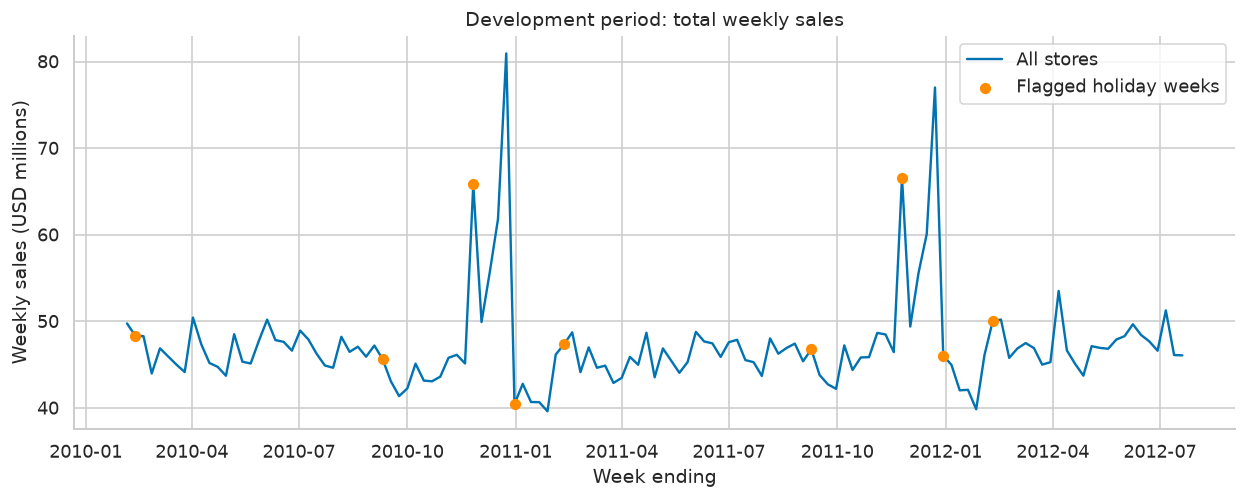

The largest development-period total is **$80.93 million** in the week ending **24 Dec 2010**. Peaks motivate calendar and seasonal-lag features.

In [4]:
weekly = eda.groupby("Date")["Weekly_Sales"].sum()
fig, ax = plt.subplots()
ax.plot(weekly.index, weekly / 1e6, label="All stores")
holiday_weeks = eda.loc[eda["Holiday_Flag"].eq(1), "Date"].unique()
ax.scatter(holiday_weeks, weekly.loc[holiday_weeks] / 1e6, color="darkorange", label="Flagged holiday weeks", zorder=3)
ax.set(title="Development period: total weekly sales", xlabel="Week ending", ylabel="Weekly sales (USD millions)")
ax.legend(); show_plot()
note(f"The largest development-period total is **${weekly.max()/1e6:,.2f} million** "
     f"in the week ending **{weekly.idxmax():%d %b %Y}**. Peaks motivate calendar and seasonal-lag features.")

### 4.2 Store differences and target distribution

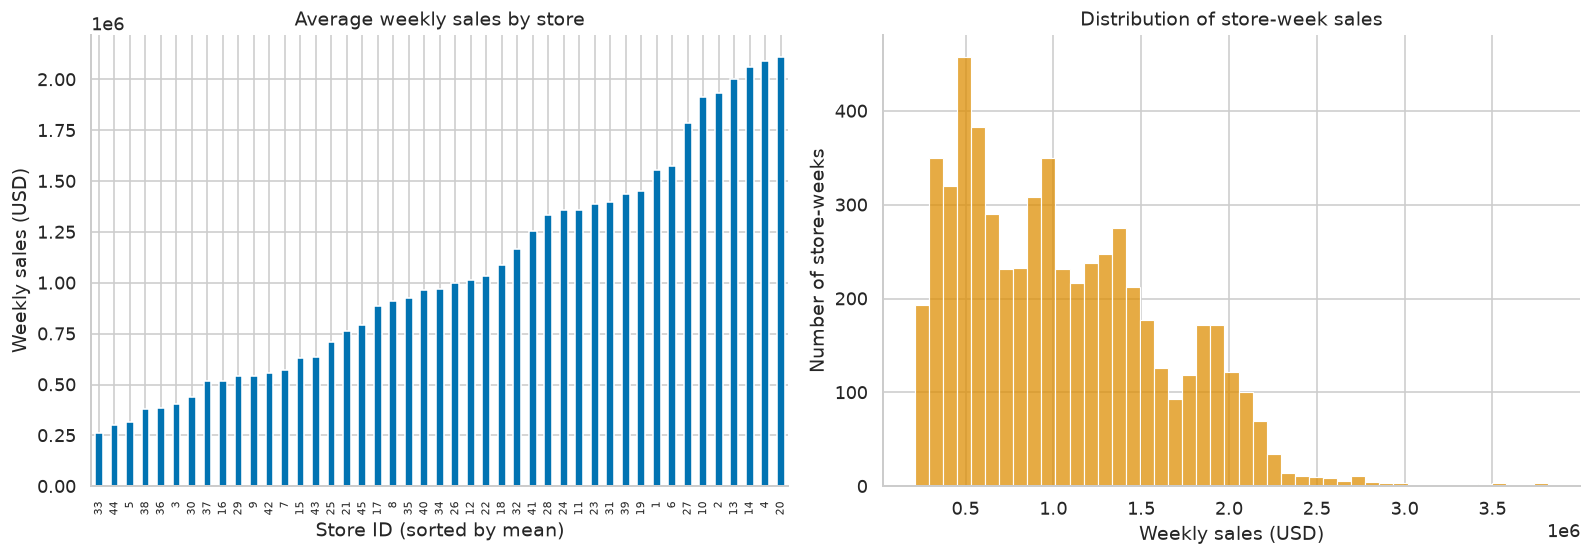

Store **20** has the highest mean (**$2,112,626**); store **33** has the lowest (**$259,497**). The development target has skewness **0.69**. Store identity and store-specific history help account for different revenue scales.

In [5]:
store_means = eda.groupby("Store")["Weekly_Sales"].mean().sort_values()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
store_means.plot.bar(ax=axes[0], color=sns.color_palette()[0])
axes[0].set(title="Average weekly sales by store", xlabel="Store ID (sorted by mean)", ylabel="Weekly sales (USD)")
axes[0].tick_params(axis="x", labelsize=7)
sns.histplot(eda["Weekly_Sales"], bins=45, ax=axes[1], color=sns.color_palette()[1])
axes[1].set(title="Distribution of store-week sales", xlabel="Weekly sales (USD)", ylabel="Number of store-weeks")
show_plot()
note(f"Store **{store_means.idxmax()}** has the highest mean (**${store_means.max():,.0f}**); "
     f"store **{store_means.idxmin()}** has the lowest (**${store_means.min():,.0f}**). "
     f"The development target has skewness **{eda['Weekly_Sales'].skew():.2f}**. "
     "Store identity and store-specific history help account for different revenue scales.")

### 4.3 Holiday, monthly, and seasonal patterns

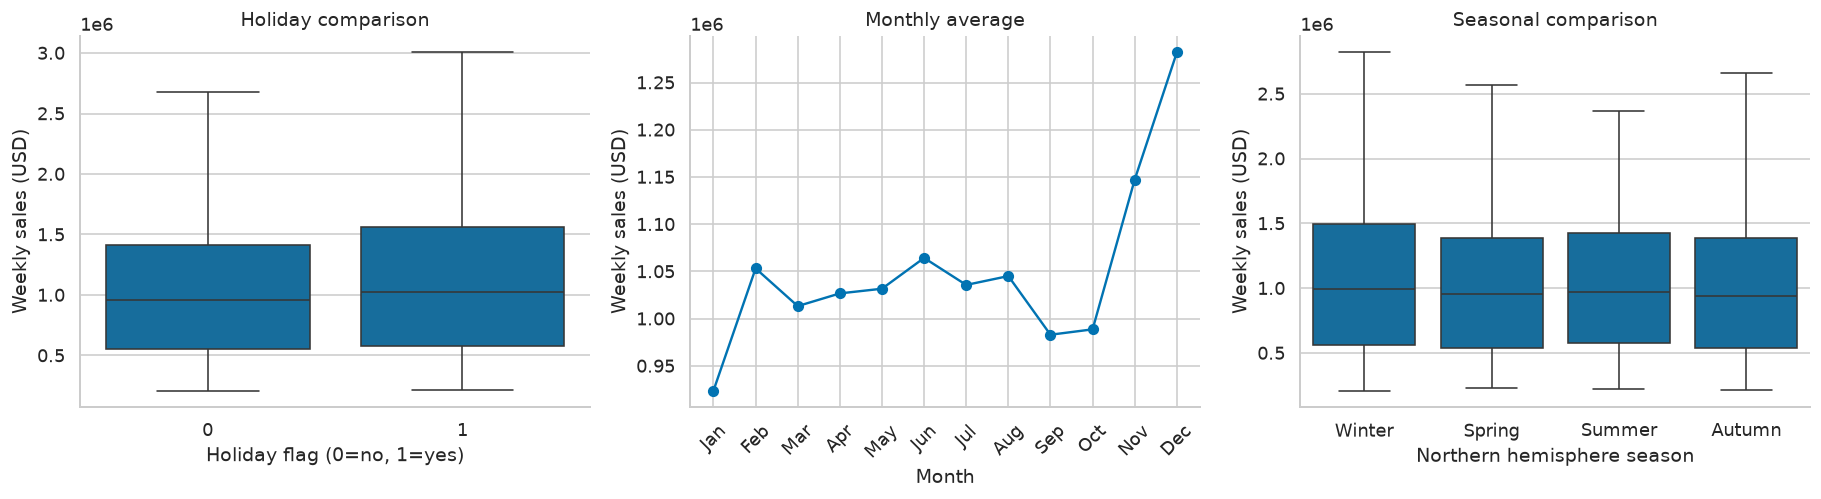

Flagged holiday weeks average **+8.1%** relative to non-holiday weeks. The highest monthly mean occurs in **Dec**. These unadjusted comparisons mix store effects and calendar composition. There are fewer than three annual cycles, and the holiday flag does not mark every shopping peak. Boxplot outliers are hidden for readability, not deleted.

In [6]:
month_order = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
season_map = {12:"Winter",1:"Winter",2:"Winter",3:"Spring",4:"Spring",5:"Spring",
              6:"Summer",7:"Summer",8:"Summer",9:"Autumn",10:"Autumn",11:"Autumn"}
eda["Month"] = eda["Date"].dt.month
eda["Season"] = eda["Month"].map(season_map)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.boxplot(data=eda, x="Holiday_Flag", y="Weekly_Sales", showfliers=False, ax=axes[0])
axes[0].set(title="Holiday comparison", xlabel="Holiday flag (0=no, 1=yes)", ylabel="Weekly sales (USD)")
monthly = eda.groupby("Month")["Weekly_Sales"].mean().reindex(range(1, 13))
axes[1].plot(range(1, 13), monthly, marker="o")
axes[1].set(xticks=range(1,13), xticklabels=month_order, title="Monthly average", xlabel="Month", ylabel="Weekly sales (USD)")
axes[1].tick_params(axis="x", rotation=45)
sns.boxplot(data=eda, x="Season", y="Weekly_Sales", order=["Winter", "Spring", "Summer", "Autumn"], showfliers=False, ax=axes[2])
axes[2].set(title="Seasonal comparison", xlabel="Northern hemisphere season", ylabel="Weekly sales (USD)")
show_plot()
holiday_means = eda.groupby("Holiday_Flag")["Weekly_Sales"].mean()
holiday_lift = (holiday_means.loc[1] / holiday_means.loc[0] - 1) * 100
note(f"Flagged holiday weeks average **{holiday_lift:+.1f}%** relative to non-holiday weeks. "
     f"The highest monthly mean occurs in **{month_order[int(monthly.idxmax())-1]}**. "
     "These unadjusted comparisons mix store effects and calendar composition. "
     "There are fewer than three annual cycles, and the holiday flag does not mark every shopping peak. "
     "Boxplot outliers are hidden for readability, not deleted.")

### 4.4 Relationships and serial dependence

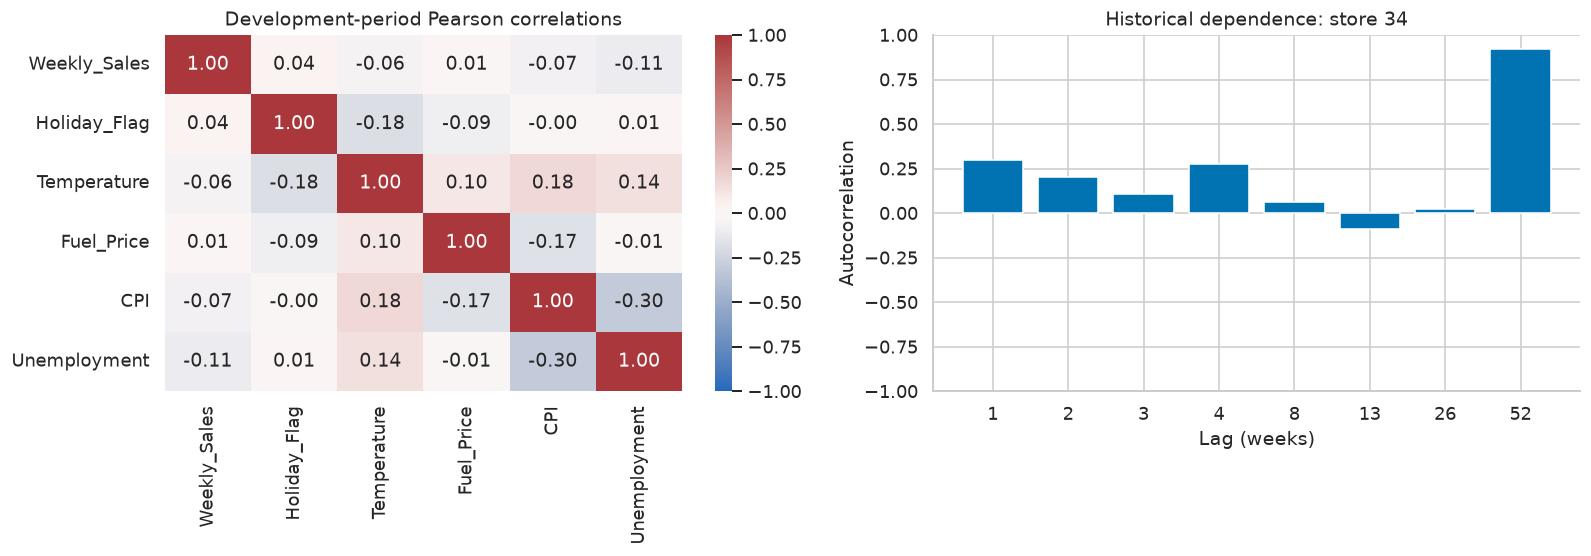

Among the plotted non-target variables, **Unemployment** has the largest absolute pooled correlation with sales (**-0.11**). Pooled correlations can reflect store differences and do not establish causality. Contemporaneous weather/economic values are excluded from forecasting because their future values and release timing are not established. Autocorrelation motivates lagged-sales baselines and features.

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
corr_cols = ["Weekly_Sales", "Holiday_Flag", "Temperature", "Fuel_Price", "CPI", "Unemployment"]
sns.heatmap(eda[corr_cols].corr(), annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Development-period Pearson correlations")
example_store = int(store_means.index[len(store_means)//2])
series = eda.loc[eda["Store"].eq(example_store), "Weekly_Sales"]
lags_to_plot = [1,2,3,4,8,13,26,52]
autocorr = pd.Series({lag: series.autocorr(lag) for lag in lags_to_plot})
axes[1].bar(autocorr.index.astype(str), autocorr)
axes[1].set(title=f"Historical dependence: store {example_store}", xlabel="Lag (weeks)", ylabel="Autocorrelation", ylim=(-1,1))
show_plot()
strongest = eda[corr_cols].corr()["Weekly_Sales"].drop("Weekly_Sales").abs().idxmax()
note(f"Among the plotted non-target variables, **{strongest}** has the largest absolute pooled correlation "
     f"with sales (**{eda[corr_cols].corr().loc[strongest, 'Weekly_Sales']:.2f}**). "
     "Pooled correlations can reflect store differences and do not establish causality. "
     "Contemporaneous weather/economic values are excluded from forecasting because their future values "
     "and release timing are not established. Autocorrelation motivates lagged-sales baselines and features.")

## 5. Leakage-Safe Feature Engineering
Each row represents target sales for its own date *t*. Its features use only store sales through *t−1*, plus calendar information known in advance.

| Feature group | Definition | Available at prediction time? |
|---|---|---|
| Store | One-hot store identifier | Yes; existing stores only |
| Calendar | Month, ISO week, year, elapsed weeks, cyclic week encoding | Yes |
| Planned holiday | Predeclared benchmark holiday schedule | Yes, if the calendar is maintained |
| Sales history | Lags 1, 2, 3, 4, 13, 26, 51, 52, 53 weeks | Yes, once previous weeks are finalized |
| Rolling history | Mean over prior 4, 8, 13 weeks; 4-week standard deviation | Yes; shifted before rolling |
| Prior-year window | Mean of lags 51–53 | Yes |
| Weather and economics | Same-week temperature, fuel, CPI, unemployment | Excluded; unknown future/as-of availability |

The holiday table below encodes benchmark reporting weeks rather than inferring future flags from future target rows. It covers 2010–2012, including the next forecast date, and is checked against the supplied historical flags. Future use outside that calendar requires a maintained schedule.

The first 53 weeks per store have insufficient history and are excluded from the supervised sample, not from the original dataset or EDA. A 52-week lag is 364 days earlier; it is a seasonal approximation, not a perfect calendar-year match.

In [8]:
HOLIDAY_DATES = pd.to_datetime([
    "2010-02-12", "2010-09-10", "2010-11-26", "2010-12-31",
    "2011-02-11", "2011-09-09", "2011-11-25", "2011-12-30",
    "2012-02-10", "2012-09-07", "2012-11-23", "2012-12-28",
])
LAGS = [1, 2, 3, 4, 13, 26, 51, 52, 53]
ROLL_WINDOWS = [4, 8, 13]
CALENDAR_START = pd.Timestamp("2010-01-01")
CALENDAR_END = pd.Timestamp("2012-12-31")
TIME_ORIGIN = df["Date"].min()

def make_features(frame):
    """Compute predictors with past-only operations independently within each store."""
    out = frame.copy().sort_values(["Store", "Date"]).reset_index(drop=True)
    if not out["Date"].between(CALENDAR_START, CALENDAR_END).all():
        raise ValueError("Extend and verify HOLIDAY_DATES before forecasting outside 2010–2012.")
    out["month"] = out["Date"].dt.month
    out["week_of_year"] = out["Date"].dt.isocalendar().week.astype(int)
    out["year"] = out["Date"].dt.year
    out["time_index"] = (out["Date"] - TIME_ORIGIN).dt.days // 7
    out["week_sin"] = np.sin(2 * np.pi * out["week_of_year"] / 52.1775)
    out["week_cos"] = np.cos(2 * np.pi * out["week_of_year"] / 52.1775)
    out["planned_holiday"] = out["Date"].isin(HOLIDAY_DATES).astype(int)
    grouped = out.groupby("Store", sort=False)["Weekly_Sales"]
    for lag in LAGS:
        out[f"sales_lag_{lag}"] = grouped.shift(lag)
    for window in ROLL_WINDOWS:
        out[f"rolling_mean_{window}"] = grouped.transform(
            lambda s: s.shift(1).rolling(window, min_periods=window).mean())
    out["rolling_std_4"] = grouped.transform(lambda s: s.shift(1).rolling(4).std())
    out["prior_year_mean_3"] = out[["sales_lag_51", "sales_lag_52", "sales_lag_53"]].mean(axis=1, skipna=False)
    return out

FEATURES = ["Store", "month", "week_of_year", "year", "time_index", "week_sin", "week_cos", "planned_holiday"]
FEATURES += [f"sales_lag_{lag}" for lag in LAGS]
FEATURES += [f"rolling_mean_{w}" for w in ROLL_WINDOWS] + ["rolling_std_4", "prior_year_mean_3"]
engineered = make_features(df)
assert engineered["planned_holiday"].eq(engineered["Holiday_Flag"]).all()
model_data = engineered.dropna(subset=FEATURES + ["Weekly_Sales"]).sort_values(["Date", "Store"]).reset_index(drop=True)
assert len(model_data) == 45 * (143 - max(LAGS))
assert not {"Weekly_Sales", "Holiday_Flag", "Temperature", "Fuel_Price", "CPI", "Unemployment"}.intersection(FEATURES)
display(model_data[["Store", "Date", "Weekly_Sales", "sales_lag_1", "sales_lag_52", "rolling_mean_4"]].head())
print(f"Supervised sample: {len(model_data):,} rows; {len(FEATURES)} raw predictors.")

,Store,Date,Weekly_Sales,sales_lag_1,sales_lag_52,rolling_mean_4
0,1,2011-02-11,"1,649,614.930","1,606,629.580","1,641,957.440","1,410,487.067"
1,2,2011-02-11,"2,168,041.610","1,929,346.230","2,137,809.500","1,780,074.097"
2,3,2011-02-11,"430,526.210","438,516.530","420,728.960","383,830.142"
3,4,2011-02-11,"2,187,847.290","2,119,086.040","2,188,307.390","1,921,305.823"
4,5,2011-02-11,"311,590.540","329,613.200","311,825.700","286,162.910"


Supervised sample: 4,050 rows; 22 raw predictors.


### 5.1 Verify the information boundary
A future-target perturbation test changes every target at or after an origin. Features at that origin must remain identical. Earlier features must also remain identical; later origins may legitimately change once altered observations become history. Manual spot checks verify store-specific lag and rolling alignment.

In [9]:
probe_date = TEST_START
altered = df.copy()
altered.loc[altered["Date"] >= probe_date, "Weekly_Sales"] += 10_000_000
changed_features = make_features(altered)
check_rows = engineered["Date"] <= probe_date
pd.testing.assert_frame_equal(engineered.loc[check_rows, FEATURES], changed_features.loc[check_rows, FEATURES])
for store in [1, 23, 45]:
    original = df.loc[df["Store"].eq(store)].reset_index(drop=True)
    observed = engineered.loc[engineered["Store"].eq(store)].reset_index(drop=True)
    i = 70
    assert observed.loc[i, "sales_lag_1"] == original.loc[i-1, "Weekly_Sales"]
    assert np.isclose(observed.loc[i, "rolling_mean_4"], original.loc[i-4:i-1, "Weekly_Sales"].mean())
    assert observed.loc[i, "sales_lag_52"] == original.loc[i-52, "Weekly_Sales"]
print("PASS: future-target perturbation, store-specific lags, and shifted rolling-window checks.")

PASS: future-target perturbation, store-specific lags, and shifted rolling-window checks.


## 6. Chronological Train/Test Split and Validation
The last 14 distinct weekly dates form the test set. All stores for a date stay together. Three expanding training windows each predict a following 10-week validation block. Splitting is performed on **unique dates**, then mapped to rows, so stores from the same week never straddle a boundary.

This is a **rolling one-week-ahead protocol with fixed model parameters**: the model is fitted before a validation/test block, and each later week's features may use finalized actual sales from preceding weeks in that block. Those observations were available at that later origin. No model is refitted on holdout labels during evaluation. This does not estimate a 14-week forecast made all at once; that would require recursive prediction and separate evaluation.

No gap is necessary for this target alignment: training week *t−1* is observed before forecasting week *t*, assuming immediate reporting. A real reporting delay requires lag adjustments and possibly a gap.

In [10]:
development = model_data.loc[model_data["Date"] < TEST_START].copy().reset_index(drop=True)
test = model_data.loc[model_data["Date"] >= TEST_START].copy().reset_index(drop=True)
X_dev, y_dev = development[FEATURES], development["Weekly_Sales"]
X_test, y_test = test[FEATURES], test["Weekly_Sales"]
dev_dates = pd.DatetimeIndex(sorted(development["Date"].unique()))
cv_splits, split_rows = [], []
for fold, (train_di, val_di) in enumerate(TimeSeriesSplit(n_splits=3, test_size=10).split(dev_dates), 1):
    train_d, val_d = dev_dates[train_di], dev_dates[val_di]
    train_idx = np.flatnonzero(development["Date"].isin(train_d).to_numpy())
    val_idx = np.flatnonzero(development["Date"].isin(val_d).to_numpy())
    assert train_d.max() < val_d.min() < TEST_START
    assert len(train_idx) == len(train_d) * 45 and len(val_idx) == len(val_d) * 45
    cv_splits.append((train_idx, val_idx))
    split_rows.append({"Fold": fold, "Train start": train_d.min().date(), "Train end": train_d.max().date(),
                       "Validation start": val_d.min().date(), "Validation end": val_d.max().date(),
                       "Train rows": len(train_idx), "Validation rows": len(val_idx)})
assert set(development["Date"]).isdisjoint(set(test["Date"]))
assert len(test) == TEST_WEEKS * 45
print(f"Development: {len(development):,} rows / {len(dev_dates)} weeks")
print(f"Test: {len(test):,} rows / {test['Date'].nunique()} weeks ({test['Date'].min():%d %b %Y}–{test['Date'].max():%d %b %Y})")
display(pd.DataFrame(split_rows))

Development: 3,420 rows / 76 weeks
Test: 630 rows / 14 weeks (27 Jul 2012–26 Oct 2012)


,Fold,Train start,Train end,Validation start,Validation end,Train rows,Validation rows
0,1,2011-02-11,2011-12-23,2011-12-30,2012-03-02,2070,450
1,2,2011-02-11,2012-03-02,2012-03-09,2012-05-11,2520,450
2,3,2011-02-11,2012-05-11,2012-05-18,2012-07-20,2970,450


## 7. Model Training and Sensible Hyperparameter Tuning
**Baselines.** Last-week persistence predicts lag 1. Seasonal persistence predicts lag 52. Strong baselines reveal whether machine learning adds value.

**Random Forest** averages randomized regression trees. **Gradient Boosting** adds small trees to correct earlier residuals. **XGBoost** is regularized gradient-boosted trees with efficient histogram training.

Each ML family tries three configurations across the same three folds (27 CV fits total). Mean validation MAE is the prespecified primary selection criterion. WAPE shares the absolute-error numerator but weights larger stores more than a mean of store percentage errors; RMSE emphasizes large misses. Use one-hot store encoding fitted inside each training pipeline. Trees do not require feature scaling. Data were verified complete, so no imputer is needed. CPU threads are bounded; no GPU is required.

In [11]:
def metrics(y_true, y_pred):
    actual = np.asarray(y_true, dtype=float)
    pred = np.asarray(y_pred, dtype=float)
    assert actual.shape == pred.shape and np.isfinite(pred).all()
    denominator = np.abs(actual).sum()
    return {"MAE": mean_absolute_error(actual, pred),
            "RMSE": np.sqrt(mean_squared_error(actual, pred)),
            "WAPE (%)": 100 * np.abs(actual - pred).sum() / denominator if denominator else np.nan,
            "R2": r2_score(actual, pred) if len(actual) > 1 else np.nan}

NUMERIC = [c for c in FEATURES if c != "Store"]
def pipeline_for(estimator, feature_columns=None):
    columns = FEATURES if feature_columns is None else list(feature_columns)
    numeric_columns = [c for c in columns if c != "Store"]
    preprocessing = ColumnTransformer([
        ("store", OneHotEncoder(handle_unknown="error", sparse_output=False), ["Store"]),
        ("numeric", "passthrough", numeric_columns),
    ], verbose_feature_names_out=True)
    return Pipeline([("preprocess", preprocessing), ("model", estimator)])

estimators = {
    "Random Forest": RandomForestRegressor(n_estimators=160, random_state=SEED, n_jobs=2),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=180, learning_rate=0.05, loss="squared_error", random_state=SEED),
    "XGBoost": XGBRegressor(objective="reg:squarederror", tree_method="hist", n_estimators=250,
                           learning_rate=0.05, subsample=1.0, colsample_bytree=1.0, random_state=SEED, n_jobs=2),
}
parameter_options = {
    "Random Forest": [{"max_depth": 10, "min_samples_leaf": 2}, {"max_depth": 16, "min_samples_leaf": 2}, {"max_depth": None, "min_samples_leaf": 1}],
    "Gradient Boosting": [{"max_depth": 2, "min_samples_leaf": 8}, {"max_depth": 3, "min_samples_leaf": 5}, {"max_depth": 4, "min_samples_leaf": 5}],
    "XGBoost": [{"max_depth": 2, "min_child_weight": 5, "reg_lambda": 5}, {"max_depth": 3, "min_child_weight": 5, "reg_lambda": 5}, {"max_depth": 4, "min_child_weight": 8, "reg_lambda": 10}],
}
baseline_columns = {"Last-week baseline": "sales_lag_1", "Seasonal baseline": "sales_lag_52"}
cv_records = []
for name, column in baseline_columns.items():
    for fold, (_, va) in enumerate(cv_splits, 1):
        cv_records.append({"Model": name, "Candidate": 0, "Fold": fold, "Parameters": "historical persistence",
                           **metrics(y_dev.iloc[va], X_dev.iloc[va][column])})

for name, estimator in estimators.items():
    family_start = time.perf_counter()
    for candidate_id, parameters in enumerate(parameter_options[name]):
        for fold, (tr, va) in enumerate(cv_splits, 1):
            pipeline = pipeline_for(clone(estimator).set_params(**parameters))
            pipeline.fit(X_dev.iloc[tr], y_dev.iloc[tr])
            pred = pipeline.predict(X_dev.iloc[va])
            cv_records.append({"Model": name, "Candidate": candidate_id, "Fold": fold,
                               "Parameters": json.dumps(parameters, sort_keys=True), **metrics(y_dev.iloc[va], pred)})
    print(f"{name}: 9 validation fits completed in {time.perf_counter()-family_start:.1f}s")

cv_results = pd.DataFrame(cv_records)
candidate_summary = cv_results.groupby(["Model", "Candidate", "Parameters"], as_index=False).agg(
    CV_MAE=("MAE", "mean"), CV_MAE_SD=("MAE", "std"), CV_RMSE=("RMSE", "mean"), CV_WAPE=("WAPE (%)", "mean"))
best_rows = candidate_summary.loc[candidate_summary.groupby("Model")["CV_MAE"].idxmin()].sort_values("CV_MAE").reset_index(drop=True)
SELECTED_MODEL = best_rows.iloc[0]["Model"]
BEST_ML_MODEL = best_rows.loc[best_rows["Model"].isin(estimators)].iloc[0]["Model"]
selected_parameters = {row.Model: json.loads(row.Parameters) for row in best_rows.itertuples() if row.Model in estimators}
display(best_rows)
note(f"**Selected before looking at test results: {SELECTED_MODEL}.** "
     f"The best ML family on validation is **{BEST_ML_MODEL}**. "
     "A baseline remains eligible for deployment if it wins validation. "
     "Fold standard deviations describe temporal variation, not a confidence interval from independent samples.")

Random Forest: 9 validation fits completed in 11.7s


Gradient Boosting: 9 validation fits completed in 13.6s


XGBoost: 9 validation fits completed in 1.0s


,Model,Candidate,Parameters,CV_MAE,CV_MAE_SD,CV_RMSE,CV_WAPE
0,Random Forest,1,"{""max_depth"": 16, ""min_samples_leaf"": 2}","52,631.908","16,200.083","82,711.012",5.105
1,Gradient Boosting,2,"{""max_depth"": 4, ""min_samples_leaf"": 5}","56,038.391","16,835.542","84,707.581",5.434
2,XGBoost,0,"{""max_depth"": 2, ""min_child_weight"": 5, ""reg_l...","57,506.653","15,406.656","87,044.739",5.573
3,Seasonal baseline,0,historical persistence,"60,992.074","7,948.917","87,783.196",5.881
4,Last-week baseline,0,historical persistence,"86,249.130","43,899.682","157,002.490",8.393


**Selected before looking at test results: Random Forest.** The best ML family on validation is **Random Forest**. A baseline remains eligible for deployment if it wins validation. Fold standard deviations describe temporal variation, not a confidence interval from independent samples.

### 7.1 Additional rolling-origin backtests: no look-ahead tuning
**Preserved decision:** the original validation-selected model, parameters, feature set, and final 14-week holdout are unchanged. These retrospective development diagnostics do not replace that decision.

Four **non-overlapping** outer blocks cover late summer/autumn 2011, the 2011 shopping peak, winter/early spring 2012, and spring/summer 2012. Models use expanding history strictly before each block. Each ML family is retuned at that origin using **two inner chronological folds of four weeks** and the original three-candidate grid; no later outer or final-test labels enter tuning. Parameters stay fixed throughout the outer block while previous weeks' actuals update lag features, preserving the original rolling one-week-ahead definition.

The 53-week lag requirement prevents evaluating 2010 holidays. Only one Thanksgiving/Christmas cycle can be tested; there is no reliable year-to-year seasonal replication. Period lengths and training sizes differ, so differences cannot be attributed to season alone. All stores on a weekly date stay together.

Completed nested backtest: 2011 late summer


Completed nested backtest: 2011 shopping peak


Completed nested backtest: 2012 winter/spring


Completed nested backtest: 2012 spring/summer


,Period,Model,Training end,Evaluation start,Evaluation end,Train weeks,Parameters,Inner MAE
0,2011 late summer,Random Forest,2011-07-29,2011-08-05,2011-09-30,25,"{""max_depth"": 10, ""min_samples_leaf"": 2}","34,200.414"
1,2011 late summer,Gradient Boosting,2011-07-29,2011-08-05,2011-09-30,25,"{""max_depth"": 4, ""min_samples_leaf"": 5}","39,024.512"
2,2011 late summer,XGBoost,2011-07-29,2011-08-05,2011-09-30,25,"{""max_depth"": 4, ""min_child_weight"": 8, ""reg_l...","40,221.185"
3,2011 late summer,Last-week baseline,2011-07-29,2011-08-05,2011-09-30,25,{},NaN
4,2011 late summer,Seasonal baseline,2011-07-29,2011-08-05,2011-09-30,25,{},NaN
5,2011 shopping peak,Random Forest,2011-09-30,2011-10-07,2011-12-30,34,"{""max_depth"": null, ""min_samples_leaf"": 1}","44,773.261"
6,2011 shopping peak,Gradient Boosting,2011-09-30,2011-10-07,2011-12-30,34,"{""max_depth"": 4, ""min_samples_leaf"": 5}","43,326.082"
7,2011 shopping peak,XGBoost,2011-09-30,2011-10-07,2011-12-30,34,"{""max_depth"": 4, ""min_child_weight"": 8, ""reg_l...","44,435.549"
8,2011 shopping peak,Last-week baseline,2011-09-30,2011-10-07,2011-12-30,34,{},NaN
9,2011 shopping peak,Seasonal baseline,2011-09-30,2011-10-07,2011-12-30,34,{},NaN


,Period,Model,Weeks,Holiday weeks,MAE,RMSE,WAPE (%),R2
0,2011 late summer,Random Forest,9,1,"44,549.558","70,404.113",4.407,0.982
1,2011 late summer,Gradient Boosting,9,1,"45,279.942","70,921.886",4.479,0.982
2,2011 late summer,XGBoost,9,1,"47,144.717","72,892.142",4.663,0.981
3,2011 late summer,Last-week baseline,9,1,"62,295.107","105,626.160",6.162,0.960
4,2011 late summer,Seasonal baseline,9,1,"56,866.753","86,635.881",5.625,0.973
5,2011 shopping peak,Random Forest,13,2,"130,826.115","248,499.034",11.230,0.863
6,2011 shopping peak,Gradient Boosting,13,2,"129,398.127","238,452.013",11.108,0.873
7,2011 shopping peak,XGBoost,13,2,"138,340.312","256,544.969",11.875,0.853
8,2011 shopping peak,Last-week baseline,13,2,"197,355.397","337,096.844",16.941,0.747
9,2011 shopping peak,Seasonal baseline,13,2,"70,054.383","96,953.170",6.013,0.979


,Model,MAE,RMSE,WAPE (%),R2
3,Seasonal baseline,"61,207.478","88,498.272",5.745,0.977
2,Random Forest,"69,422.135","141,344.310",6.516,0.940
0,Gradient Boosting,"70,489.501","137,922.151",6.616,0.943
4,XGBoost,"74,863.537","147,567.809",7.027,0.935
1,Last-week baseline,"98,545.957","191,208.720",9.250,0.891


,Model,Period_MAE_mean,Period_MAE_SD,Worst_period_MAE,Period_wins
0,Gradient Boosting,"69,701.227","39,945.564","129,398.127",0
1,Last-week baseline,"97,569.084","66,556.211","197,355.397",0
2,Random Forest,"68,736.867","41,488.227","130,826.115",2
3,Seasonal baseline,"60,634.330","8,809.106","70,054.383",2
4,XGBoost,"74,133.394","43,177.098","138,340.312",0


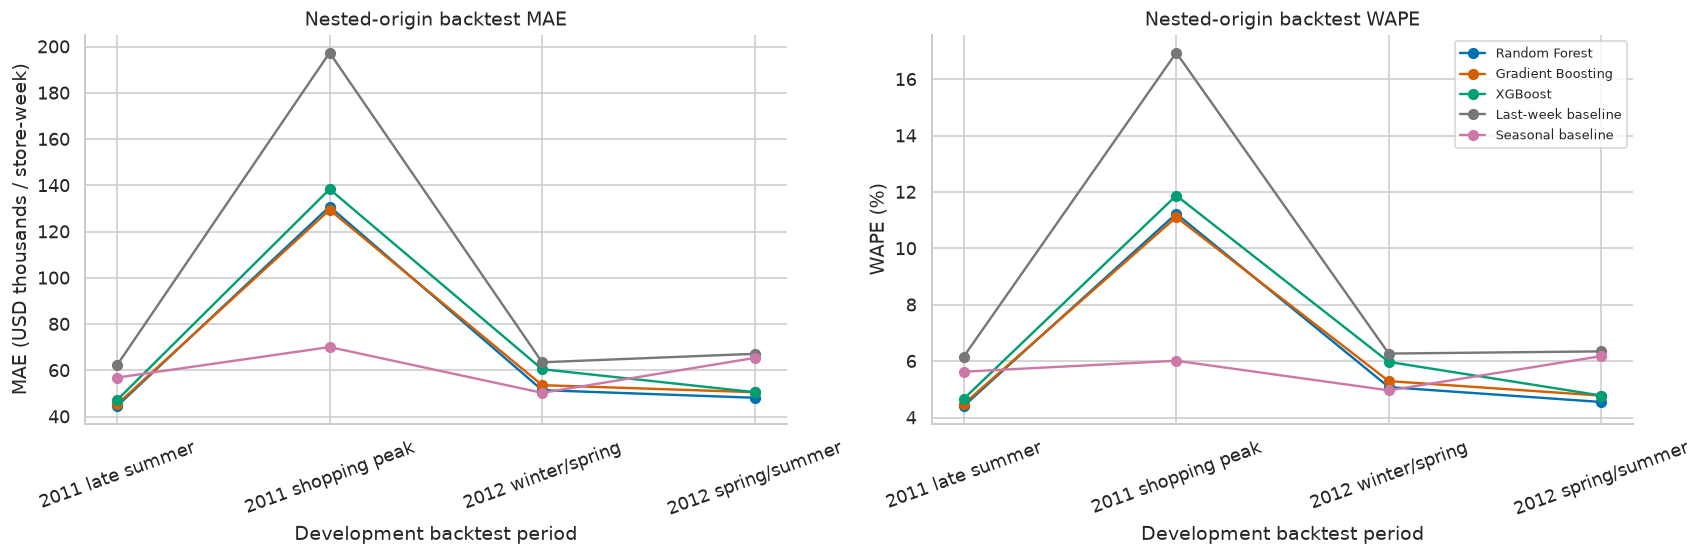

The holiday-window leader is **Seasonal baseline**, with MAE **$70,054.38**. Across all 51 distinct backtest weeks, the lowest pooled MAE belongs to **Seasonal baseline**. Pooled errors weight periods by their observation counts; the unweighted period summary weights each block equally. Rank changes and error dispersion measure sensitivity to the evaluation period, not independent replications of a season.

In [12]:
BACKTEST_PERIODS = [
    ("2011 late summer", "2011-08-05", "2011-09-30"),
    ("2011 shopping peak", "2011-10-07", "2011-12-30"),
    ("2012 winter/spring", "2012-01-06", "2012-03-30"),
    ("2012 spring/summer", "2012-04-06", "2012-07-20"),
]

def tune_on_past(past, model_name, feature_columns=FEATURES):
    """Select parameters using only the supplied chronological history."""
    dates = pd.DatetimeIndex(sorted(past["Date"].unique()))
    inner_splits = list(TimeSeriesSplit(n_splits=2, test_size=4).split(dates))
    scores = []
    for candidate_id, params in enumerate(parameter_options[model_name]):
        losses = []
        for train_di, valid_di in inner_splits:
            tr = past.loc[past["Date"].isin(dates[train_di])]
            va = past.loc[past["Date"].isin(dates[valid_di])]
            assert tr["Date"].max() < va["Date"].min()
            model = pipeline_for(clone(estimators[model_name]).set_params(**params), feature_columns)
            model.fit(tr[feature_columns], tr["Weekly_Sales"])
            losses.append(mean_absolute_error(va["Weekly_Sales"], model.predict(va[feature_columns])))
        scores.append((float(np.mean(losses)), candidate_id))
    _, winner_id = min(scores)
    return dict(parameter_options[model_name][winner_id]), min(scores)[0]

backtest_scores, backtest_predictions, backtest_audit = [], [], []
backtest_models = {}
for period, start_string, end_string in BACKTEST_PERIODS:
    start, end = pd.Timestamp(start_string), pd.Timestamp(end_string)
    past = development.loc[development["Date"] < start].copy()
    block = development.loc[development["Date"].between(start, end)].copy()
    assert len(past) > 0 and len(block) > 0
    assert past["Date"].max() < block["Date"].min() <= block["Date"].max() < TEST_START
    assert block["Date"].nunique() * 45 == len(block)
    for name in list(estimators) + list(baseline_columns):
        if name in estimators:
            params, inner_mae = tune_on_past(past, name)
            model = pipeline_for(clone(estimators[name]).set_params(**params))
            model.fit(past[FEATURES], past["Weekly_Sales"])
            pred = model.predict(block[FEATURES])
            backtest_models[(period, name)] = model
        else:
            params, inner_mae = {}, np.nan
            pred = block[baseline_columns[name]].to_numpy()
        assert len(pred) == len(block) and np.isfinite(pred).all()
        backtest_scores.append({"Period": period, "Model": name, "Weeks": block["Date"].nunique(),
                               "Holiday weeks": block.loc[block["Holiday_Flag"].eq(1), "Date"].nunique(),
                               **metrics(block["Weekly_Sales"], pred)})
        record = block[["Store", "Date", "Weekly_Sales", "Holiday_Flag"]].copy()
        record["Prediction"], record["Period"], record["Model"] = pred, period, name
        backtest_predictions.append(record)
        backtest_audit.append({"Period": period, "Model": name, "Training end": past["Date"].max(),
                               "Evaluation start": block["Date"].min(), "Evaluation end": block["Date"].max(),
                               "Train weeks": past["Date"].nunique(), "Parameters": json.dumps(params, sort_keys=True),
                               "Inner MAE": inner_mae})
    print(f"Completed nested backtest: {period}")
backtest_scores = pd.DataFrame(backtest_scores)
backtest_predictions = pd.concat(backtest_predictions, ignore_index=True)
backtest_audit = pd.DataFrame(backtest_audit)
assert len(backtest_scores) == 4 * 5
assert not backtest_predictions.duplicated(["Model", "Store", "Date"]).any()
assert (backtest_audit["Training end"] < backtest_audit["Evaluation start"]).all()
assert backtest_audit["Evaluation end"].lt(TEST_START).all()
assert {pd.Timestamp("2011-11-25"), pd.Timestamp("2011-12-23"), pd.Timestamp("2011-12-30")}.issubset(set(backtest_predictions["Date"]))
display(backtest_audit)
display(backtest_scores)
backtest_overall = pd.DataFrame([
    {"Model": name, **metrics(g["Weekly_Sales"], g["Prediction"])}
    for name, g in backtest_predictions.groupby("Model")
]).sort_values("MAE")
backtest_rank = backtest_scores.assign(Rank=backtest_scores.groupby("Period")["MAE"].rank(method="min"))
backtest_stability = backtest_rank.groupby("Model", as_index=False).agg(
    Period_MAE_mean=("MAE", "mean"), Period_MAE_SD=("MAE", "std"),
    Worst_period_MAE=("MAE", "max"), Period_wins=("Rank", lambda s: int(s.eq(1).sum())))
display(backtest_overall); display(backtest_stability)
fig, axes = plt.subplots(1, 2, figsize=(15,5))
for name in list(estimators) + list(baseline_columns):
    scores = backtest_scores.loc[backtest_scores["Model"].eq(name)].set_index("Period").reindex([p[0] for p in BACKTEST_PERIODS])
    axes[0].plot(scores.index, scores["MAE"] / 1000, marker="o", label=name, color=MODEL_COLORS[name])
    axes[1].plot(scores.index, scores["WAPE (%)"], marker="o", label=name, color=MODEL_COLORS[name])
for ax in axes:
    ax.tick_params(axis="x", rotation=20)
    ax.set_xlabel("Development backtest period")
axes[0].set(title="Nested-origin backtest MAE", ylabel="MAE (USD thousands / store-week)")
axes[1].set(title="Nested-origin backtest WAPE", ylabel="WAPE (%)")
axes[1].legend(fontsize=8); show_plot()
peak_scores = backtest_scores.loc[backtest_scores["Period"].eq("2011 shopping peak")].sort_values("MAE")
note(f"The holiday-window leader is **{peak_scores.iloc[0]['Model']}**, with MAE **${peak_scores.iloc[0]['MAE']:,.2f}**. "
     f"Across all {backtest_predictions['Date'].nunique()} distinct backtest weeks, the lowest pooled MAE belongs to "
     f"**{backtest_overall.iloc[0]['Model']}**. Pooled errors weight periods by their observation counts; "
     "the unweighted period summary weights each block equally. Rank changes and error dispersion measure "
     "sensitivity to the evaluation period, not independent replications of a season.")

### 7.2 Controlled feature ablation: additional experiment
**A — original:** all original predictors. **B — without previous-year group:** drop `sales_lag_51`, `sales_lag_52`, `sales_lag_53`, and `prior_year_mean_3`.

Use the **same rows, 53-week warm-up, three original validation folds, seed, tree counts, preprocessing, and original full-feature chosen parameters** for both conditions. A reuses the already computed fold results; B is fitted with only its feature columns. Do not shorten B's warm-up or retune B: that would confound feature removal with data volume or tuning. These parameters were selected on these validation folds, so this is a descriptive sensitivity experiment, not an unbiased estimate for a newly selected feature set. The final holdout is excluded and the original model selection is preserved.

Interpret the effect **by validation period**, not only as an average. The fold table and chart below identify how much of the mean deterioration is concentrated in the first block, and whether the later blocks support the same conclusion.

,Model,Experiment,Fold,MAE,RMSE,WAPE (%)
0,Random Forest,A: Original,1,"70,053.175","105,305.540",6.946
1,Random Forest,B: No previous-year,1,"257,541.778","400,599.049",25.535
2,Random Forest,A: Original,2,"49,821.891","82,193.925",4.794
3,Random Forest,B: No previous-year,2,"49,591.289","77,573.658",4.772
4,Random Forest,A: Original,3,"38,020.659","60,633.571",3.574
5,Random Forest,B: No previous-year,3,"40,973.725","61,479.798",3.851
6,Gradient Boosting,A: Original,1,"72,338.741","99,380.729",7.172
7,Gradient Boosting,B: No previous-year,1,"293,362.233","436,158.903",29.087
8,Gradient Boosting,A: Original,2,"57,062.060","93,502.796",5.491
9,Gradient Boosting,B: No previous-year,2,"52,428.293","82,846.790",5.045


,Model,Experiment,MAE,RMSE,WAPE (%)
0,Gradient Boosting,A: Original,"56,038.391","84,707.581",5.434
1,Gradient Boosting,B: No previous-year,"129,259.010","193,847.397",12.693
2,Random Forest,A: Original,"52,631.908","82,711.012",5.105
3,Random Forest,B: No previous-year,"116,035.597","179,884.168",11.386
4,XGBoost,A: Original,"57,506.653","87,044.739",5.573
5,XGBoost,B: No previous-year,"104,807.964","171,138.436",10.258


Experiment,A: Original,B: No previous-year,MAE increase without previous-year (%)
Model,,,
Gradient Boosting,"56,038.391","129,259.010",130.662
Random Forest,"52,631.908","116,035.597",120.466
XGBoost,"57,506.653","104,807.964",82.254


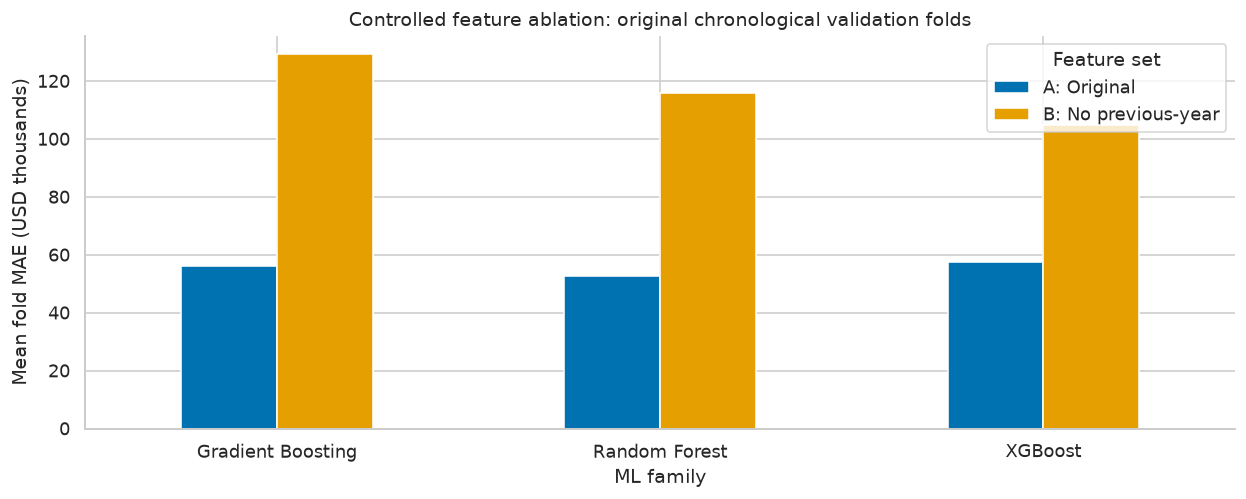

Percentage change in mean validation MAE after removing prior-year features: **Gradient Boosting: +130.7%; Random Forest: +120.5%; XGBoost: +82.3%**. Positive means removal hurts. Correlated remaining lags may compensate partly; effects are conditional on these fixed hyperparameters. This experiment makes no feature-selection change or holdout claim.

PASS: controlled feature groups, development-only folds, and reproducible reduced-model fit.


Experiment,Model,Fold,A: Original,B: No previous-year,MAE delta (USD),MAE change (%),Validation start,Validation end
0,Gradient Boosting,1,"72,338.741","293,362.233","221,023.492",305.540,2011-12-30,2012-03-02
1,Gradient Boosting,2,"57,062.060","52,428.293","-4,633.767",-8.121,2012-03-09,2012-05-11
2,Gradient Boosting,3,"38,714.371","41,986.504","3,272.132",8.452,2012-05-18,2012-07-20
3,Random Forest,1,"70,053.175","257,541.778","187,488.603",267.638,2011-12-30,2012-03-02
4,Random Forest,2,"49,821.891","49,591.289",-230.602,-0.463,2012-03-09,2012-05-11
5,Random Forest,3,"38,020.659","40,973.725","2,953.066",7.767,2012-05-18,2012-07-20
6,XGBoost,1,"72,411.482","212,589.844","140,178.362",193.586,2011-12-30,2012-03-02
7,XGBoost,2,"58,465.518","55,970.877","-2,494.641",-4.267,2012-03-09,2012-05-11
8,XGBoost,3,"41,642.960","45,863.172","4,220.212",10.134,2012-05-18,2012-07-20


,Model,First-fold MAE change (%),First-fold share of net MAE increase (%),Later-fold mean MAE change (%)
0,Gradient Boosting,305.540,100.620,-1.422
1,Random Forest,267.638,98.569,3.099
2,XGBoost,193.586,98.784,1.724


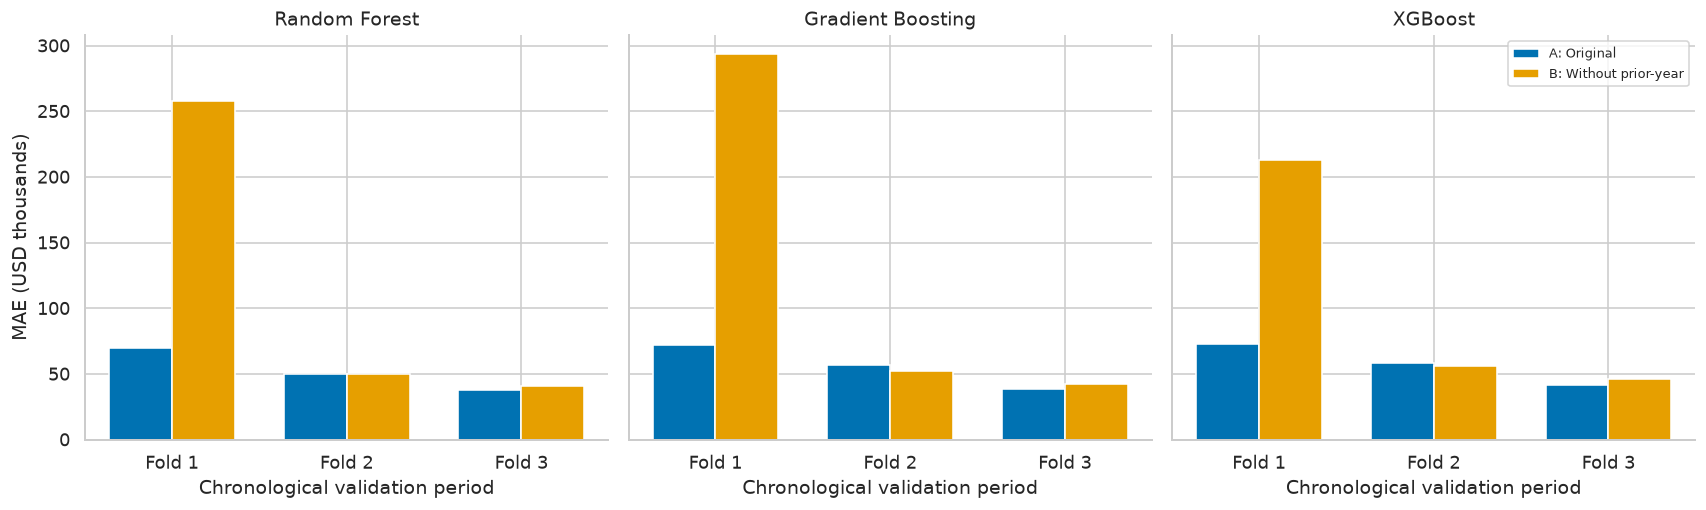

**Period-dependent finding:** the first validation block contributes **Gradient Boosting: 100.6%; Random Forest: 98.6%; XGBoost: 98.8%** of each model's net MAE increase across the three folds. A contribution above 100% means later improvements offset part of the first-fold loss. Later-fold mean changes after removal are **Gradient Boosting: -1.42%; Random Forest: +3.10%; XGBoost: +1.72%**. The large overall average must not be presented as a uniform gain in every period. The first block straddles the year-end/new-year transition; calendar composition, limited annual training history, and fixed full-feature tuning can interact. These are plausible explanations, not demonstrated causes or evidence of universal seasonal-lag superiority.

In [13]:
REMOVED_FEATURES = ["sales_lag_51", "sales_lag_52", "sales_lag_53", "prior_year_mean_3"]
REDUCED_FEATURES = [c for c in FEATURES if c not in REMOVED_FEATURES]
assert set(FEATURES) - set(REDUCED_FEATURES) == set(REMOVED_FEATURES)
ablation_rows, ablation_predictions = [], {}
for name in estimators:
    winner_id = int(best_rows.set_index("Model").loc[name, "Candidate"])
    full_scores = cv_results.loc[cv_results["Model"].eq(name) & cv_results["Candidate"].eq(winner_id)]
    for fold, (tr, va) in enumerate(cv_splits, 1):
        assert development.iloc[tr]["Date"].max() < development.iloc[va]["Date"].min() < TEST_START
        full = full_scores.loc[full_scores["Fold"].eq(fold)].iloc[0]
        ablation_rows.append({"Model": name, "Experiment": "A: Original", "Fold": fold,
                              **{m: full[m] for m in ["MAE", "RMSE", "WAPE (%)"]}})
        reduced_model = pipeline_for(clone(estimators[name]).set_params(**selected_parameters[name]), REDUCED_FEATURES)
        reduced_model.fit(X_dev.iloc[tr][REDUCED_FEATURES], y_dev.iloc[tr])
        pred = reduced_model.predict(X_dev.iloc[va][REDUCED_FEATURES])
        ablation_predictions[(name, fold)] = pred
        ablation_rows.append({"Model": name, "Experiment": "B: No previous-year", "Fold": fold,
                              **{k:v for k,v in metrics(y_dev.iloc[va], pred).items() if k != "R2"}})
ablation_folds = pd.DataFrame(ablation_rows)
ablation_summary = ablation_folds.groupby(["Model", "Experiment"], as_index=False)[["MAE", "RMSE", "WAPE (%)"]].mean()
ablation_delta = ablation_summary.pivot(index="Model", columns="Experiment", values="MAE")
ablation_delta["MAE increase without previous-year (%)"] = (ablation_delta["B: No previous-year"] / ablation_delta["A: Original"] - 1) * 100
display(ablation_folds); display(ablation_summary); display(ablation_delta)
fig, ax = plt.subplots(figsize=(11,4.5))
ablation_summary.pivot(index="Model", columns="Experiment", values="MAE").div(1000).plot.bar(ax=ax, color=["#0072B2", "#E69F00"], rot=0)
ax.set(title="Controlled feature ablation: original chronological validation folds", xlabel="ML family", ylabel="Mean fold MAE (USD thousands)")
ax.legend(title="Feature set"); show_plot()
note("Percentage change in mean validation MAE after removing prior-year features: **" +
     "; ".join(f"{name}: {row['MAE increase without previous-year (%)']:+.1f}%" for name,row in ablation_delta.iterrows()) +
     "**. Positive means removal hurts. Correlated remaining lags may compensate partly; effects are conditional "
     "on these fixed hyperparameters. This experiment makes no feature-selection change or holdout claim.")
# Repeat one reduced fit to verify reproducibility, rather than assuming a fixed seed suffices.
tr, va = cv_splits[0]
repeat_model = pipeline_for(clone(estimators["Random Forest"]).set_params(**selected_parameters["Random Forest"]), REDUCED_FEATURES)
repeat_model.fit(X_dev.iloc[tr][REDUCED_FEATURES], y_dev.iloc[tr])
np.testing.assert_allclose(repeat_model.predict(X_dev.iloc[va][REDUCED_FEATURES]),
                           ablation_predictions[("Random Forest", 1)], rtol=1e-12, atol=1e-7)
print("PASS: controlled feature groups, development-only folds, and reproducible reduced-model fit.")

ablation_period_effects = ablation_folds.pivot(index=["Model","Fold"],columns="Experiment",values="MAE").reset_index()
ablation_period_effects["MAE delta (USD)"] = ablation_period_effects["B: No previous-year"] - ablation_period_effects["A: Original"]
ablation_period_effects["MAE change (%)"] = 100*ablation_period_effects["MAE delta (USD)"]/ablation_period_effects["A: Original"]
fold_dates = {i:(development.iloc[va]["Date"].min(),development.iloc[va]["Date"].max()) for i,(_,va) in enumerate(cv_splits,1)}
ablation_period_effects["Validation start"] = ablation_period_effects["Fold"].map(lambda i:fold_dates[i][0])
ablation_period_effects["Validation end"] = ablation_period_effects["Fold"].map(lambda i:fold_dates[i][1])
ablation_period_summary=[]
for name,g in ablation_period_effects.groupby("Model"):
    first=g.loc[g["Fold"].eq(1)].iloc[0]
    later=g.loc[g["Fold"].gt(1)]
    total_delta=g["MAE delta (USD)"].sum()
    ablation_period_summary.append({"Model":name,"First-fold MAE change (%)":first["MAE change (%)"],
        "First-fold share of net MAE increase (%)":100*first["MAE delta (USD)"]/total_delta,
        "Later-fold mean MAE change (%)":100*(later["B: No previous-year"].mean()/later["A: Original"].mean()-1)})
ablation_period_summary=pd.DataFrame(ablation_period_summary)
display(ablation_period_effects);display(ablation_period_summary)
fig,axes=plt.subplots(1,3,figsize=(15,4.6),sharey=True)
for ax,name in zip(axes,estimators):
    g=ablation_period_effects.loc[ablation_period_effects["Model"].eq(name)]
    positions=np.arange(len(g));width=0.36
    ax.bar(positions-width/2,g["A: Original"]/1000,width,label="A: Original",color="#0072B2")
    ax.bar(positions+width/2,g["B: No previous-year"]/1000,width,label="B: Without prior-year",color="#E69F00")
    ax.set(title=name,xticks=positions,xticklabels=[f"Fold {f}" for f in g["Fold"]],xlabel="Chronological validation period")
axes[0].set_ylabel("MAE (USD thousands)");axes[-1].legend(fontsize=8);show_plot()
note("**Period-dependent finding:** the first validation block contributes **"+
     "; ".join(f"{row['Model']}: {row['First-fold share of net MAE increase (%)']:.1f}%" for _,row in ablation_period_summary.iterrows())+
     "** of each model's net MAE increase across the three folds. A contribution above 100% means later improvements offset part of the first-fold loss. "
     "Later-fold mean changes after removal are **"+
     "; ".join(f"{row['Model']}: {row['Later-fold mean MAE change (%)']:+.2f}%" for _,row in ablation_period_summary.iterrows())+
     "**. The large overall average must not be presented as a uniform gain in every period. "
     "The first block straddles the year-end/new-year transition; calendar composition, limited annual training history, and fixed full-feature tuning can interact. "
     "These are plausible explanations, not demonstrated causes or evidence of universal seasonal-lag superiority.")


## 8. Holdout Evaluation and Model Comparison
Hyperparameters and the selection decision are now frozen. Refit each chosen ML configuration on all development rows and evaluate all five models on the same 630 test observations. The deployed choice is not changed after inspecting holdout rankings. MAE and RMSE use USD; WAPE is `100 × sum(abs(error)) / sum(abs(actual))`; R² is secondary and may be inflated by large differences in store size.

In [14]:
fitted_models, test_predictions, score_rows = {}, {}, []
for name, estimator in estimators.items():
    fitted_models[name] = pipeline_for(clone(estimator).set_params(**selected_parameters[name]))
    fitted_models[name].fit(X_dev, y_dev)
    test_predictions[name] = fitted_models[name].predict(X_test)
for name, column in baseline_columns.items():
    test_predictions[name] = X_test[column].to_numpy()
for name, pred in test_predictions.items():
    score_rows.append({"Model": name, **metrics(y_test, pred)})
comparison = pd.DataFrame(score_rows).merge(best_rows[["Model", "CV_MAE"]], on="Model").sort_values("MAE").reset_index(drop=True)
comparison["Selected on validation"] = comparison["Model"].eq(SELECTED_MODEL)
display(comparison)
selected_scores = metrics(y_test, test_predictions[SELECTED_MODEL])
test_winner = comparison.iloc[0]["Model"]
note(f"The validation-selected **{SELECTED_MODEL}** achieves test MAE **${selected_scores['MAE']:,.2f}**, "
     f"RMSE **${selected_scores['RMSE']:,.2f}**, WAPE **{selected_scores['WAPE (%)']:.2f}%**, "
     f"and R² **{selected_scores['R2']:.4f}**. The lowest test MAE belongs to **{test_winner}**. "
     "This retrospective ranking is reported transparently and is not used to retune or replace the selected model. "
     "WAPE is an error measure, not an accuracy percentage.")

,Model,MAE,RMSE,WAPE (%),R2,CV_MAE,Selected on validation
0,Random Forest,"36,036.479","56,558.728",3.515,0.988,"52,631.908",True
1,Gradient Boosting,"36,167.739","53,824.527",3.527,0.990,"56,038.391",False
2,XGBoost,"40,119.745","59,765.799",3.913,0.987,"57,506.653",False
3,Last-week baseline,"48,895.617","73,367.260",4.769,0.981,"86,249.130",False
4,Seasonal baseline,"52,325.359","83,959.123",5.103,0.974,"60,992.074",False


The validation-selected **Random Forest** achieves test MAE **$36,036.48**, RMSE **$56,558.73**, WAPE **3.51%**, and R² **0.9884**. The lowest test MAE belongs to **Random Forest**. This retrospective ranking is reported transparently and is not used to retune or replace the selected model. WAPE is an error measure, not an accuracy percentage.

### 8.1 Actual versus predicted sales and residuals

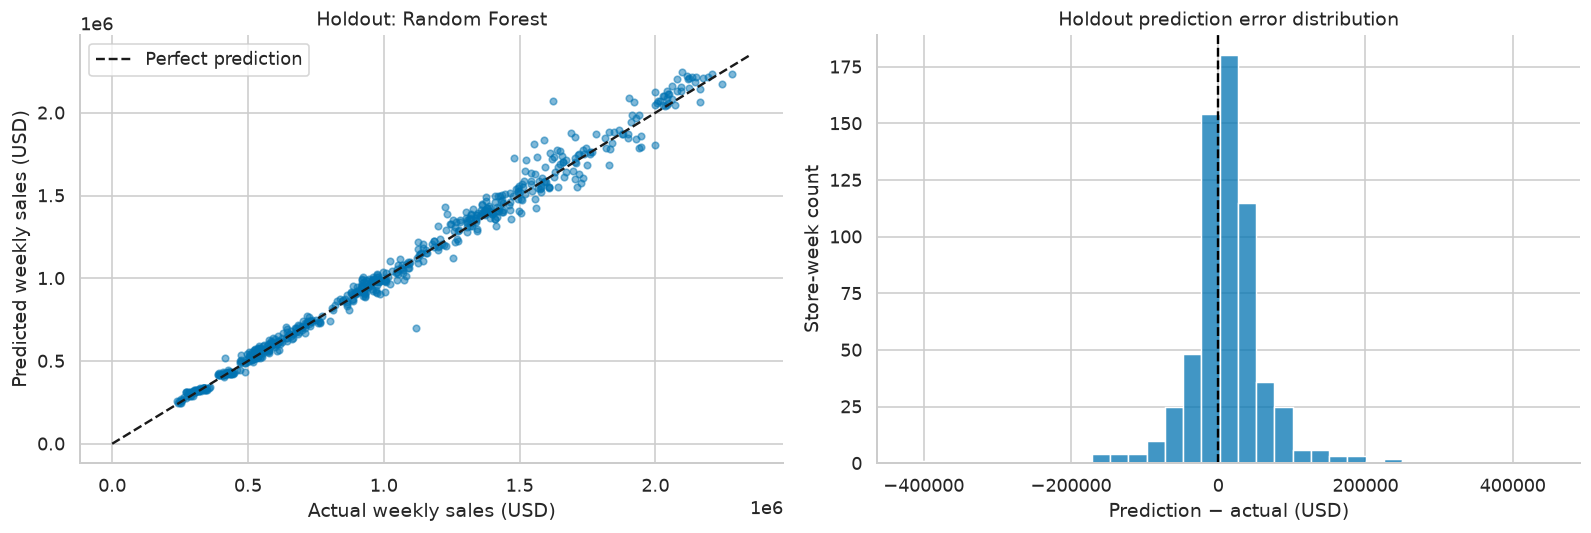

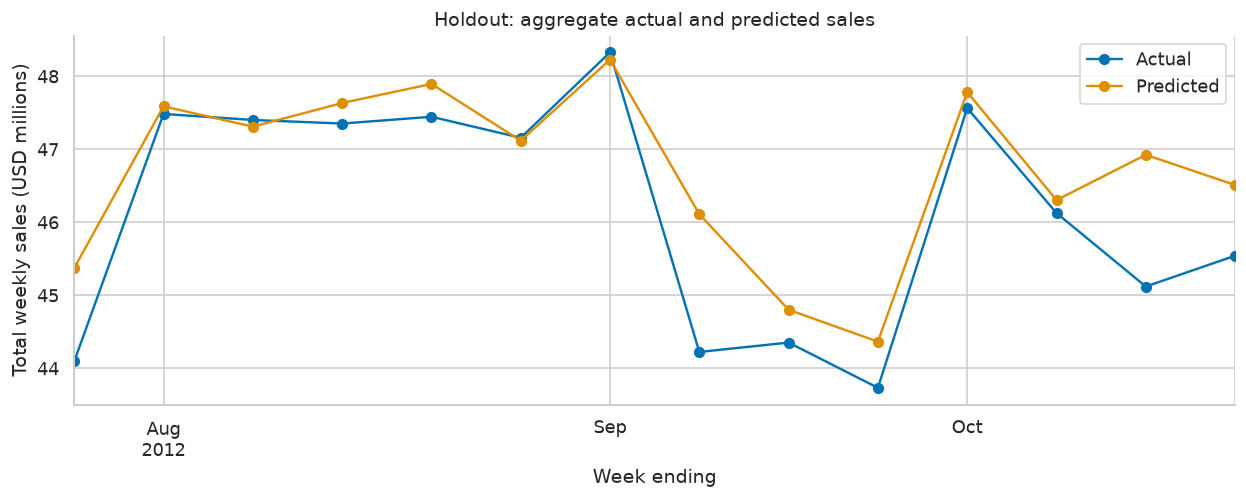

Mean signed error is **$12,730.15** per store-week (positive means overprediction). Aggregation can hide offsetting store errors; the scatter and distribution show the individual observations used for the reported metrics.

In [15]:
evaluation = test[["Store", "Date", "Weekly_Sales", "Holiday_Flag"]].copy()
evaluation["Prediction"] = test_predictions[SELECTED_MODEL]
evaluation["Error"] = evaluation["Prediction"] - evaluation["Weekly_Sales"]
evaluation["Absolute_Error"] = evaluation["Error"].abs()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].scatter(evaluation["Weekly_Sales"], evaluation["Prediction"], alpha=0.5, s=17)
lims = [0, max(evaluation["Weekly_Sales"].max(), evaluation["Prediction"].max()) * 1.03]
axes[0].plot(lims, lims, "k--", label="Perfect prediction")
axes[0].set(title=f"Holdout: {SELECTED_MODEL}", xlabel="Actual weekly sales (USD)", ylabel="Predicted weekly sales (USD)")
axes[0].legend()
sns.histplot(evaluation["Error"], bins=35, ax=axes[1])
axes[1].axvline(0, color="black", linestyle="--")
axes[1].set(title="Holdout prediction error distribution", xlabel="Prediction − actual (USD)", ylabel="Store-week count")
show_plot()
aggregate_eval = evaluation.groupby("Date")[["Weekly_Sales", "Prediction"]].sum()
ax = (aggregate_eval / 1e6).rename(columns={"Weekly_Sales": "Actual", "Prediction": "Predicted"}).plot(marker="o")
ax.set(title="Holdout: aggregate actual and predicted sales", xlabel="Week ending", ylabel="Total weekly sales (USD millions)")
show_plot()
note(f"Mean signed error is **${evaluation['Error'].mean():,.2f}** per store-week "
     "(positive means overprediction). Aggregation can hide offsetting store errors; the scatter and distribution "
     "show the individual observations used for the reported metrics.")

### 8.2 Store-level and holiday-period performance

,Store,Observations,MAE,RMSE,WAPE (%),R2
13,14,14,"180,311.285","206,030.467",11.048,-3.496
35,36,14,"21,984.997","24,439.690",7.580,-2.710
17,18,14,"75,961.010","124,089.591",7.276,-2.495
15,16,14,"26,056.464","29,926.162",4.955,0.323
6,7,14,"28,018.680","32,096.748",4.844,0.779
27,28,14,"58,190.214","78,333.117",4.715,0.536
41,42,14,"23,899.574","28,963.926",4.300,0.420
38,39,14,"66,851.443","79,224.919",4.212,0.153
28,29,14,"21,284.327","33,095.788",4.163,0.412
26,27,14,"67,501.706","79,529.905",4.050,0.243


,Period,Weeks,Store-weeks,MAE,RMSE,WAPE (%),R2
0,Non-holiday,13,585,"35,539.327","56,587.537",3.479,0.988
1,Holiday,1,45,"42,499.449","56,182.870",3.957,0.989


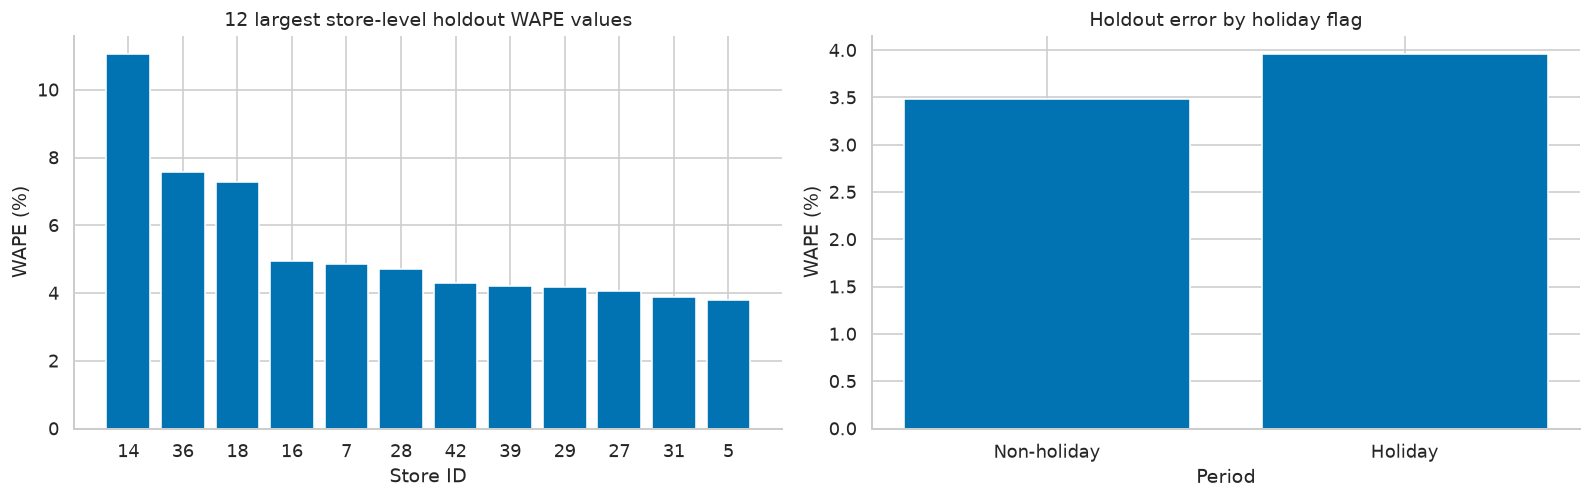

Store-level WAPE ranges from **1.44%** to **11.05%**. The test contains only **1** distinct flagged holiday week(s), so holiday results provide very limited evidence. The 45 store observations on a holiday are not 45 independent holiday events; Thanksgiving and Christmas are absent from this test window.

In [16]:
store_results = pd.DataFrame([
    {"Store": store, "Observations": len(group), **metrics(group["Weekly_Sales"], group["Prediction"])}
    for store, group in evaluation.groupby("Store")
]).sort_values("WAPE (%)", ascending=False)
holiday_results = pd.DataFrame([
    {"Period": "Holiday" if flag else "Non-holiday", "Weeks": group["Date"].nunique(),
     "Store-weeks": len(group), **metrics(group["Weekly_Sales"], group["Prediction"])}
    for flag, group in evaluation.groupby("Holiday_Flag")
])
display(store_results.head(10)); display(holiday_results)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
worst = store_results.head(12)
axes[0].bar(worst["Store"].astype(str), worst["WAPE (%)"])
axes[0].set(title="12 largest store-level holdout WAPE values", xlabel="Store ID", ylabel="WAPE (%)")
axes[1].bar(holiday_results["Period"], holiday_results["WAPE (%)"])
axes[1].set(title="Holdout error by holiday flag", xlabel="Period", ylabel="WAPE (%)")
show_plot()
number_holiday_weeks = evaluation.loc[evaluation["Holiday_Flag"].eq(1), "Date"].nunique()
note(f"Store-level WAPE ranges from **{store_results['WAPE (%)'].min():.2f}%** to "
     f"**{store_results['WAPE (%)'].max():.2f}%**. The test contains only **{number_holiday_weeks}** "
     "distinct flagged holiday week(s), so holiday results provide very limited evidence. "
     "The 45 store observations on a holiday are not 45 independent holiday events; "
     "Thanksgiving and Christmas are absent from this test window.")

### 8.3 Overfitting and generalization

In [17]:
gap_rows = []
for name, pipeline in fitted_models.items():
    train_mae = mean_absolute_error(y_dev, pipeline.predict(X_dev))
    cv_mae = best_rows.set_index("Model").loc[name, "CV_MAE"]
    test_mae = comparison.set_index("Model").loc[name, "MAE"]
    gap_rows.append({"Model": name, "Training MAE": train_mae, "CV MAE": cv_mae,
                     "Test MAE": test_mae, "CV minus training MAE": cv_mae - train_mae})
generalization = pd.DataFrame(gap_rows)
display(generalization)
note("Training error is an optimistic in-sample diagnostic. Lower training error with higher validation error "
     "suggests overfitting, but these periods also differ in season and training-set size. "
     "The holdout covers summer/autumn and is not evidence of year-round performance. "
     "A small tuning grid reduces computation; selecting the best candidate still introduces validation-selection optimism. "
     "More annual cycles and rolling backtests would strengthen conclusions.")

,Model,Training MAE,CV MAE,Test MAE,CV minus training MAE
0,Random Forest,"16,916.045","52,631.908","36,036.479","35,715.863"
1,Gradient Boosting,"28,628.826","56,038.391","36,167.739","27,409.564"
2,XGBoost,"39,528.030","57,506.653","40,119.745","17,978.623"


Training error is an optimistic in-sample diagnostic. Lower training error with higher validation error suggests overfitting, but these periods also differ in season and training-set size. The holdout covers summer/autumn and is not evidence of year-round performance. A small tuning grid reduces computation; selecting the best candidate still introduces validation-selection optimism. More annual cycles and rolling backtests would strengthen conclusions.

### 8.4 Paired model stability: Random Forest versus Gradient Boosting
Aggregate each model's absolute errors **within each week across all 45 stores**, then compute `RF weekly MAE − GB weekly MAE`. A negative difference favors RF. This keeps common weekly shocks together instead of treating 630 store-weeks as independent evidence.

Estimate an **exploratory 95% percentile interval** for the mean paired difference using a seeded **circular block bootstrap** of whole weeks (2, 3, and 4-week blocks; 5,000 resamples). Within-block ordering is preserved, including cross-store dependence through weekly aggregation. Wraparound avoids edge undersampling but creates artificial end-to-start transitions. Stationarity/local dependence are only approximations; with 14 weeks, block-length choices matter and effective information is small. These are descriptive uncertainty estimates, not a significance test or proof of universal superiority. No model is selected or retuned from this comparison.

,Random Forest,Gradient Boosting,RF minus GB (USD)
Date,,,
2012-07-27,"33,356.580","33,487.474",-130.894
2012-08-03,"28,765.527","27,887.771",877.756
2012-08-10,"25,390.461","25,769.667",-379.205
2012-08-17,"33,478.533","34,735.922","-1,257.389"
2012-08-24,"43,268.002","42,224.783","1,043.220"
2012-08-31,"54,350.369","52,445.844","1,904.524"
2012-09-07,"42,499.449","38,692.425","3,807.024"
2012-09-14,"47,040.099","40,142.740","6,897.359"
2012-09-21,"27,674.292","25,937.362","1,736.931"


,Block length (weeks),Mean RF minus GB (USD),95% lower (USD),95% upper (USD)
0,2,-131.260,"-2,992.516","2,369.806"
1,3,-131.260,"-3,196.047","2,616.221"
2,4,-131.260,"-3,211.334","2,774.187"


Model,Gradient Boosting,Random Forest,RF minus GB (USD)
Fold,,,
1,"72,338.741","70,053.175","-2,285.565"
2,"57,062.060","49,821.891","-7,240.169"
3,"38,714.371","38,020.659",-693.713


Model,Random Forest,Gradient Boosting,RF minus GB (USD)
Period,,,
2011 late summer,"44,549.558","45,279.942",-730.383
2011 shopping peak,"130,826.115","129,398.127","1,427.988"
2012 spring/summer,"48,136.674","50,540.167","-2,403.493"
2012 winter/spring,"51,435.121","53,586.672","-2,151.551"


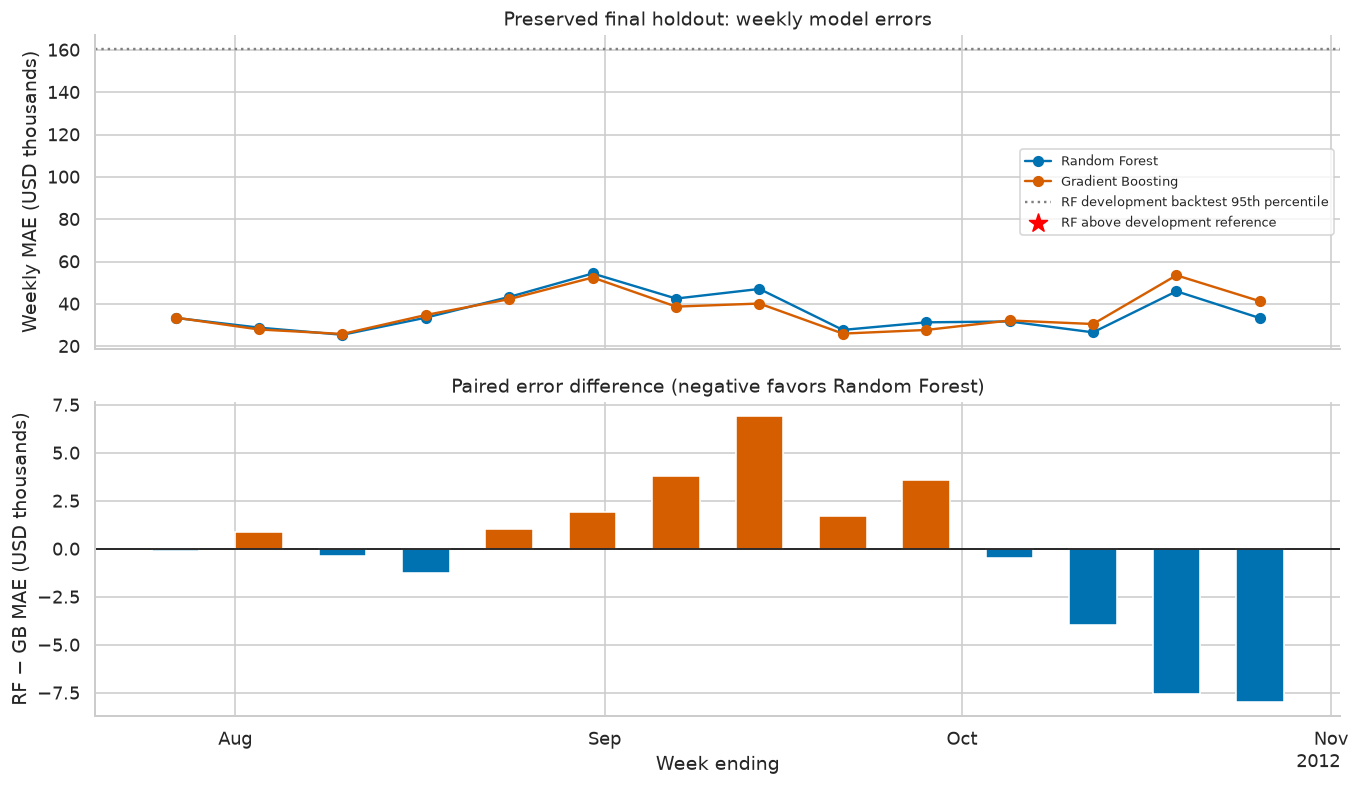

RF wins **7/14 weeks**; GB wins **7/14** (0 ties). RF wins 335/630 individual store-weeks. Mean RF−GB absolute-error difference is **$-131.26** per store-week. The exploratory 3-week-block 95% interval is **[$-3,196.05, $2,616.22]**. It **includes zero**. Period sensitivity and limited seasonal coverage preclude universal superiority claims; the original validation choice remains frozen.

The high-error reference is a development-backtest weekly RF MAE of **$160,258.78** (95th percentile). **0** holdout weeks exceed it. This is a descriptive historical reference, not a calibrated anomaly threshold.

In [18]:
paired_weekly = pd.DataFrame({"Date": test["Date"],
    "Random Forest": np.abs(y_test.to_numpy() - test_predictions["Random Forest"]),
    "Gradient Boosting": np.abs(y_test.to_numpy() - test_predictions["Gradient Boosting"])})
paired_weekly = paired_weekly.groupby("Date")[["Random Forest", "Gradient Boosting"]].mean()
paired_weekly["RF minus GB (USD)"] = paired_weekly["Random Forest"] - paired_weekly["Gradient Boosting"]
paired_difference = paired_weekly["RF minus GB (USD)"]
assert len(paired_difference) == TEST_WEEKS
assert np.isclose(paired_difference.mean(),
    comparison.set_index("Model").loc["Random Forest", "MAE"] - comparison.set_index("Model").loc["Gradient Boosting", "MAE"])

def circular_block_mean_interval(values, block_length, repetitions=5000, seed=SEED):
    values = np.asarray(values, dtype=float)
    assert np.isfinite(values).all() and 1 <= block_length <= len(values)
    rng = np.random.default_rng(seed)
    starts = rng.integers(0, len(values), size=(repetitions, int(np.ceil(len(values) / block_length))))
    indices = ((starts[:, :, None] + np.arange(block_length)) % len(values)).reshape(repetitions, -1)[:, :len(values)]
    means = values[indices].mean(axis=1)
    return np.quantile(means, [0.025, 0.975])

bootstrap_comparison = pd.DataFrame([
    {"Block length (weeks)": b, "Mean RF minus GB (USD)": paired_difference.mean(),
     "95% lower (USD)": circular_block_mean_interval(paired_difference, b)[0],
     "95% upper (USD)": circular_block_mean_interval(paired_difference, b)[1]}
    for b in [2,3,4]
])
np.testing.assert_array_equal(circular_block_mean_interval(paired_difference,3), circular_block_mean_interval(paired_difference,3))
rf_week_wins, gb_week_wins = int(paired_difference.lt(0).sum()), int(paired_difference.gt(0).sum())
rf_storeweek_wins = int((np.abs(y_test.to_numpy()-test_predictions["Random Forest"]) < np.abs(y_test.to_numpy()-test_predictions["Gradient Boosting"])).sum())
display(paired_weekly); display(bootstrap_comparison)
# Compare the same pair on outer backtests and original validation periods.
bt_pair = backtest_scores.pivot(index="Period", columns="Model", values="MAE")[["Random Forest", "Gradient Boosting"]]
bt_pair["RF minus GB (USD)"] = bt_pair["Random Forest"] - bt_pair["Gradient Boosting"]
validation_pair = []
for name in ["Random Forest", "Gradient Boosting"]:
    cid = int(best_rows.set_index("Model").loc[name, "Candidate"])
    validation_pair.append(cv_results.loc[cv_results["Model"].eq(name) & cv_results["Candidate"].eq(cid), ["Model", "Fold", "MAE"]])
validation_pair = pd.concat(validation_pair).pivot(index="Fold", columns="Model", values="MAE")
validation_pair["RF minus GB (USD)"] = validation_pair["Random Forest"] - validation_pair["Gradient Boosting"]
display(validation_pair); display(bt_pair)
fig, axes = plt.subplots(2, 1, figsize=(12,7), sharex=True)
for name in ["Random Forest", "Gradient Boosting"]:
    axes[0].plot(paired_weekly.index, paired_weekly[name]/1000, marker="o", color=MODEL_COLORS[name], label=name)
axes[0].set(title="Preserved final holdout: weekly model errors", ylabel="Weekly MAE (USD thousands)")
bt_week_errors = backtest_predictions.assign(Absolute_error=lambda x: (x["Prediction"]-x["Weekly_Sales"]).abs()).groupby(["Date","Model"])["Absolute_error"].mean().unstack()
HIGH_ERROR_REFERENCE = float(bt_week_errors["Random Forest"].quantile(0.95))
axes[0].axhline(HIGH_ERROR_REFERENCE/1000,color="gray",linestyle=":",label="RF development backtest 95th percentile")
high_weeks = paired_weekly["Random Forest"] > HIGH_ERROR_REFERENCE
axes[0].scatter(paired_weekly.index[high_weeks],paired_weekly.loc[high_weeks,"Random Forest"]/1000,marker="*",s=140,color="red",label="RF above development reference")
axes[0].legend(fontsize=8)
axes[1].bar(paired_difference.index, paired_difference/1000, width=4,
            color=np.where(paired_difference.lt(0), MODEL_COLORS["Random Forest"], MODEL_COLORS["Gradient Boosting"]))
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set(title="Paired error difference (negative favors Random Forest)", xlabel="Week ending", ylabel="RF − GB MAE (USD thousands)")
show_plot()
main_interval = bootstrap_comparison.loc[bootstrap_comparison["Block length (weeks)"].eq(3)].iloc[0]
note(f"RF wins **{rf_week_wins}/{TEST_WEEKS} weeks**; GB wins **{gb_week_wins}/{TEST_WEEKS}** "
     f"({TEST_WEEKS-rf_week_wins-gb_week_wins} ties). RF wins {rf_storeweek_wins}/{len(test)} individual store-weeks. "
     f"Mean RF−GB absolute-error difference is **${paired_difference.mean():,.2f}** per store-week. "
     f"The exploratory 3-week-block 95% interval is **[${main_interval['95% lower (USD)']:,.2f}, "
     f"${main_interval['95% upper (USD)']:,.2f}]**. It **" +
     ("includes zero" if main_interval['95% lower (USD)'] <= 0 <= main_interval['95% upper (USD)'] else "excludes zero under these bootstrap assumptions") +
     "**. Period sensitivity and limited seasonal coverage preclude universal superiority claims; the original validation choice remains frozen.")
note(f"The high-error reference is a development-backtest weekly RF MAE of **${HIGH_ERROR_REFERENCE:,.2f}** (95th percentile). "
     f"**{int(high_weeks.sum())}** holdout weeks exceed it. This is a descriptive historical reference, not a calibrated anomaly threshold.")


### 8.5 Expanded store-level error and bias analysis
Mean signed error uses **prediction − actual**. Relative bias is `100 × sum(prediction − actual) / sum(actual)`. Positive values mean overprediction; negative values mean underprediction. “Consistent” here means the same error direction in at least **75% of the 14 holdout weeks**; this is a configurable descriptive rule, not statistical significance. Best/worst stores are ranked by WAPE so size alone does not determine the ranking.

**Worst five stores by WAPE**

,Store,MAE,RMSE,WAPE (%),R2,Mean signed error (USD),Relative bias (%),Overprediction fraction,Underprediction fraction,Direction pattern
13,14,"180,311.285","206,030.467",11.048,-3.496,"180,311.285",11.048,1.000,0.000,Consistent overprediction
35,36,"21,984.997","24,439.690",7.580,-2.710,"21,984.997",7.580,1.000,0.000,Consistent overprediction
17,18,"75,961.010","124,089.591",7.276,-2.495,"-59,801.951",-5.728,0.214,0.786,Consistent underprediction
15,16,"26,056.464","29,926.162",4.955,0.323,"22,253.181",4.232,0.929,0.071,Consistent overprediction
6,7,"28,018.680","32,096.748",4.844,0.779,"26,071.880",4.507,0.786,0.214,Consistent overprediction


**Best five stores by WAPE**

,Store,MAE,RMSE,WAPE (%),R2,Mean signed error (USD),Relative bias (%),Overprediction fraction,Underprediction fraction,Direction pattern
33,34,"13,787.500","18,114.802",1.439,0.558,"8,115.602",0.847,0.643,0.357,Mixed
36,37,"7,904.054","10,388.078",1.505,0.402,"-4,130.552",-0.786,0.357,0.643,Mixed
42,43,"10,068.974","13,570.420",1.638,0.733,"-2,287.918",-0.372,0.500,0.500,Mixed
5,6,"28,826.293","36,177.910",1.924,0.802,"8,451.842",0.564,0.500,0.500,Mixed
25,26,"20,760.724","28,403.985",2.010,0.719,"19,097.470",1.849,0.929,0.071,Consistent overprediction


**All stores, including error direction**

,Store,MAE,RMSE,WAPE (%),R2,Mean signed error (USD),Relative bias (%),Overprediction fraction,Underprediction fraction,Direction pattern
13,14,"180,311.285","206,030.467",11.048,-3.496,"180,311.285",11.048,1.000,0.000,Consistent overprediction
35,36,"21,984.997","24,439.690",7.580,-2.710,"21,984.997",7.580,1.000,0.000,Consistent overprediction
17,18,"75,961.010","124,089.591",7.276,-2.495,"-59,801.951",-5.728,0.214,0.786,Consistent underprediction
15,16,"26,056.464","29,926.162",4.955,0.323,"22,253.181",4.232,0.929,0.071,Consistent overprediction
6,7,"28,018.680","32,096.748",4.844,0.779,"26,071.880",4.507,0.786,0.214,Consistent overprediction
27,28,"58,190.214","78,333.117",4.715,0.536,"33,554.365",2.719,0.714,0.286,Mixed
41,42,"23,899.574","28,963.926",4.300,0.420,"17,302.806",3.113,0.643,0.357,Mixed
38,39,"66,851.443","79,224.919",4.212,0.153,"-46,596.660",-2.936,0.214,0.786,Consistent underprediction
28,29,"21,284.327","33,095.788",4.163,0.412,"2,164.194",0.423,0.357,0.643,Mixed
26,27,"67,501.706","79,529.905",4.050,0.243,"45,516.179",2.731,0.786,0.214,Consistent overprediction


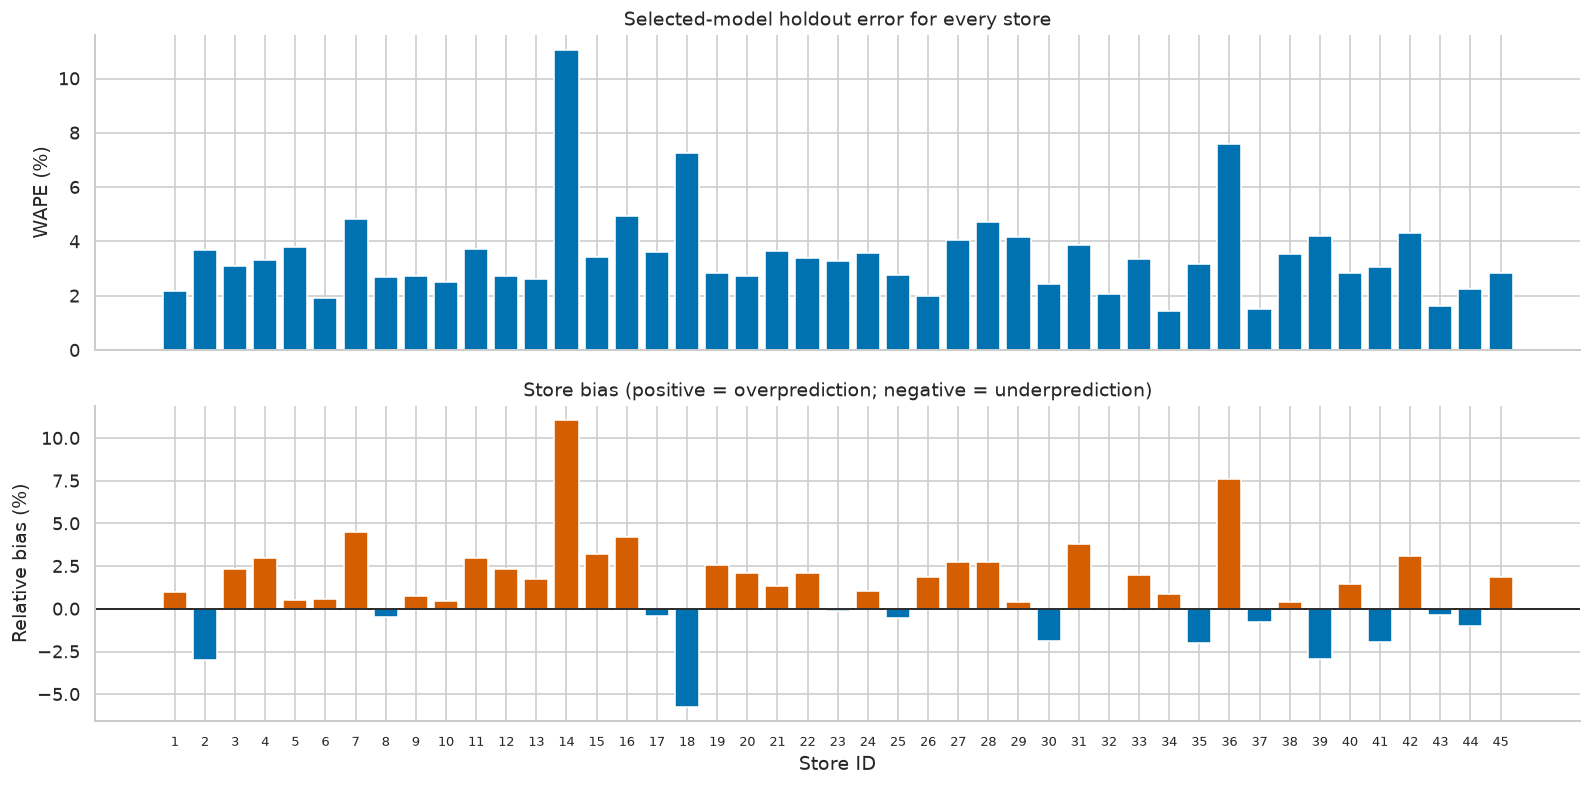

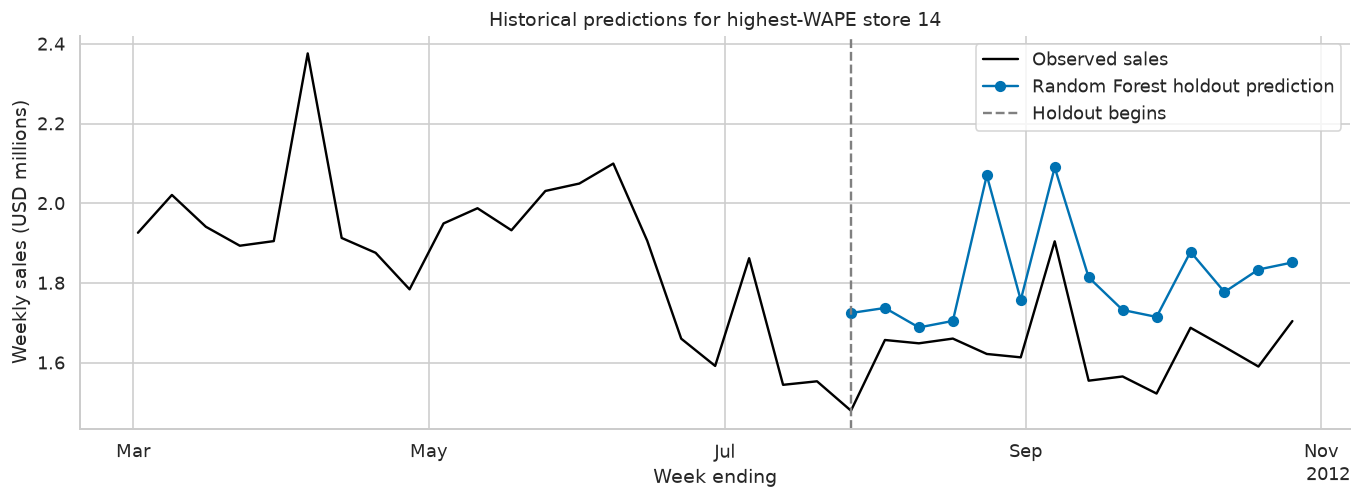

Store **14** has the highest holdout WAPE (**11.05%**). Direction counts: **{"Consistent overprediction": 16, "Consistent underprediction": 4, "Mixed": 25}**. Unrecorded promotions, local demand shifts, stockouts, or a changed seasonal pattern are plausible explanations, but the available data do not identify their causes. This store was selected after observing errors for diagnosis, not as an independent confirmation of performance.

In [19]:
CONSISTENT_SIGN_FRACTION = 0.75
store_diagnostics = pd.DataFrame([
    {"Store": store, **metrics(g["Weekly_Sales"], g["Prediction"]),
     "Mean signed error (USD)": g["Error"].mean(),
     "Relative bias (%)": 100*g["Error"].sum()/g["Weekly_Sales"].sum(),
     "Overprediction fraction": g["Error"].gt(0).mean(),
     "Underprediction fraction": g["Error"].lt(0).mean()}
    for store,g in evaluation.groupby("Store")
]).sort_values("WAPE (%)", ascending=False)
store_diagnostics["Direction pattern"] = np.select([
    store_diagnostics["Overprediction fraction"] >= CONSISTENT_SIGN_FRACTION,
    store_diagnostics["Underprediction fraction"] >= CONSISTENT_SIGN_FRACTION],
    ["Consistent overprediction", "Consistent underprediction"], default="Mixed")
note("**Worst five stores by WAPE**"); display(store_diagnostics.head())
note("**Best five stores by WAPE**"); display(store_diagnostics.tail().sort_values("WAPE (%)"))
note("**All stores, including error direction**"); display(store_diagnostics)
ordered_stores = store_diagnostics.sort_values("Store")
fig, axes = plt.subplots(2,1,figsize=(14,7),sharex=True)
axes[0].bar(ordered_stores["Store"].astype(str), ordered_stores["WAPE (%)"], color=MODEL_COLORS[SELECTED_MODEL])
axes[0].set(title="Selected-model holdout error for every store", ylabel="WAPE (%)")
axes[1].bar(ordered_stores["Store"].astype(str), ordered_stores["Relative bias (%)"],
            color=np.where(ordered_stores["Relative bias (%)"].ge(0), "#D55E00", "#0072B2"))
axes[1].axhline(0,color="black",linewidth=1)
axes[1].set(title="Store bias (positive = overprediction; negative = underprediction)", xlabel="Store ID", ylabel="Relative bias (%)")
axes[1].tick_params(axis="x",labelsize=8); show_plot()
high_error_store = int(store_diagnostics.iloc[0]["Store"])
store_history = df.loc[df["Store"].eq(high_error_store)].tail(35)
store_test = evaluation.loc[evaluation["Store"].eq(high_error_store)]
fig,ax=plt.subplots(figsize=(12,4.5))
ax.plot(store_history["Date"],store_history["Weekly_Sales"]/1e6,label="Observed sales",color="black")
ax.plot(store_test["Date"],store_test["Prediction"]/1e6,label=f"{SELECTED_MODEL} holdout prediction",color=MODEL_COLORS[SELECTED_MODEL],marker="o")
ax.axvline(TEST_START,color="gray",linestyle="--",label="Holdout begins")
ax.set(title=f"Historical predictions for highest-WAPE store {high_error_store}",xlabel="Week ending",ylabel="Weekly sales (USD millions)")
ax.legend(); show_plot()
bias_counts = store_diagnostics["Direction pattern"].value_counts().to_dict()
note(f"Store **{high_error_store}** has the highest holdout WAPE (**{store_diagnostics.iloc[0]['WAPE (%)']:.2f}%**). "
     f"Direction counts: **{json.dumps(bias_counts, sort_keys=True)}**. "
     "Unrecorded promotions, local demand shifts, stockouts, or a changed seasonal pattern are plausible explanations, "
     "but the available data do not identify their causes. This store was selected after observing errors for diagnosis, "
     "not as an independent confirmation of performance.")

### 8.6 Aligned point forecasts, empirical bands, and store-level reliability
**The original five-model comparison remains an immutable benchmark.** For the unified forecast workflow, choose the family and configuration using only inner-validation scores available before 6 April 2012. Estimate relative residuals over the following 16 development weeks using that earlier fitted model. Freeze those settings and residual thresholds, then refit the same learner on all development rows for holdout prediction and on all observed rows for the next-week forecast. **At each origin, one fitted model produces the point forecast and the center of its displayed band.** The unified forecast configuration can differ from the original benchmark winner's configuration; evaluate and label it separately.

These are **empirical residual-transfer bands**, not standard split-conformal intervals. Refitting after calibration changes the fitted function; applying earlier out-of-sample error scales to it is an approximation whose coverage must be checked. Time/store dependence, refit effects, and seasonal drift prevent nominal coverage guarantees. Each store's threshold is the larger of its own finite-order-statistic residual quantile and the pooled quantile. With only 16 calibration weeks per store, the nominal 90% store order statistic is its largest calibration error; this is conservative and unstable, not proof of conditional coverage. No final-test sales set any threshold.

**Overall coverage does not establish individual-store reliability.** First reproduce the previous frozen-model band's failures as a legacy diagnostic, then report the updated workflow's overall and every-store coverage. Highlight stores below the nominal 90% target and retain warnings in their forecast rows. Fourteen test outcomes per store are too few to establish reliable coverage even when observed coverage is high. The design responds to an already-reviewed holdout failure, so the revised coverage is a retrospective diagnostic, not a new independent final test.

,Legacy coverage (%),Test weeks
Store,,
14,7.143,14
36,50.000,14


**Legacy failure retained:** overall coverage was **94.44%**, but store 14 had **7.14%** and store 36 **50.00%**. A pooled headline hid severe conditional failures; it must not be used to claim that every store has a dependable interval.

,Model,Training end,Inner MAE,Parameters
15,Random Forest,2012-03-30,"37,038.921","{""max_depth"": null, ""min_samples_leaf"": 1}"
17,XGBoost,2012-03-30,"42,206.296","{""max_depth"": 4, ""min_child_weight"": 8, ""reg_l..."
16,Gradient Boosting,2012-03-30,"42,247.236","{""max_depth"": 4, ""min_samples_leaf"": 5}"


,Workflow,MAE,RMSE,WAPE (%),R2
0,Original selected benchmark,"36,036.479","56,558.728",3.515,0.988
1,Unified latest-data point/band workflow,"35,909.997","55,967.118",3.502,0.989


,Coverage,Mean_width_USD,Test_weeks,Legacy coverage (%),Updated coverage (%),Below nominal on reviewed holdout
Store,,,,,,
36,0.786,"60,734.949",14,50.000,78.571,True
14,0.929,"787,238.771",14,7.143,92.857,False
18,0.929,"345,476.869",14,85.714,92.857,False
28,0.929,"373,153.329",14,85.714,92.857,False
17,0.929,"285,164.996",14,92.857,92.857,False
5,1.000,"157,806.362",14,100.000,100.000,False
3,1.000,"175,343.144",14,100.000,100.000,False
1,1.000,"518,545.388",14,100.000,100.000,False
8,1.000,"205,248.779",14,100.000,100.000,False


,Coverage,Mean_width_USD,Rows
Holiday_Flag,,,
0,0.990,"340,637.343",585
1,0.978,"343,718.866",45


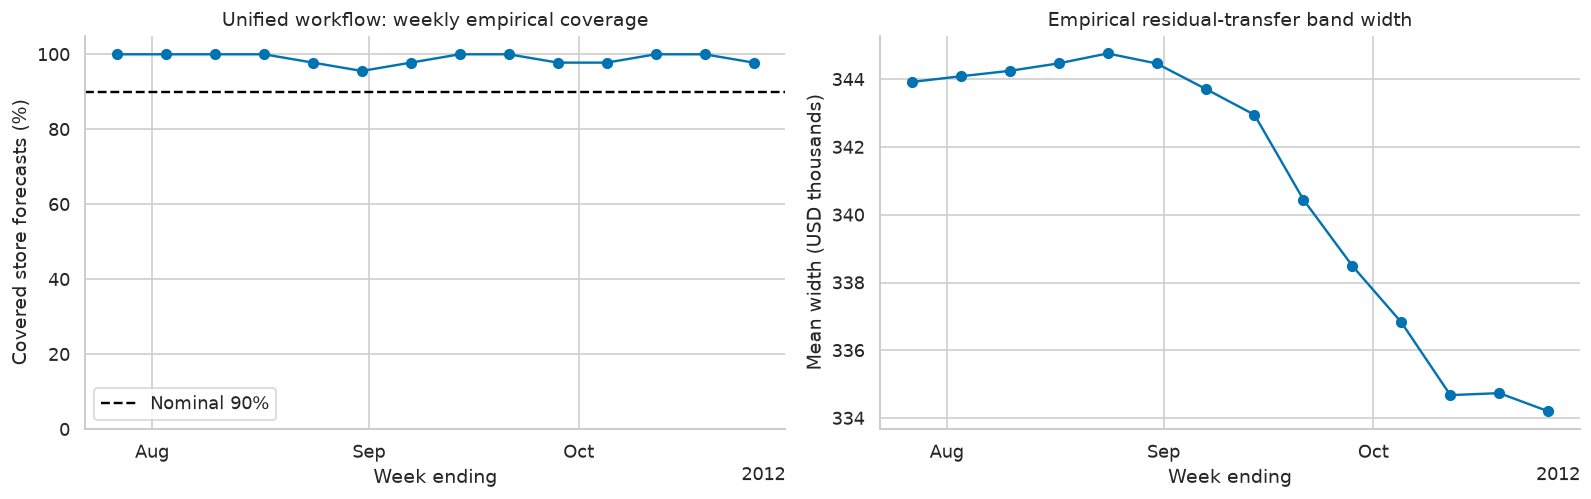

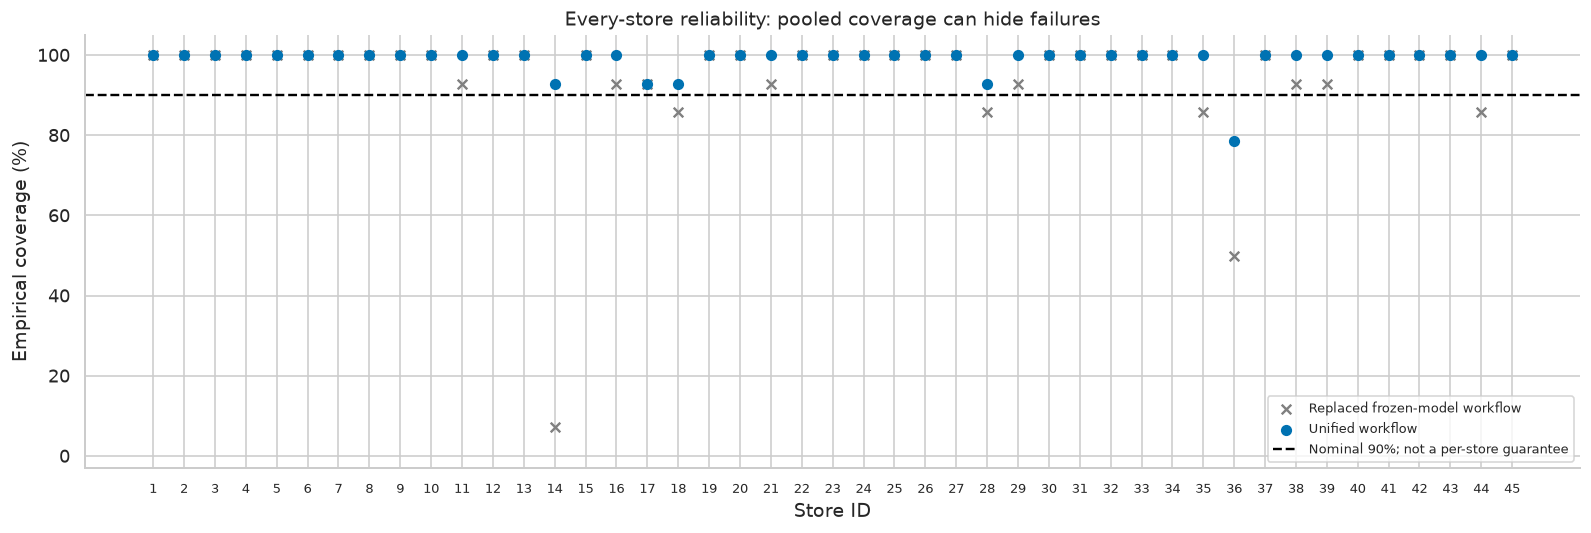

**Updated empirical coverage is 98.89% overall**, with mean width **$340,857.45**. Per-store coverage ranges **78.57%–100.00%**; **Stores below nominal 90%: 1**, IDs **[36]**. Store 14: **92.86%**; store 36: **78.57%**. These bands are not dependable for every individual store. Even a store with 100% observed coverage has only 14 outcomes. Thresholds are not altered after inspecting these failures; future per-store and joint coverage remain unknown.

The higher observed coverage comes with wider bands: mean width rises from **$210,666.28** in the legacy workflow to **$340,857.45**. Wider bands reduce planning precision; coverage alone is not a sufficient quality score.

In [20]:
CALIBRATION_WEEKS = 16
NOMINAL_COVERAGE = 0.90
calibration_dates = dev_dates[-CALIBRATION_WEEKS:]
CALIBRATION_START = calibration_dates[0]
interval_origin_period = "2012 spring/summer"
interval_choices = backtest_audit.loc[
    backtest_audit["Period"].eq(interval_origin_period) & backtest_audit["Model"].isin(estimators)
].sort_values(["Inner MAE","Model"])
assert interval_choices["Evaluation start"].eq(CALIBRATION_START).all()
assert interval_choices["Training end"].lt(CALIBRATION_START).all()
PRODUCTION_MODEL_NAME = INTERVAL_MODEL_NAME = interval_choices.iloc[0]["Model"]
PRODUCTION_PARAMETERS = json.loads(interval_choices.iloc[0]["Parameters"])
calibration_model = backtest_models[(interval_origin_period,PRODUCTION_MODEL_NAME)]
calibration = development.loc[development["Date"].isin(calibration_dates)].copy()
assert interval_choices["Training end"].max() < calibration["Date"].min() <= calibration["Date"].max() < TEST_START
calibration_predictions = calibration_model.predict(calibration[FEATURES])
calibration_scale = calibration["rolling_mean_13"].to_numpy()
assert (calibration_scale>0).all()
calibration_scores = np.abs(calibration["Weekly_Sales"].to_numpy()-calibration_predictions)/calibration_scale

def residual_quantile(scores, coverage=NOMINAL_COVERAGE):
    scores=np.asarray(scores,dtype=float)
    rank=int(np.ceil((len(scores)+1)*coverage))
    assert np.isfinite(scores).all() and 1<=rank<=len(scores)
    return float(np.sort(scores)[rank-1])

INTERVAL_Q = residual_quantile(calibration_scores)
calibration_residuals=calibration[["Store","Date"]].copy()
calibration_residuals["Relative absolute residual"]=calibration_scores
store_interval_q=calibration_residuals.groupby("Store")["Relative absolute residual"].agg(residual_quantile).clip(lower=INTERVAL_Q)
assert calibration_residuals.groupby("Store").size().eq(CALIBRATION_WEEKS).all()
# Reproduce the replaced frozen-model workflow so its poor store coverage is not hidden.
legacy_center=calibration_model.predict(X_test)
legacy_half_width=INTERVAL_Q*test["rolling_mean_13"].to_numpy()
legacy_covered=(y_test.to_numpy()>=np.maximum(0,legacy_center-legacy_half_width)) & (y_test.to_numpy()<=legacy_center+legacy_half_width)
legacy_interval_coverage=float(legacy_covered.mean())
legacy_interval_width=float((legacy_center+legacy_half_width-np.maximum(0,legacy_center-legacy_half_width)).mean())
legacy_store_coverage=pd.Series(legacy_covered,index=test.index).groupby(test["Store"]).mean()
legacy_failure_table=pd.DataFrame({"Legacy coverage (%)":100*legacy_store_coverage.loc[[14,36]],"Test weeks":TEST_WEEKS})
display(legacy_failure_table)
note(f"**Legacy failure retained:** overall coverage was **{100*legacy_interval_coverage:.2f}%**, "
     f"but store 14 had **{100*legacy_store_coverage.loc[14]:.2f}%** and store 36 **{100*legacy_store_coverage.loc[36]:.2f}%**. "
     "A pooled headline hid severe conditional failures; it must not be used to claim that every store has a dependable interval.")

production_test_model=pipeline_for(clone(estimators[PRODUCTION_MODEL_NAME]).set_params(**PRODUCTION_PARAMETERS))
production_test_model.fit(X_dev,y_dev)

def interval_predictions(fitted_model,features):
    """One fitted model supplies both the point prediction and its band center."""
    center=fitted_model.predict(features[FEATURES])
    q=features["Store"].map(store_interval_q).to_numpy()
    scale=features["rolling_mean_13"].to_numpy()
    assert np.isfinite(center).all() and np.isfinite(q).all() and (scale>0).all()
    return center,np.maximum(0,center-q*scale),center+q*scale

interval_center,interval_lower,interval_upper=interval_predictions(production_test_model,test)
np.testing.assert_allclose(interval_center,production_test_model.predict(X_test),rtol=1e-12,atol=1e-7)
production_test_scores=metrics(y_test,interval_center)
interval_evaluation=test[["Store","Date","Weekly_Sales","Holiday_Flag"]].copy()
interval_evaluation["Center"],interval_evaluation["Lower"],interval_evaluation["Upper"]=interval_center,interval_lower,interval_upper
interval_evaluation["Covered"]=interval_evaluation["Weekly_Sales"].between(interval_evaluation["Lower"],interval_evaluation["Upper"])
interval_evaluation["Width (USD)"]=interval_evaluation["Upper"]-interval_evaluation["Lower"]
interval_coverage=float(interval_evaluation["Covered"].mean())
interval_width=float(interval_evaluation["Width (USD)"].mean())
interval_weekly=interval_evaluation.groupby("Date").agg(Coverage=("Covered","mean"),Mean_width_USD=("Width (USD)","mean"))
interval_by_store=interval_evaluation.groupby("Store").agg(Coverage=("Covered","mean"),Mean_width_USD=("Width (USD)","mean"),Test_weeks=("Covered","size"))
interval_by_store["Legacy coverage (%)"]=100*legacy_store_coverage
interval_by_store["Updated coverage (%)"]=100*interval_by_store["Coverage"]
interval_by_store["Below nominal on reviewed holdout"]=interval_by_store["Coverage"]<NOMINAL_COVERAGE
undercovered_stores=interval_by_store.index[interval_by_store["Below nominal on reviewed holdout"]].tolist()
interval_by_holiday=interval_evaluation.groupby("Holiday_Flag").agg(Coverage=("Covered","mean"),Mean_width_USD=("Width (USD)","mean"),Rows=("Covered","size"))
display(interval_choices[["Model","Training end","Inner MAE","Parameters"]])
display(pd.DataFrame([{"Workflow":"Original selected benchmark",**selected_scores},
                     {"Workflow":"Unified latest-data point/band workflow",**production_test_scores}]))
display(interval_by_store.sort_values("Coverage"));display(interval_by_holiday)
fig,axes=plt.subplots(1,2,figsize=(14,4.5))
axes[0].plot(interval_weekly.index,100*interval_weekly["Coverage"],marker="o")
axes[0].axhline(100*NOMINAL_COVERAGE,color="black",linestyle="--",label="Nominal 90%")
axes[0].set(title="Unified workflow: weekly empirical coverage",xlabel="Week ending",ylabel="Covered store forecasts (%)",ylim=(0,105));axes[0].legend()
axes[1].plot(interval_weekly.index,interval_weekly["Mean_width_USD"]/1000,marker="o")
axes[1].set(title="Empirical residual-transfer band width",xlabel="Week ending",ylabel="Mean width (USD thousands)");show_plot()
fig,ax=plt.subplots(figsize=(14,4.8))
x=np.arange(len(interval_by_store))
ax.scatter(x,interval_by_store["Legacy coverage (%)"],color="gray",marker="x",label="Replaced frozen-model workflow")
ax.scatter(x,interval_by_store["Updated coverage (%)"],color="#0072B2",label="Unified workflow")
ax.axhline(90,color="black",linestyle="--",label="Nominal 90%; not a per-store guarantee")
ax.set(xticks=x,xticklabels=interval_by_store.index,title="Every-store reliability: pooled coverage can hide failures",xlabel="Store ID",ylabel="Empirical coverage (%)",ylim=(-3,105))
ax.tick_params(axis="x",labelsize=8);ax.legend(fontsize=8,loc="lower right");show_plot()
note(f"**Updated empirical coverage is {100*interval_coverage:.2f}% overall**, with mean width **${interval_width:,.2f}**. "
     f"Per-store coverage ranges **{100*interval_by_store['Coverage'].min():.2f}%–{100*interval_by_store['Coverage'].max():.2f}%**; "
     f"**Stores below nominal 90%: {len(undercovered_stores)}**, IDs **{undercovered_stores}**. "
     f"Store 14: **{100*interval_by_store.loc[14,'Coverage']:.2f}%**; store 36: **{100*interval_by_store.loc[36,'Coverage']:.2f}%**. "
     "These bands are not dependable for every individual store. Even a store with 100% observed coverage has only 14 outcomes. "
     "Thresholds are not altered after inspecting these failures; future per-store and joint coverage remain unknown.")
note(f"The higher observed coverage comes with wider bands: mean width rises from **${legacy_interval_width:,.2f}** in the legacy workflow to **${interval_width:,.2f}**. Wider bands reduce planning precision; coverage alone is not a sufficient quality score.")

### 8.7 Development-based, configurable business alert thresholds
Measure actual historical sales relative to the **preceding** 13-week mean using development dates only (after 13 weeks of history, without imposing the modeling experiment's 53-week warm-up). Compare the original ±15% rule with lower/upper 5th/95th percentiles of those signed deviations. The quantile rule targets roughly 10% of historical store-weeks as a manageable planning-review rate; that rate is a configurable business choice, not an optimized trading or anomaly-detection objective.

The thresholds are pooled across stores, fitted once on development data, and applied to **forecast** deviations at deployment. Historical actual-deviation frequency need not match future forecast-alert frequency. These are evidence-informed heuristics, not anomaly probabilities. Seasonality and store size can still confound pooled thresholds.

In [21]:
ALERT_CONFIG = {"lower_quantile":0.05, "upper_quantile":0.95, "fixed_reference_pct":15.0}
alert_history = engineered.loc[engineered["Date"].lt(TEST_START)].dropna(subset=["rolling_mean_13"]).copy()
assert alert_history["Date"].max() < TEST_START
alert_history["Deviation (%)"] = (alert_history["Weekly_Sales"] / alert_history["rolling_mean_13"] - 1)*100
ALERT_LOW, ALERT_HIGH = alert_history["Deviation (%)"].quantile([ALERT_CONFIG["lower_quantile"], ALERT_CONFIG["upper_quantile"]]).to_numpy()
assert ALERT_LOW < 0 < ALERT_HIGH
fixed_alert_rate = float((alert_history["Deviation (%)"].abs() >= ALERT_CONFIG["fixed_reference_pct"]).mean())
quantile_alert_rate = float(((alert_history["Deviation (%)"] <= ALERT_LOW) | (alert_history["Deviation (%)"] >= ALERT_HIGH)).mean())
alert_threshold_comparison = pd.DataFrame([
    {"Rule":"Original ±15%", "Low threshold (%)":-15.0,"High threshold (%)":15.0,"Historical trigger (%)":100*fixed_alert_rate},
    {"Rule":"Development 5th/95th quantiles", "Low threshold (%)":ALERT_LOW,"High threshold (%)":ALERT_HIGH,"Historical trigger (%)":100*quantile_alert_rate}])
display(alert_threshold_comparison)
note(f"The original rule triggers on **{100*fixed_alert_rate:.2f}%** of historical development store-weeks. "
     f"The configured quantile thresholds are **{ALERT_LOW:.2f}% / +{ALERT_HIGH:.2f}%**, triggering on "
     f"**{100*quantile_alert_rate:.2f}%**. These reduce or increase review volume according to observed historical deviations; "
     "there is no evidence here that either rule maximizes business value. The quantile rule is used below, "
     "with configuration exposed above and no final-test data used to set it.")

,Rule,Low threshold (%),High threshold (%),Historical trigger (%)
0,Original ±15%,-15.000,15.000,16.303
1,Development 5th/95th quantiles,-18.809,24.174,10.000


The original rule triggers on **16.30%** of historical development store-weeks. The configured quantile thresholds are **-18.81% / +24.17%**, triggering on **10.00%**. These reduce or increase review volume according to observed historical deviations; there is no evidence here that either rule maximizes business value. The quantile rule is used below, with configuration exposed above and no final-test data used to set it.

### 8.8 Do the alerts warn about useful situations?
Backtest alerts using the 51 development outer-test weeks, using the Random Forest predictions already generated with past-only nested tuning. At each block origin, re-estimate quantile thresholds from actual deviations **strictly before that origin**. Compare the quantile rule, the pre-existing fixed ±15% rule, and an always-NORMAL baseline.

Define an independent, configurable **material movement** as actual sales at least ±15% from the preceding 13-week mean. This is a business review proxy chosen before scoring, not a learned anomaly label. Precision measures the fraction of alerts associated with any material movement; recall measures the fraction of material movements warned about. Also report directionally correct alerts/recall, false alarms, missed events, and results by period. Actual sales are used only for scoring. These metrics establish historical warning behavior, not financial value: inventory costs, margins, and intervention outcomes are unavailable. No threshold is selected or retuned using the final holdout or these utility scores. Zero next-week alerts is permitted and is not evidence that warnings are reliable.

,Period,Origin,Threshold history ends,Low (%),High (%)
0,2011 late summer,2011-08-05,2011-07-29,-18.921,23.387
1,2011 shopping peak,2011-10-07,2011-09-30,-18.257,20.540
2,2012 winter/spring,2012-01-06,2011-12-30,-17.284,30.128
3,2012 spring/summer,2012-04-06,2012-03-30,-19.791,26.542


,Rule,Rows,Alerts,Material movements,Hits,False alarms,Missed movements,Warning precision (%),Warning recall (%),Direction-correct alerts,Directional precision (%),Directional recall (%)
0,Always NORMAL,2295,0,396,0,0,396,NaN,0.000,0,NaN,0.000
1,Fixed ±15%,2295,181,396,153,28,243,84.530,38.636,151,83.425,38.131
2,Origin quantiles,2295,97,396,89,8,307,91.753,22.475,89,91.753,22.475


,Period,Rule,Rows,Alerts,Material movements,Hits,False alarms,Missed movements,Warning precision (%),Warning recall (%),Direction-correct alerts,Directional precision (%),Directional recall (%)
0,2011 late summer,Always NORMAL,405,0,16,0,0,16,NaN,0.000,0,NaN,0.000
1,2011 late summer,Fixed ±15%,405,4,16,3,1,13,75.000,18.750,3,75.000,18.750
2,2011 late summer,Origin quantiles,405,2,16,2,0,14,100.000,12.500,2,100.000,12.500
3,2011 shopping peak,Always NORMAL,585,0,164,0,0,164,NaN,0.000,0,NaN,0.000
4,2011 shopping peak,Fixed ±15%,585,77,164,67,10,97,87.013,40.854,65,84.416,39.634
5,2011 shopping peak,Origin quantiles,585,36,164,32,4,132,88.889,19.512,32,88.889,19.512
6,2012 spring/summer,Always NORMAL,720,0,60,0,0,60,NaN,0.000,0,NaN,0.000
7,2012 spring/summer,Fixed ±15%,720,22,60,15,7,45,68.182,25.000,15,68.182,25.000
8,2012 spring/summer,Origin quantiles,720,6,60,5,1,55,83.333,8.333,5,83.333,8.333
9,2012 winter/spring,Always NORMAL,585,0,156,0,0,156,NaN,0.000,0,NaN,0.000


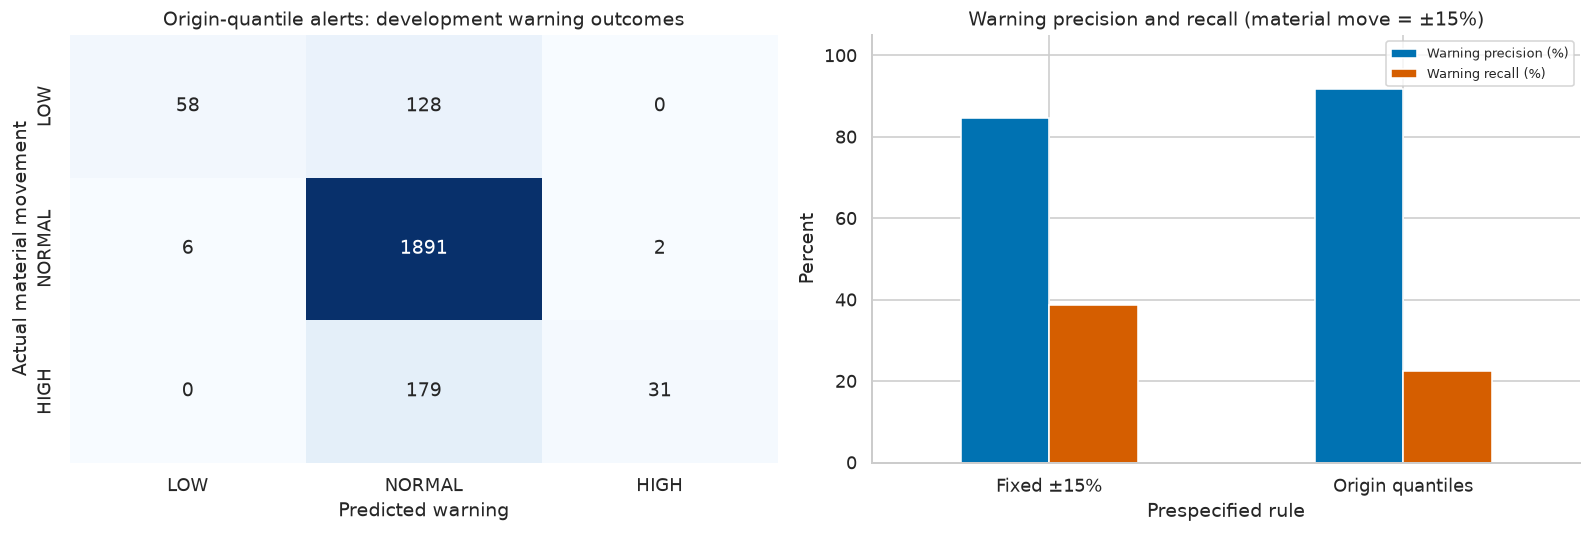

Origin-quantile warnings generate **97 alerts**, with precision **91.75%** and recall **22.47%** for material movements; directional recall is **22.47%**. There are **8 false alarms** and **307 missed material movements**. The fixed rule has precision **84.53%** and recall **38.64%**. The always-NORMAL baseline warns about nothing and has zero recall. Read the per-period table: low review volume can conceal missed warnings. Useful warning behavior must be judged against these tradeoffs; profitable business interventions and universal anomaly detection are not established.

In [22]:
ALERT_EVENT_PCT=15.0

def movement_labels(deviation,low,high):
    return np.select([np.asarray(deviation)<=low,np.asarray(deviation)>=high],["LOW","HIGH"],default="NORMAL")

alert_prediction_rows=[];alert_origin_rows=[]
for period,start_string,end_string in BACKTEST_PERIODS:
    origin=pd.Timestamp(start_string)
    past=alert_history.loc[alert_history["Date"]<origin]
    assert len(past)>0 and past["Date"].max()<origin<TEST_START
    low,high=past["Deviation (%)"].quantile([ALERT_CONFIG["lower_quantile"],ALERT_CONFIG["upper_quantile"]]).to_numpy()
    block=backtest_predictions.loc[backtest_predictions["Period"].eq(period)&backtest_predictions["Model"].eq("Random Forest")].copy()
    block=block.merge(engineered[["Store","Date","rolling_mean_13"]],on=["Store","Date"],validate="one_to_one")
    actual_dev=(block["Weekly_Sales"]/block["rolling_mean_13"]-1)*100
    pred_dev=(block["Prediction"]/block["rolling_mean_13"]-1)*100
    actual_label=movement_labels(actual_dev,-ALERT_EVENT_PCT,ALERT_EVENT_PCT)
    for rule,labels in [
        ("Origin quantiles",movement_labels(pred_dev,low,high)),
        ("Fixed ±15%",movement_labels(pred_dev,-15,15)),
        ("Always NORMAL",np.repeat("NORMAL",len(block)))]:
        rec=block[["Store","Date"]].copy();rec["Period"]=period;rec["Rule"]=rule
        rec["Actual event"]=actual_label;rec["Alert"]=labels
        alert_prediction_rows.append(rec)
    alert_origin_rows.append({"Period":period,"Origin":origin,"Threshold history ends":past["Date"].max(),"Low (%)":low,"High (%)":high})
alert_predictions=pd.concat(alert_prediction_rows,ignore_index=True)
alert_origin_audit=pd.DataFrame(alert_origin_rows)

def alert_utility(group):
    warning=group["Alert"].ne("NORMAL").to_numpy()
    event=group["Actual event"].ne("NORMAL").to_numpy()
    tp=int((warning&event).sum());fp=int((warning&~event).sum())
    fn=int((~warning&event).sum());tn=int((~warning&~event).sum())
    correct=int((warning&group["Alert"].eq(group["Actual event"]).to_numpy()).sum())
    n_alert=int(warning.sum());n_event=int(event.sum())
    assert tp+fp+fn+tn==len(group)
    return {"Rows":len(group),"Alerts":n_alert,"Material movements":n_event,"Hits":tp,"False alarms":fp,"Missed movements":fn,
            "Warning precision (%)":100*tp/n_alert if n_alert else np.nan,
            "Warning recall (%)":100*tp/n_event if n_event else np.nan,
            "Direction-correct alerts":correct,"Directional precision (%)":100*correct/n_alert if n_alert else np.nan,
            "Directional recall (%)":100*correct/n_event if n_event else np.nan}

alert_utility_summary=pd.DataFrame([{"Rule":rule,**alert_utility(g)} for rule,g in alert_predictions.groupby("Rule")])
alert_utility_periods=pd.DataFrame([{"Period":p,"Rule":r,**alert_utility(g)} for (p,r),g in alert_predictions.groupby(["Period","Rule"])])
display(alert_origin_audit);display(alert_utility_summary);display(alert_utility_periods)
alert_confusion=pd.crosstab(alert_predictions.loc[alert_predictions["Rule"].eq("Origin quantiles"),"Actual event"],
    alert_predictions.loc[alert_predictions["Rule"].eq("Origin quantiles"),"Alert"]).reindex(index=["LOW","NORMAL","HIGH"],columns=["LOW","NORMAL","HIGH"],fill_value=0)
fig,axes=plt.subplots(1,2,figsize=(14,4.8))
sns.heatmap(alert_confusion,annot=True,fmt="d",cmap="Blues",cbar=False,ax=axes[0])
axes[0].set(title="Origin-quantile alerts: development warning outcomes",xlabel="Predicted warning",ylabel="Actual material movement")
active=alert_utility_summary.loc[alert_utility_summary["Rule"].ne("Always NORMAL")].set_index("Rule")
active[["Warning precision (%)","Warning recall (%)"]].plot.bar(ax=axes[1],rot=0,color=["#0072B2","#D55E00"])
axes[1].set(title="Warning precision and recall (material move = ±15%)",xlabel="Prespecified rule",ylabel="Percent",ylim=(0,105));axes[1].legend(fontsize=8);show_plot()
quantile_utility=alert_utility_summary.set_index("Rule").loc["Origin quantiles"]
fixed_utility=alert_utility_summary.set_index("Rule").loc["Fixed ±15%"]
note(f"Origin-quantile warnings generate **{int(quantile_utility['Alerts'])} alerts**, with precision **{quantile_utility['Warning precision (%)']:.2f}%** "
     f"and recall **{quantile_utility['Warning recall (%)']:.2f}%** for material movements; directional recall is **{quantile_utility['Directional recall (%)']:.2f}%**. "
     f"There are **{int(quantile_utility['False alarms'])} false alarms** and **{int(quantile_utility['Missed movements'])} missed material movements**. "
     f"The fixed rule has precision **{fixed_utility['Warning precision (%)']:.2f}%** and recall **{fixed_utility['Warning recall (%)']:.2f}%**. "
     "The always-NORMAL baseline warns about nothing and has zero recall. Read the per-period table: low review volume can conceal missed warnings. "
     "Useful warning behavior must be judged against these tradeoffs; profitable business interventions and universal anomaly detection are not established.")

## 9. One-Week-Ahead Forecasts and AI Insights
### 9.1 Feature influence
Permutation importance measures the increase in MAE when one raw feature is shuffled, including store identity as a group through the pipeline. Compute it on the **last validation block**, with a model fitted only on earlier rows. This avoids explaining the tuned model on its own training observations and does not influence selection. Correlated lags can substitute for one another, so importance is model-specific and not causal. Five repeats quantify shuffle variation, not statistical confidence.

The influence study uses the unified forecast configuration, with parameters available before its explanatory validation block. The original benchmark ablation is a separate conditional study.

,Feature,MAE increase (USD),Shuffle SD (USD)
15,sales_lag_52,"356,602.665","10,414.345"
21,prior_year_mean_3,"50,673.539","1,289.137"
18,rolling_mean_8,"19,634.830","1,097.743"
17,rolling_mean_4,"16,736.854",787.091
8,sales_lag_1,"8,882.061",704.051
13,sales_lag_26,"2,660.545",373.799
12,sales_lag_13,"2,115.315",155.830
0,Store,881.106,290.111
11,sales_lag_4,874.283,183.773
19,rolling_mean_13,843.392,271.488


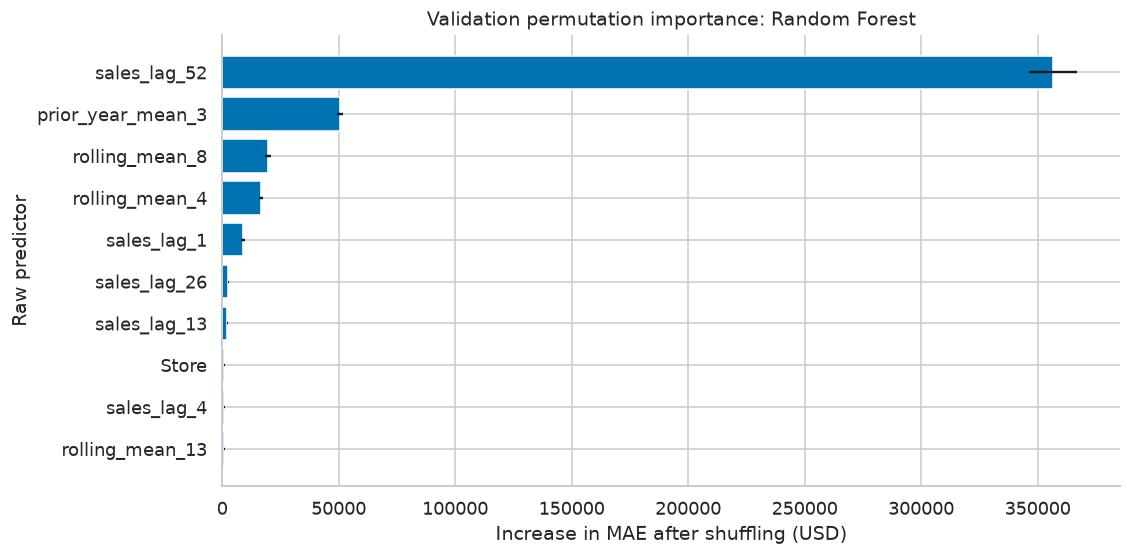

The largest measured permutation effect is for **sales_lag_52**. Negative or near-zero values indicate little consistent benefit in this validation block. This is an explanation of model sensitivity, not evidence that changing that feature would cause sales to change.

**Scope of importance:** this sensitivity plot uses the unified forecast configuration on the last validation block. The controlled ablation uses original benchmark settings and shows a large first-period effect but much smaller, sometimes reversed effects later. Neither result establishes equal benefit from prior-year features in every season.

In [23]:
explain_name = PRODUCTION_MODEL_NAME
tr, va = cv_splits[-1]
explain_model = pipeline_for(clone(estimators[explain_name]).set_params(**PRODUCTION_PARAMETERS))
explain_model.fit(X_dev.iloc[tr], y_dev.iloc[tr])
importance = permutation_importance(explain_model, X_dev.iloc[va], y_dev.iloc[va],
                                  scoring="neg_mean_absolute_error", n_repeats=5, random_state=SEED, n_jobs=1)
importance_table = pd.DataFrame({"Feature": FEATURES, "MAE increase (USD)": importance.importances_mean,
                                 "Shuffle SD (USD)": importance.importances_std}).sort_values("MAE increase (USD)", ascending=False)
display(importance_table.head(12))
plot_importance = importance_table.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(10,5))
ax.barh(plot_importance["Feature"], plot_importance["MAE increase (USD)"], xerr=plot_importance["Shuffle SD (USD)"])
ax.set(title=f"Validation permutation importance: {explain_name}", xlabel="Increase in MAE after shuffling (USD)", ylabel="Raw predictor")
show_plot()
note(f"The largest measured permutation effect is for **{importance_table.iloc[0]['Feature']}**. "
     "Negative or near-zero values indicate little consistent benefit in this validation block. "
     "This is an explanation of model sensitivity, not evidence that changing that feature would cause sales to change.")
note("**Scope of importance:** this sensitivity plot uses the unified forecast configuration on the last validation block. "
     "The controlled ablation uses original benchmark settings and shows a large first-period effect but much smaller, "
     "sometimes reversed effects later. Neither result establishes equal benefit from prior-year features in every season.")


### 9.2 One latest-data model supplies points and band centers
Refit the unified configuration chosen before calibration on all observed labeled rows, then append one target-free row per store. One call returns its point forecast and empirical bounds; the point is exactly the band center before lower-bound clipping. The original benchmark comparison stays unchanged, but its selected hyperparameters and test scores are not silently assigned to this revised forecast workflow. Forecast rows carry explicit store-level band cautions. Alerts remain configurable heuristics backed by the development warning study.

,Store,Date,Prior 13-week mean (USD),Forecast (USD),Nominal 90% lower (USD),Nominal 90% upper (USD),Change vs recent mean (%),Alert,Band caution,Status
0,1,2012-11-02,"1,558,891.415","1,682,235.048","1,425,469.724","1,939,000.372",7.912,NORMAL,Only 14 reviewed outcomes; no per-store guarantee,MODEL FORECAST — actual unobserved
1,2,2012-11-02,"1,879,668.994","1,908,072.077","1,643,662.854","2,172,481.299",1.511,NORMAL,Only 14 reviewed outcomes; no per-store guarantee,MODEL FORECAST — actual unobserved
2,3,2012-11-02,"410,180.072","447,200.172","360,597.613","533,802.730",9.025,NORMAL,Only 14 reviewed outcomes; no per-store guarantee,MODEL FORECAST — actual unobserved
3,4,2012-11-02,"2,141,352.772","2,222,449.651","1,925,965.172","2,518,934.131",3.787,NORMAL,Only 14 reviewed outcomes; no per-store guarantee,MODEL FORECAST — actual unobserved
4,5,2012-11-02,"321,511.005","329,548.046","251,663.800","407,432.292",2.500,NORMAL,Only 14 reviewed outcomes; no per-store guarantee,MODEL FORECAST — actual unobserved
5,6,2012-11-02,"1,497,008.026","1,546,215.432","1,246,877.988","1,845,552.876",3.287,NORMAL,Only 14 reviewed outcomes; no per-store guarantee,MODEL FORECAST — actual unobserved
6,7,2012-11-02,"570,118.877","554,264.312","469,938.603","638,590.022",-2.781,NORMAL,Only 14 reviewed outcomes; no per-store guarantee,MODEL FORECAST — actual unobserved
7,8,2012-11-02,"914,702.062","952,333.480","848,708.659","1,055,958.301",4.114,NORMAL,Only 14 reviewed outcomes; no per-store guarantee,MODEL FORECAST — actual unobserved
8,9,2012-11-02,"550,295.388","602,771.841","498,663.449","706,880.233",9.536,NORMAL,Only 14 reviewed outcomes; no per-store guarantee,MODEL FORECAST — actual unobserved
9,10,2012-11-02,"1,748,473.902","1,866,020.191","1,630,923.568","2,101,116.815",6.723,NORMAL,Only 14 reviewed outcomes; no per-store guarantee,MODEL FORECAST — actual unobserved


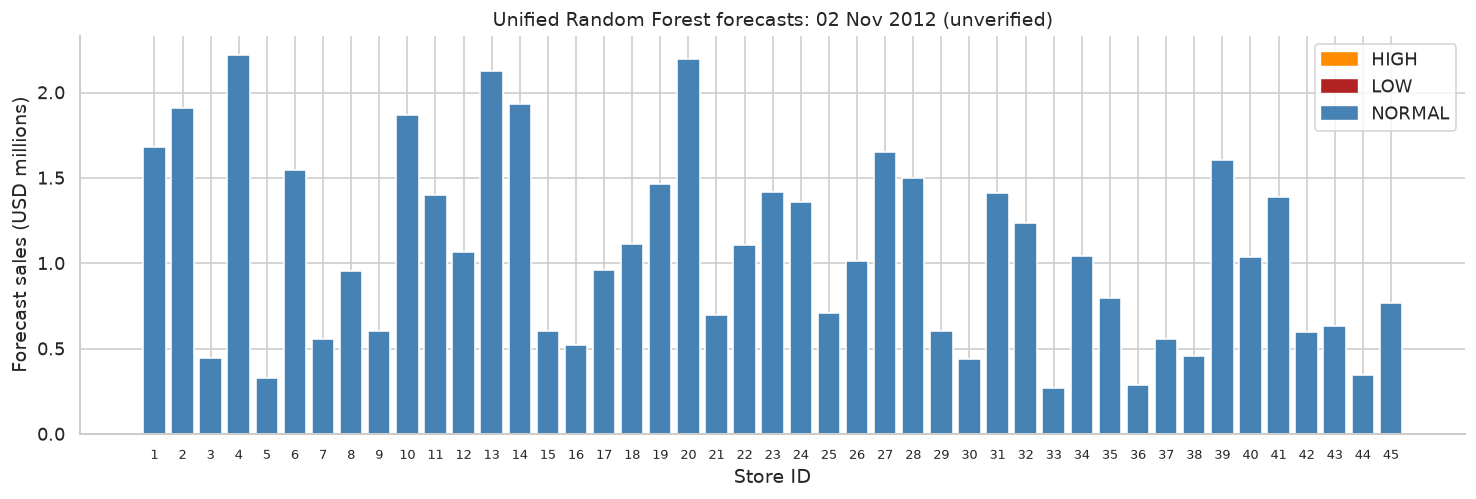

One latest-data fitted **Random Forest** supplies all 45 point forecasts and band centers. Forecast total: **$48,403,697.38**. Alert counts: **{"NORMAL": 45}**. No actuals for the date exist in the supplied file. NORMAL is not an assurance of low risk: warning recall and per-store interval coverage are limited. Original benchmark metrics are retained separately and must not be attributed to this unified forecast configuration.

In [24]:
FORECAST_DATE=df["Date"].max()+pd.Timedelta(weeks=1)
future_rows=pd.DataFrame({"Store":sorted(df["Store"].unique()),"Date":FORECAST_DATE,"Weekly_Sales":np.nan})
future_frame=pd.concat([df[["Store","Date","Weekly_Sales"]],future_rows],ignore_index=True)
future_features=make_features(future_frame)
future_features=future_features.loc[future_features["Date"].eq(FORECAST_DATE)].sort_values("Store").reset_index(drop=True)
assert future_features["Weekly_Sales"].isna().all() and future_features[FEATURES].notna().all().all()
deployment_model=pipeline_for(clone(estimators[PRODUCTION_MODEL_NAME]).set_params(**PRODUCTION_PARAMETERS))
deployment_model.fit(model_data[FEATURES],model_data["Weekly_Sales"])
next_predictions,interval_future_low,interval_future_high=interval_predictions(deployment_model,future_features)
np.testing.assert_allclose(next_predictions,deployment_model.predict(future_features[FEATURES]),rtol=1e-12,atol=1e-7)
assert np.isfinite(next_predictions).all() and (next_predictions>=0).all()
forecasts=future_features[["Store","Date","rolling_mean_13"]].rename(columns={"rolling_mean_13":"Prior 13-week mean (USD)"}).copy()
forecasts["Forecast (USD)"]=next_predictions
forecasts["Nominal 90% lower (USD)"]=interval_future_low
forecasts["Nominal 90% upper (USD)"]=interval_future_high
forecasts["Change vs recent mean (%)"]=(forecasts["Forecast (USD)"]/forecasts["Prior 13-week mean (USD)"]-1)*100
forecasts["Alert"]=movement_labels(forecasts["Change vs recent mean (%)"],ALERT_LOW,ALERT_HIGH)
forecasts["Band caution"]=np.where(forecasts["Store"].isin(undercovered_stores),"BELOW NOMINAL in reviewed store holdout","Only 14 reviewed outcomes; no per-store guarantee")
forecasts["Status"]="MODEL FORECAST — actual unobserved"
display(forecasts)
fig,ax=plt.subplots(figsize=(13,4.5))
colors=forecasts["Alert"].map({"HIGH":"darkorange","LOW":"firebrick","NORMAL":"steelblue"})
ax.bar(forecasts["Store"].astype(str),forecasts["Forecast (USD)"]/1e6,color=colors)
ax.set(title=f"Unified {PRODUCTION_MODEL_NAME} forecasts: {FORECAST_DATE:%d %b %Y} (unverified)",xlabel="Store ID",ylabel="Forecast sales (USD millions)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c,label=l) for l,c in [("HIGH","darkorange"),("LOW","firebrick"),("NORMAL","steelblue")]])
ax.tick_params(axis="x",labelsize=8);show_plot()
note(f"One latest-data fitted **{PRODUCTION_MODEL_NAME}** supplies all {len(forecasts)} point forecasts and band centers. "
     f"Forecast total: **${forecasts['Forecast (USD)'].sum():,.2f}**. Alert counts: **{json.dumps(forecasts['Alert'].value_counts().to_dict(),sort_keys=True)}**. "
     "No actuals for the date exist in the supplied file. NORMAL is not an assurance of low risk: warning recall and per-store interval coverage are limited. "
     "Original benchmark metrics are retained separately and must not be attributed to this unified forecast configuration.")

### 9.3 Observed history and one aligned next-week forecast
Store 1 was chosen independently of its error rank. Show observed sales, then a **single** forecast marker with its band from the same latest-data fitted model. The shaded region is unobserved. Band reliability differs by store; the per-store diagnostics, not overall coverage alone, govern interpretation.

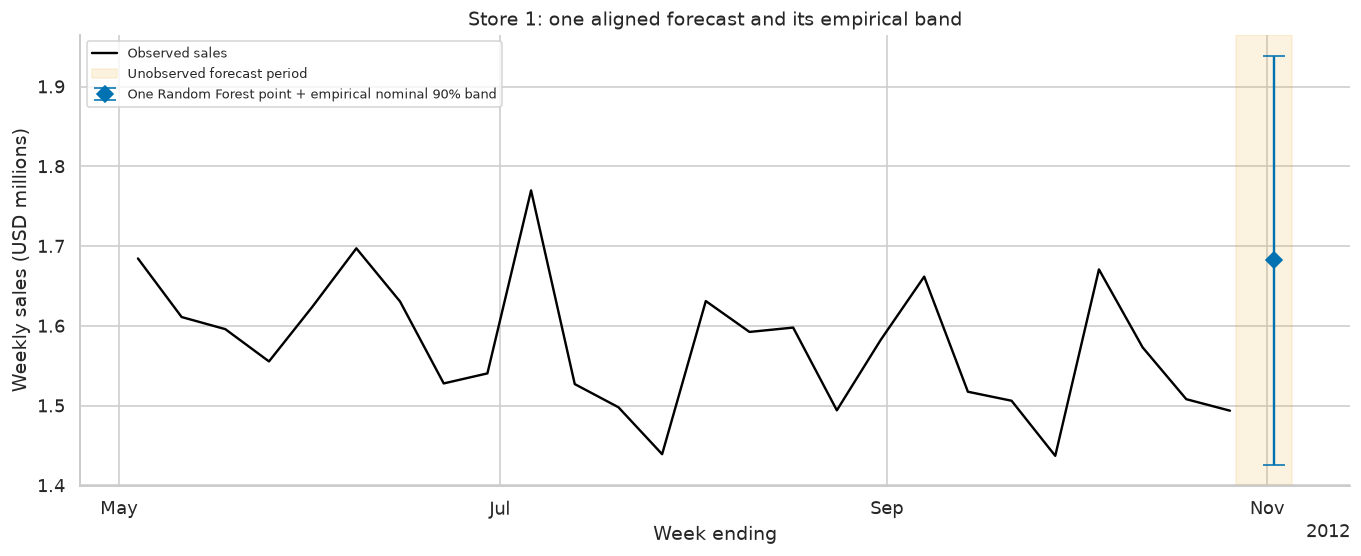

Point forecast **$1,682,235.05**, empirical band **[$1,425,469.72, $1,939,000.37]**. Reviewed store-1 holdout coverage was **100.00%**, compared with **98.89%** overall. The same fitted model supplies the point and center. Even high observed coverage over 14 outcomes does not establish dependable individual-store coverage.

In [25]:
DISPLAY_STORE=1
history_display=df.loc[df["Store"].eq(DISPLAY_STORE)].tail(26)
future_display=forecasts.loc[forecasts["Store"].eq(DISPLAY_STORE)].iloc[0]
center=future_display["Forecast (USD)"]
fig,ax=plt.subplots(figsize=(12,5))
ax.plot(history_display["Date"],history_display["Weekly_Sales"]/1e6,color="black",label="Observed sales")
ax.axvspan(df["Date"].max()+pd.Timedelta(days=1),FORECAST_DATE+pd.Timedelta(days=3),color="#E69F00",alpha=.12,label="Unobserved forecast period")
ax.errorbar([FORECAST_DATE],[center/1e6],
    yerr=np.array([[center-future_display["Nominal 90% lower (USD)"]],[future_display["Nominal 90% upper (USD)"]-center]])/1e6,
    color=MODEL_COLORS[PRODUCTION_MODEL_NAME],fmt="D",markersize=7,capsize=7,
    label=f"One {PRODUCTION_MODEL_NAME} point + empirical nominal 90% band")
ax.set(title=f"Store {DISPLAY_STORE}: one aligned forecast and its empirical band",xlabel="Week ending",ylabel="Weekly sales (USD millions)")
ax.legend(fontsize=8,loc="upper left");show_plot()
note(f"Point forecast **${center:,.2f}**, empirical band **[${future_display['Nominal 90% lower (USD)']:,.2f}, "
     f"${future_display['Nominal 90% upper (USD)']:,.2f}]**. Reviewed store-{DISPLAY_STORE} holdout coverage was "
     f"**{100*interval_by_store.loc[DISPLAY_STORE,'Coverage']:.2f}%**, compared with **{100*interval_coverage:.2f}%** overall. "
     "The same fitted model supplies the point and center. Even high observed coverage over 14 outcomes does not establish dependable individual-store coverage.")

## 10. Verification and Reproducibility
The following checks recompute reported metrics independently, verify test alignment and feature availability, ensure all three ML algorithms were fitted, and confirm source data integrity. Successful execution from a fresh kernel is required; saved output alone is not a substitute for rerunning after code or dependency changes.

**Version 2 portability:** all historical regression references are inline in the verification cell. They are checks against an earlier measured run, not inputs to model fitting or reported performance. Execution requires only this notebook, `data/Walmart.csv`, and the installed environment; the notebook may be renamed and requires no older notebook, backup, or custom verification metadata.

In [26]:
assert set(fitted_models) == {"Random Forest", "Gradient Boosting", "XGBoost"}
assert len(cv_records) == 33  # 27 ML fits plus 6 baseline evaluations
assert cv_results.groupby(["Model", "Candidate"]).size().eq(3).all()
assert len(test_predictions) == 5 and len(evaluation) == 630
assert len(forecasts) == 45 and forecasts["Store"].nunique() == 45
assert set(test["Store"]) == set(development["Store"]) == set(forecasts["Store"])
assert development["Date"].max() < test["Date"].min()
for name, pred in test_predictions.items():
    actual = y_test.to_numpy(dtype=float)
    error = np.asarray(pred) - actual
    independent = {"MAE": np.abs(error).mean(), "RMSE": np.sqrt(np.mean(error**2)),
                   "WAPE (%)": 100 * np.abs(error).sum() / np.abs(actual).sum(),
                   "R2": 1 - np.square(error).sum() / np.square(actual - actual.mean()).sum()}
    row = comparison.set_index("Model").loc[name]
    for key, value in independent.items():
        assert np.isclose(row[key], value, rtol=1e-10, atol=1e-8), (name, key)
assert SELECTED_MODEL == best_rows.iloc[0]["Model"]
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == SOURCE_SHA256
assert evaluation["Prediction"].ge(0).all()
verification_summary = {
    "status": "PASS", "source_sha256": SOURCE_SHA256, "data_rows": len(df),
    "development_rows": len(development), "test_rows": len(test), "cv_ml_fits": 27,
    "selected_model": SELECTED_MODEL, "best_ml_model": BEST_ML_MODEL,
    "selected_test_metrics": {k: float(v) for k,v in selected_scores.items()},
    "forecast_date": str(FORECAST_DATE.date()), "forecast_rows": len(forecasts),
    "elapsed_seconds": round(time.perf_counter() - START_TIME, 2),
}


assert test["Date"].min() == pd.Timestamp("2012-07-27")
assert test["Date"].max() == pd.Timestamp("2012-10-26")
assert len(ablation_folds) == 18
assert backtest_predictions["Date"].max() < TEST_START
assert not set(REMOVED_FEATURES).intersection(REDUCED_FEATURES)



assert len(store_diagnostics) == 45
assert calibration["Date"].max() < test["Date"].min()
assert interval_choices["Training end"].max() < calibration["Date"].min()
assert len(interval_evaluation) == len(test)
assert np.isfinite(interval_evaluation[["Center","Lower","Upper"]].to_numpy()).all()
assert interval_evaluation["Lower"].le(interval_evaluation["Center"]).all()
assert interval_evaluation["Center"].le(interval_evaluation["Upper"]).all()
assert np.isclose(interval_coverage, np.mean((y_test.to_numpy() >= interval_lower) & (y_test.to_numpy() <= interval_upper)))
assert alert_history["Date"].max() < TEST_START
assert len(backtest_predictions) == 5 * 45 * 51
for (period,name),g in backtest_predictions.groupby(["Period","Model"]):
    recorded = backtest_scores.loc[backtest_scores["Period"].eq(period) & backtest_scores["Model"].eq(name)].iloc[0]
    for key,value in metrics(g["Weekly_Sales"],g["Prediction"]).items():
        assert np.isclose(recorded[key],value)
# The source and final holdout are unchanged; previous numeric outputs are regression references only.
# Self-contained historical regression references from the initial verified run.
# These are expected test values only; training, predictions, and report metrics
# are computed above. No notebook filename, backup, or custom metadata is read.
original_reference = {'selected_model': 'Random Forest',
 'selected_test_metrics': {'MAE': 36036.478899672606,
                           'R2': 0.9884242348788389,
                           'RMSE': 56558.72848018178,
                           'WAPE (%)': 3.5146374889257523},
 'source_sha256': '0846b6941217dd938ceba6ae04650ccbbd01f4877a5f88bfa4dbecda54806c8f'}
original_comparison_reference = {'Gradient Boosting': {'CV_MAE': 56038.3907,
                       'MAE': 36167.7386,
                       'R2': 0.9895,
                       'RMSE': 53824.5267,
                       'WAPE (%)': 3.5274},
 'Last-week baseline': {'CV_MAE': 86249.1302,
                        'MAE': 48895.6173,
                        'R2': 0.9805,
                        'RMSE': 73367.2597,
                        'WAPE (%)': 4.7688},
 'Random Forest': {'CV_MAE': 52631.9084,
                   'MAE': 36036.4789,
                   'R2': 0.9884,
                   'RMSE': 56558.7285,
                   'WAPE (%)': 3.5146},
 'Seasonal baseline': {'CV_MAE': 60992.0743,
                       'MAE': 52325.3587,
                       'R2': 0.9745,
                       'RMSE': 83959.123,
                       'WAPE (%)': 5.1033},
 'XGBoost': {'CV_MAE': 57506.6532,
             'MAE': 40119.7451,
             'R2': 0.9871,
             'RMSE': 59765.799,
             'WAPE (%)': 3.9129}}
assert SELECTED_MODEL == original_reference["selected_model"]
assert SOURCE_SHA256 == original_reference["source_sha256"]
for key,value in original_reference["selected_test_metrics"].items():
    assert np.isclose(selected_scores[key],value,rtol=1e-10,atol=1e-7)

for name, recorded in original_comparison_reference.items():
    current = comparison.set_index("Model").loc[name]
    for key,value in recorded.items():
        assert np.isclose(current[key],value,rtol=0,atol=0.00011), (name,key)
# Repeat the perturbation check at every added forecast/calibration boundary.
for origin in sorted({pd.Timestamp(p[1]) for p in BACKTEST_PERIODS} | {CALIBRATION_START, TEST_START}):
    perturbed = df.copy()
    perturbed.loc[perturbed["Date"] >= origin,"Weekly_Sales"] += 10_000_000
    features_after = make_features(perturbed)
    before_or_at = engineered["Date"] <= origin
    pd.testing.assert_frame_equal(engineered.loc[before_or_at,FEATURES],features_after.loc[before_or_at,FEATURES])
assert not test["Date"].isin(calibration["Date"]).any()

np.testing.assert_allclose(forecasts["Forecast (USD)"].to_numpy(),deployment_model.predict(future_features[FEATURES]),rtol=1e-12,atol=1e-7)
np.testing.assert_allclose(interval_evaluation["Center"].to_numpy(),production_test_model.predict(X_test),rtol=1e-12,atol=1e-7)
assert (store_interval_q>=INTERVAL_Q).all()
assert alert_origin_audit["Threshold history ends"].lt(alert_origin_audit["Origin"]).all()
assert alert_predictions["Date"].max()<TEST_START and len(alert_predictions)==3*45*51
assert alert_predictions.groupby("Rule").size().eq(45*51).all()
assert not alert_predictions.duplicated(["Rule","Store","Date"]).any()
assert alert_utility_summary.set_index("Rule").loc["Always NORMAL","Warning recall (%)"]==0
for _,row in alert_utility_summary.iterrows():
    assert row["Hits"]+row["False alarms"]==row["Alerts"]
    assert row["Hits"]+row["Missed movements"]==row["Material movements"]
assert len(ablation_period_effects)==9
assert np.isclose(legacy_interval_coverage,legacy_covered.mean())
assert set(interval_by_store.index)==set(forecasts["Store"])
refined_verification = {
    "status":"PASS", "verification_references_self_contained":True, "original_selection_preserved":True, "all_original_metrics_preserved":True,
    "backtest_periods":len(BACKTEST_PERIODS), "backtest_weeks":int(backtest_predictions["Date"].nunique()),
    "backtest_predictions":len(backtest_predictions), "nested_tuning_fits":72,
    "ablation_fold_results":len(ablation_folds),
    "ablation_mae_increase_pct":ablation_delta["MAE increase without previous-year (%)"].to_dict(),
    "paired_RF_minus_GB_USD":float(paired_difference.mean()),
    "RF_week_wins":rf_week_wins,"GB_week_wins":gb_week_wins,
    "paired_3week_bootstrap_interval_USD":[float(main_interval["95% lower (USD)"]),float(main_interval["95% upper (USD)"])],
    "backtest_pooled_metrics":backtest_overall.to_dict(orient="records"),
    "interval_model":INTERVAL_MODEL_NAME, "unified_parameters":PRODUCTION_PARAMETERS, "unified_test_metrics":production_test_scores,"holdout_interval_coverage":interval_coverage,
    "mean_interval_width_USD":interval_width,"alert_thresholds_pct":[float(ALERT_LOW),float(ALERT_HIGH)],
    "source_sha256":SOURCE_SHA256,"selected_model":SELECTED_MODEL,
    "selected_test_metrics":{k:float(v) for k,v in selected_scores.items()},
    "legacy_overall_coverage":legacy_interval_coverage,"legacy_mean_interval_width_USD":legacy_interval_width,
    "legacy_store14_coverage":float(legacy_store_coverage.loc[14]),"legacy_store36_coverage":float(legacy_store_coverage.loc[36]),
    "store14_coverage":float(interval_by_store.loc[14,"Coverage"]),"store36_coverage":float(interval_by_store.loc[36,"Coverage"]),
    "undercovered_stores":[int(s) for s in undercovered_stores],
    "ablation_period_summary":ablation_period_summary.to_dict(orient="records"),
    "alert_utility":alert_utility_summary.replace({np.nan:None}).to_dict(orient="records"),
    "forecast_alert_counts":forecasts["Alert"].value_counts().to_dict(),"point_band_model_aligned":True,
    "forecast_rows":len(forecasts),"elapsed_seconds":round(time.perf_counter()-START_TIME,2),
}
print("REFINED_VERIFICATION="+json.dumps(refined_verification,sort_keys=True))


print("SECTION_10_VERIFICATION=PASS — all checks completed; references are self-contained.")
note("**Section 10 passed:** model fits, independent metrics, chronological boundaries, past-only features, "
     "historical references, point/band alignment, alert counts, and dataset checksum are verified. "
     "No other notebook or metadata lookup is required.")


REFINED_VERIFICATION={"GB_week_wins": 7, "RF_week_wins": 7, "ablation_fold_results": 18, "ablation_mae_increase_pct": {"Gradient Boosting": 130.66153082644996, "Random Forest": 120.46625458394975, "XGBoost": 82.25363190644197}, "ablation_period_summary": [{"First-fold MAE change (%)": 305.5395908512212, "First-fold share of net MAE increase (%)": 100.61987759374932, "Later-fold mean MAE change (%)": -1.4216802764588699, "Model": "Gradient Boosting"}, {"First-fold MAE change (%)": 267.63755067513216, "First-fold share of net MAE increase (%)": 98.56871441071094, "Later-fold mean MAE change (%)": 3.0992538197399444, "Model": "Random Forest"}, {"First-fold MAE change (%)": 193.58582229356594, "First-fold share of net MAE increase (%)": 98.78398682997552, "Later-fold mean MAE change (%)": 1.723700671816153, "Model": "XGBoost"}], "alert_thresholds_pct": [-18.808576142417298, 24.173557045394045], "alert_utility": [{"Alerts": 0, "Direction-correct alerts": 0, "Directional precision (%)": null

**Section 10 passed:** model fits, independent metrics, chronological boundaries, past-only features, historical references, point/band alignment, alert counts, and dataset checksum are verified. No other notebook or metadata lookup is required.

## 11. Final Academic Report
The next cell generates the final report from the live variables. Its saved output is the completed academic report; rerunning updates all numerical claims without manual transcription.

In [27]:
def report_table(frame, columns):
    header = "| " + " | ".join(columns) + " |"
    divider = "| " + " | ".join(["---"] * len(columns)) + " |"
    rows = []
    for _, row in frame.iterrows():
        values = ["N/A" if pd.isna(row[c]) else (f"{row[c]:,.4f}" if isinstance(row[c], (float, np.floating)) else str(row[c])) for c in columns]
        rows.append("| " + " | ".join(values) + " |")
    return "\n".join([header, divider] + rows)

report_comparison = report_table(comparison,["Model","CV_MAE","MAE","RMSE","WAPE (%)","R2"])
report_backtest = report_table(backtest_scores,["Period","Model","Weeks","MAE","RMSE","WAPE (%)"])
report_ablation = report_table(ablation_summary,["Model","Experiment","MAE","RMSE","WAPE (%)"])
report_ablation_periods = report_table(ablation_period_summary,list(ablation_period_summary.columns))
report_alert_utility = report_table(alert_utility_summary,["Rule","Alerts","Material movements","Warning precision (%)","Warning recall (%)","False alarms","Missed movements","Directional recall (%)"])
report_bootstrap = report_table(bootstrap_comparison,list(bootstrap_comparison.columns))
report_stores = report_table(store_diagnostics.head(5),["Store","MAE","RMSE","WAPE (%)","Mean signed error (USD)","Relative bias (%)"])
selected_cv_mae = float(best_rows.set_index("Model").loc[SELECTED_MODEL,"CV_MAE"])
relative_mae_change = 100*(comparison.set_index("Model").loc["Last-week baseline","MAE"]-selected_scores["MAE"])/comparison.set_index("Model").loc["Last-week baseline","MAE"]
executive_summary = f"""
### Executive Summary
- **Objective:** forecast next week's store revenue using only information available after the previous week closes.
- **Data:** {len(df):,} rows, {df['Store'].nunique()} stores, {len(all_dates)} weeks ending {all_dates.max():%d %B %Y}; no current-date data.
- **Algorithms:** Random Forest, Gradient Boosting, XGBoost, and two historical persistence baselines.
- **Preserved selection:** {SELECTED_MODEL}; final holdout MAE ${selected_scores['MAE']:,.2f}, WAPE {selected_scores['WAPE (%)']:.2f}%.
- **Backtest finding:** {backtest_overall.iloc[0]['Model']} has the lowest pooled MAE (**${backtest_overall.iloc[0]['MAE']:,.2f}**) across the additional development backtests; the 2011 shopping-window leader is **{peak_scores.iloc[0]['Model']}**. The original RF selection is retained, but universal ML superiority is unsupported.
- **Ablation depends on period:** the large mean effect is dominated by the first validation block. Later-block changes are {'; '.join(f"{r['Model']}: {r['Later-fold mean MAE change (%)']:+.2f}%" for _,r in ablation_period_summary.iterrows())}; a uniformly beneficial annual-lag effect is unsupported.

- **Stronger evidence:** {backtest_predictions['Date'].nunique()} development backtest weeks include one 2011 holiday cycle. Controlled feature ablation and weekly paired comparisons test dependence on prior-year history and period choice.
- **Close contenders:** RF−GB mean absolute-error difference is ${paired_difference.mean():,.2f}; RF wins {rf_week_wins}/{TEST_WEEKS} weeks. The 3-week bootstrap interval is [${main_interval['95% lower (USD)']:,.2f}, ${main_interval['95% upper (USD)']:,.2f}], under exploratory dependence assumptions.
- **Unified forecasts:** one latest-data {PRODUCTION_MODEL_NAME} model supplies each point and its empirical band center, using settings fixed before calibration. Its separately measured holdout MAE is ${production_test_scores['MAE']:,.2f}; original benchmark metrics remain unchanged.
- **Store reliability:** the replaced band's overall coverage {100*legacy_interval_coverage:.2f}% hid store-14 coverage {100*legacy_store_coverage.loc[14]:.2f}% and store-36 coverage {100*legacy_store_coverage.loc[36]:.2f}%. Updated bands cover {100*interval_coverage:.2f}% overall, but the number of stores below nominal is {len(undercovered_stores)}; no dependable per-store guarantee is claimed.
- **Warning utility:** origin-quantile alerts have {quantile_utility['Warning precision (%)']:.2f}% historical precision and {quantile_utility['Warning recall (%)']:.2f}% recall for ±15% material moves, with {int(quantile_utility['Missed movements'])} missed moves. Zero future alerts is allowed, not proof of safety.

- **Limits:** fewer than three annual cycles, only one development holiday cycle with sufficient history, dependent store/weeks, unverified dataset license/provenance, no realized next-week actuals.
"""
display(Markdown(executive_summary))
report = f"""
### 11.1 Abstract
This local, reproducible study forecasts one-week-ahead retail revenue for {df['Store'].nunique()} stores. Random Forest, Gradient Boosting, and XGBoost are compared against last-week and seasonal persistence. The original validation-selected **{SELECTED_MODEL}** is preserved with final holdout MAE **${selected_scores['MAE']:,.2f}**, RMSE **${selected_scores['RMSE']:,.2f}**, WAPE **{selected_scores['WAPE (%)']:.2f}%**, and R² **{selected_scores['R2']:.4f}**. Additional nested rolling-origin development backtests, controlled feature ablation, weekly paired comparisons, store bias analysis, and aligned latest-data point/band forecasts extend the evidence without changing the original benchmark selection. Interval reliability is assessed per store, feature ablation by period, and alerts by past-only warning outcomes.

### 11.2 Introduction and Business Problem
Managers must plan staffing, inventory, and cash before next week's revenue is observed. Forecasting is continuous regression subject to an information boundary: only past finalized sales and known calendar inputs can predict the next store-week. The forecast origin is immediately after the previous week closes. Sales revenue does not directly determine product quantities or profit.

### 11.3 Objectives
Validate the supplied panel; explain store and seasonal patterns; construct past-only predictors; compare tuned ML models with baselines; test holiday-period robustness and prior-year feature dependence; investigate close-model stability and store bias; quantify empirical forecast uncertainty; and provide transparent planning alerts and reproducible evidence.

### 11.4 Dataset Description and Provenance
Walmart.csv contains **{len(df):,} records**, **{len(REQUIRED)} columns**, **{df['Store'].nunique()} stores**, and **{len(all_dates)} consecutive weekly dates per store**, from **{all_dates.min():%d %B %Y}** through **{all_dates.max():%d %B %Y}**. Fields are Store, Date, Weekly_Sales, Holiday_Flag, Temperature, Fuel_Price, CPI, and Unemployment. Dates are explicitly day-month-year; sales are treated as USD by convention, with original currency metadata unverified. The candidate [Kaggle Walmart Dataset by M Yasser H](https://www.kaggle.com/datasets/yasserh/walmart-dataset) was checked on 22 October 2026, but its card/API metadata and license could not be read. Neither exact local-to-source equivalence nor redistribution permission is asserted. Local source SHA-256: `{SOURCE_SHA256}`. The supplied CSV is preserved byte-for-byte and is historical, not current market data.

### 11.5 Exploratory Analysis and Preprocessing
Development-only charts show total sales history, store differences, target distribution, holiday comparisons, monthly/seasons, correlations, and serial dependence. The maximum development total is **${weekly.max()/1e6:,.2f} million** ({weekly.idxmax():%d %B %Y}); holiday-week average sales differ by **{holiday_lift:+.1f}%** from non-holiday averages. These are descriptive associations, not causal effects. No missing cells or duplicate store-date rows were found. Numeric/date checks and full weekly-panel assertions passed. Legitimate extreme/holiday values were retained; no imputation or silent deletion was used.

### 11.6 Feature Engineering
Store identity is one-hot encoded within each fit. Calendar features include month, ISO week, year, cyclic terms, elapsed weeks, and a maintained 2010–2012 holiday schedule. Sales lags 1, 2, 3, 4, 13, 26, 51, 52, and 53 plus past-only rolling means/standard deviation and prior-year average are generated within each store after shifting. Future-target perturbation and manual alignment checks pass. Same-week weather/economics are excluded because their forecast-origin availability is not established. A 53-week warm-up leaves **{len(model_data):,} supervised rows**.

### 11.7 Model Training and Original Selection
The original **{len(development):,} development rows** and **{len(test):,} final holdout rows** remain unchanged. Three expanding folds with ten dates each compare three configurations per family (**27 original CV fits**) and two baselines. MAE is the prespecified criterion. Store preprocessing is fitted only on training rows; trees need no scaling. Random seeds and bounded CPU threads are retained. Mean validation MAE selects **{SELECTED_MODEL}** (**${selected_cv_mae:,.2f}**) before holdout inspection. Chosen parameters: `{json.dumps(selected_parameters,sort_keys=True)}`.

### 11.8 Additional Backtesting Methodology and Results
Four non-overlapping development blocks span **{backtest_predictions['Date'].min():%d %B %Y}–{backtest_predictions['Date'].max():%d %B %Y}**, totaling **{backtest_predictions['Date'].nunique()} unique weeks**. Each origin uses expanding earlier history and separate two-fold, four-week inner tuning of all three families (**72 additional tuning fits**, plus 12 outer ML fits). No later outer or holdout labels tune an earlier model. Parameters remain fixed in each block; previous observed actuals update features at later one-week origins. All five methods predict identical rows. This differs from a multiweek forecast issued all at once.

{report_backtest}

The 2011 shopping-window leader is **{peak_scores.iloc[0]['Model']}**, with MAE **${peak_scores.iloc[0]['MAE']:,.2f}**. The pooled development-backtest leader is **{backtest_overall.iloc[0]['Model']}**. Block lengths/training sizes differ, and only one Thanksgiving/Christmas cycle is available after the warm-up. The 2010 holidays lack enough supervised prior-year history. Seasonal attribution and repeatability remain uncertain; these extra diagnostics do not replace the original selection.

### 11.9 Final Holdout Model Evaluation
The final dates remain **{test['Date'].min():%d %B %Y}–{test['Date'].max():%d %B %Y}**. MAE/RMSE use USD per store-week; WAPE is `100 × sum(abs(error))/sum(abs(actual))`; R² is secondary and sensitive to store-size differences. WAPE is not an accuracy score.

{report_comparison}

Random Forest remains the original selected model; the observed test leader is **{test_winner}**. The selected model improves MAE by **{relative_mae_change:.2f}%** relative to last-week persistence. Gradient Boosting may rank differently on RMSE; the selection criterion is unchanged. Training-versus-validation errors in Section 8.3 expose fit/generalization gaps but also reflect seasonal and sample-size changes.

### 11.10 Feature-Ablation Findings
A retains the original features. B removes lags 51–53 and prior_year_mean_3. Both use identical original folds, rows, warm-up, seeds, tree counts, and full-feature chosen hyperparameters. No reduced-feature retuning or final-test feature selection is performed.

{report_ablation}

Mean fold MAE changes without the prior-year group are **{'; '.join(f"{name}: {r['MAE increase without previous-year (%)']:+.1f}%" for name,r in ablation_delta.iterrows())}**. These are **period-dependent averages**, not equal benefits in every period.

{report_ablation_periods}

The first validation block supplies most of the net deterioration. Later-block changes can be small or reversed; a contribution above 100% means later gains offset the first loss. The first block straddles year end/new year, and fixed full-feature tuning can interact with that calendar shift. These are descriptive sensitivities, not causal proof or a newly selected feature set. Permutation importance is conditional on its own last-validation block and the unified forecast configuration; correlated lags can substitute.

### 11.11 Model Stability and Paired Statistical Comparison
RF weekly MAE minus GB weekly MAE averages **${paired_difference.mean():,.2f}** across {TEST_WEEKS} holdout dates. Negative favors RF. RF wins **{rf_week_wins} weeks**, GB wins **{gb_week_wins}**, with **{TEST_WEEKS-rf_week_wins-gb_week_wins} ties**. RF wins **{rf_storeweek_wins}/{len(test)} store-weeks**, which are not independent observations. Original-fold and nested-period tables show sensitivity to evaluation dates.

{report_bootstrap}

Intervals use 5,000 seeded circular resamples of whole-week blocks. The 2/3/4-week sensitivity reflects arbitrary block choice. The weekly unit preserves shared store shocks, but weak stationarity and dependence assumptions are unverified and 14 observations are few. The 3-week interval **{'includes' if main_interval['95% lower (USD)'] <= 0 <= main_interval['95% upper (USD)'] else 'excludes'} zero** under these assumptions. No formal significance or universal-superiority claim is made. There is no test-based model change.

### 11.12 Store-Level Performance and Bias
The selected model's mean signed error is **${evaluation['Error'].mean():,.2f}** per store-week. Store WAPE ranges **{store_diagnostics['WAPE (%)'].min():.2f}%–{store_diagnostics['WAPE (%)'].max():.2f}%**. Positive prediction-minus-actual bias is overprediction. Relative bias divides total signed error by actual revenue. At least 75% same-direction weekly errors define a descriptive consistency flag; counts are **{json.dumps(bias_counts,sort_keys=True)}**. Worst five by WAPE:

{report_stores}

The diagnostic history plot focuses on store **{high_error_store}**, selected after seeing errors. Promotions, local demand, inventory constraints, and changing seasonal patterns are plausible missing influences, not established causes. Revenue scale affects absolute errors; WAPE and bias add complementary evidence.

### 11.13 Aligned Forecast Uncertainty and Individual-Store Reliability
The previous frozen-model band's pooled holdout coverage was **{100*legacy_interval_coverage:.2f}%**, but store 14 had **{100*legacy_store_coverage.loc[14]:.2f}%** and store 36 **{100*legacy_store_coverage.loc[36]:.2f}%**. Thus the aggregate headline did **not** establish dependable store-level intervals; the severe failures are retained as a legacy diagnostic.

The unified workflow selects **{PRODUCTION_MODEL_NAME}**, parameters `{json.dumps(PRODUCTION_PARAMETERS,sort_keys=True)}`, using inner-validation scores strictly before **{CALIBRATION_START:%d %B %Y}**. The next **{CALIBRATION_WEEKS} development weeks / {len(calibration)} rows** supply out-of-sample residuals from the pre-calibration fit, scaled by past 13-week means. Each store threshold is the maximum of its own finite-order-statistic quantile and the pooled quantile **{INTERVAL_Q:.4f}**. With 16 store residuals, the store quantile is its maximum observed calibration error and can be unstable. No holdout labels set the thresholds or configuration.

The learner is refitted on all development rows for the holdout and all observed rows for the future point. At either origin, **one fitted model** supplies both the displayed point and band center. This unified configuration is evaluated separately from the original benchmark: MAE **${production_test_scores['MAE']:,.2f}**, RMSE **${production_test_scores['RMSE']:,.2f}**, WAPE **{production_test_scores['WAPE (%)']:.2f}%**. Original benchmark results remain unchanged and must not be attributed to this revised configuration.

Updated overall empirical coverage is **{100*interval_coverage:.2f}%**, mean width **${interval_width:,.2f}** (legacy width **${legacy_interval_width:,.2f}**), and store coverage ranges **{100*interval_by_store['Coverage'].min():.2f}%–{100*interval_by_store['Coverage'].max():.2f}%**. Store 14 now has **{100*interval_by_store.loc[14,'Coverage']:.2f}%**; store 36 **{100*interval_by_store.loc[36,'Coverage']:.2f}%**. **Number of stores below nominal 90%: {len(undercovered_stores)}**; IDs: **{undercovered_stores}**. The complete store table and plot show these failures, and forecast rows carry cautions. These bands are **not dependable for every individual store**; even 100% observed coverage comprises only 14 outcomes.

Refitting after residual estimation changes the fitted function. Applying earlier errors to the refit is an empirical residual-transfer approximation, not a split-conformal guarantee. Dependence, short calibration history, drift, and adaptation prompted by an already-reviewed holdout further limit interpretation. Revised coverage is retrospective, not a new independent test; no band widths are subsequently tuned to observed test failures. The higher observed coverage uses wider bands and reduces planning precision; coverage alone is not a sufficient quality score. Future conditional and simultaneous coverage remain unknown.

### 11.14 Explainable AI, Warning Utility, and Business Interpretation
Validation permutation importance for the unified **{explain_name}** configuration ranks **{importance_table.iloc[0]['Feature']}** highest within the last validation block. Correlation and substitution limit interpretation. The original-configuration ablation is dominated by the first validation period; neither study proves equally strong prior-year benefit in every season.

Future planning thresholds use development-only deviation quantiles **{ALERT_LOW:.2f}% / +{ALERT_HIGH:.2f}%**. To test usefulness rather than trigger frequency alone, each of the four development backtest origins re-estimates these thresholds using only earlier actual deviations. A material warning situation is independently defined as an actual ±15% movement from the preceding 13-week mean. Random Forest outer predictions are scored against those situations without future labels entering the thresholds.

{report_alert_utility}

The origin-quantile rule has **{quantile_utility['Warning precision (%)']:.2f}% precision**, **{quantile_utility['Warning recall (%)']:.2f}% recall**, and **{quantile_utility['Directional recall (%)']:.2f}% directional recall**, with **{int(quantile_utility['False alarms'])} false alarms** and **{int(quantile_utility['Missed movements'])} missed movements** across 2,295 development store-weeks. The fixed ±15% and always-NORMAL baselines expose the review-volume/recall tradeoff. No rule is chosen from these scores or the holdout. Results show historical warning behavior for a declared proxy, not business profit or anomaly probabilities. Missed events mean NORMAL does not imply low risk. The warning experiment uses nested RF predictions with period-specific past-only settings; the unified future configuration is related but not identical, so exact utility transfer is unverified.

### 11.15 Next-Week Forecasts
A single latest-data fitted **{PRODUCTION_MODEL_NAME}**, with settings chosen before calibration, forecasts **{len(forecasts)} stores** for **{FORECAST_DATE:%d %B %Y}**, totaling **${forecasts['Forecast (USD)'].sum():,.2f}**. Its point and interval center are identical; the chart uses one forecast marker with its empirical band. Forecast rows flag stores below nominal reviewed coverage and caution all other stores about the small sample. Alert counts are **{json.dumps(forecasts['Alert'].value_counts().to_dict(),sort_keys=True)}**. No future actuals are supplied; realized accuracy, alert utility, and per-store coverage are unknown. The original benchmark point results stay in the comparison table, not as an unlabeled second future marker.

### 11.16 Limitations
There are fewer than three annual cycles and only one fully testable development holiday cycle. The preserved holdout has **{number_holiday_weeks} flagged holiday week(s)** and no Thanksgiving/Christmas. Additional development diagnostics reuse historical data already involved in the original project; they are not a second untouched final test. The ablation is conditional on full-feature tuning. Periods differ in length/training size and store errors share weekly shocks. Bootstrap intervals rely on approximations with only 14 test dates. Empirical residual-transfer bands lack exchangeability/refit guarantees; aggregate coverage masks unreliable individual stores. Revisions respond to already-reviewed holdout findings, so a new independent test is still needed. Calendar coverage ends in 2012 and prior-week reporting is assumed immediate. No unseen-store, multiweek-recursive, promotion, stockout, or causal validation is provided. Currency metadata, dataset equivalence to the candidate Kaggle download, and license remain unverified. Library/platform differences may slightly alter results.

### 11.17 Future Improvements
Collect more complete annual cycles and promotion/inventory data; maintain release-aware covariates and calendar updates; test realistic reporting delays; perform rolling-origin nested comparisons on new data; evaluate recursive multiweek forecasts separately; calibrate store/season-specific uncertainty with enough history; monitor drift and observed coverage; and assess planning-alert costs with business feedback before operational adoption.

### 11.18 Conclusion
The project now verifies the original lifecycle plus nested backtesting, controlled prior-year ablation, time-aware paired uncertainty, store bias diagnostics, chronological residual bands, origin-specific alert-utility backtesting, period-specific ablation interpretations, and transparent provenance. The original **{SELECTED_MODEL}** selection and holdout point results are preserved. Evidence is conditional on the stated one-week-ahead protocol; a small RF/GB holdout gap is not proof of universal superiority, and next-week actuals are still required.

### 11.19 References
1. Supplied `data/Walmart.csv`, source checksum above; original preserved.
2. [Candidate Kaggle source: M Yasser H, Walmart Dataset](https://www.kaggle.com/datasets/yasserh/walmart-dataset) — candidate only; license/file equivalence unverified, checked 22 October 2026.
3. [scikit-learn: lagged-feature time-series example](https://scikit-learn.org/stable/auto_examples/applications/plot_time_series_lagged_features.html).
4. [scikit-learn: TimeSeriesSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html).
5. [scikit-learn: ensembles](https://scikit-learn.org/stable/modules/ensemble.html) and [permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html).
6. [XGBoost Python API](https://xgboost.readthedocs.io/en/stable/python/python_api.html); Chen and Guestrin (2016), [XGBoost](https://doi.org/10.1145/2939672.2939785).
7. [arch documentation: time-series bootstraps](https://arch.readthedocs.io/en/stable/bootstrap/timeseries-bootstraps.html) — circular resampling rationale; implemented with NumPy without adding arch as a dependency.
8. Xu and Xie (2023), [Sequential Predictive Conformal Inference for Time Series](https://proceedings.mlr.press/v202/xu23r.html) — dependence-aware uncertainty context; the simpler empirical bands here do not implement SPCI or inherit its theoretical claims.
"""
assert all(s in report for s in ["Abstract","Introduction","Business Problem","Objectives","Dataset Description","Exploratory Analysis",
    "Preprocessing","Feature Engineering","Model Training","Backtesting","Model Evaluation","Feature-Ablation","Model Stability",
    "Store-Level Performance","Forecast Uncertainty","Explainable AI","Business Interpretation","Limitations","Future Improvements","Conclusion","References"])
display(Markdown(report))
print("COMPLETE: refined academic report rendered from verified computed results.")



### Executive Summary
- **Objective:** forecast next week's store revenue using only information available after the previous week closes.
- **Data:** 6,435 rows, 45 stores, 143 weeks ending 26 October 2012; no current-date data.
- **Algorithms:** Random Forest, Gradient Boosting, XGBoost, and two historical persistence baselines.
- **Preserved selection:** Random Forest; final holdout MAE $36,036.48, WAPE 3.51%.
- **Backtest finding:** Seasonal baseline has the lowest pooled MAE (**$61,207.48**) across the additional development backtests; the 2011 shopping-window leader is **Seasonal baseline**. The original RF selection is retained, but universal ML superiority is unsupported.
- **Ablation depends on period:** the large mean effect is dominated by the first validation block. Later-block changes are Gradient Boosting: -1.42%; Random Forest: +3.10%; XGBoost: +1.72%; a uniformly beneficial annual-lag effect is unsupported.

- **Stronger evidence:** 51 development backtest weeks include one 2011 holiday cycle. Controlled feature ablation and weekly paired comparisons test dependence on prior-year history and period choice.
- **Close contenders:** RF−GB mean absolute-error difference is $-131.26; RF wins 7/14 weeks. The 3-week bootstrap interval is [$-3,196.05, $2,616.22], under exploratory dependence assumptions.
- **Unified forecasts:** one latest-data Random Forest model supplies each point and its empirical band center, using settings fixed before calibration. Its separately measured holdout MAE is $35,910.00; original benchmark metrics remain unchanged.
- **Store reliability:** the replaced band's overall coverage 94.44% hid store-14 coverage 7.14% and store-36 coverage 50.00%. Updated bands cover 98.89% overall, but the number of stores below nominal is 1; no dependable per-store guarantee is claimed.
- **Warning utility:** origin-quantile alerts have 91.75% historical precision and 22.47% recall for ±15% material moves, with 307 missed moves. Zero future alerts is allowed, not proof of safety.

- **Limits:** fewer than three annual cycles, only one development holiday cycle with sufficient history, dependent store/weeks, unverified dataset license/provenance, no realized next-week actuals.



### 11.1 Abstract
This local, reproducible study forecasts one-week-ahead retail revenue for 45 stores. Random Forest, Gradient Boosting, and XGBoost are compared against last-week and seasonal persistence. The original validation-selected **Random Forest** is preserved with final holdout MAE **$36,036.48**, RMSE **$56,558.73**, WAPE **3.51%**, and R² **0.9884**. Additional nested rolling-origin development backtests, controlled feature ablation, weekly paired comparisons, store bias analysis, and aligned latest-data point/band forecasts extend the evidence without changing the original benchmark selection. Interval reliability is assessed per store, feature ablation by period, and alerts by past-only warning outcomes.

### 11.2 Introduction and Business Problem
Managers must plan staffing, inventory, and cash before next week's revenue is observed. Forecasting is continuous regression subject to an information boundary: only past finalized sales and known calendar inputs can predict the next store-week. The forecast origin is immediately after the previous week closes. Sales revenue does not directly determine product quantities or profit.

### 11.3 Objectives
Validate the supplied panel; explain store and seasonal patterns; construct past-only predictors; compare tuned ML models with baselines; test holiday-period robustness and prior-year feature dependence; investigate close-model stability and store bias; quantify empirical forecast uncertainty; and provide transparent planning alerts and reproducible evidence.

### 11.4 Dataset Description and Provenance
Walmart.csv contains **6,435 records**, **8 columns**, **45 stores**, and **143 consecutive weekly dates per store**, from **05 February 2010** through **26 October 2012**. Fields are Store, Date, Weekly_Sales, Holiday_Flag, Temperature, Fuel_Price, CPI, and Unemployment. Dates are explicitly day-month-year; sales are treated as USD by convention, with original currency metadata unverified. The candidate [Kaggle Walmart Dataset by M Yasser H](https://www.kaggle.com/datasets/yasserh/walmart-dataset) was checked on 22 October 2026, but its card/API metadata and license could not be read. Neither exact local-to-source equivalence nor redistribution permission is asserted. Local source SHA-256: `0846b6941217dd938ceba6ae04650ccbbd01f4877a5f88bfa4dbecda54806c8f`. The supplied CSV is preserved byte-for-byte and is historical, not current market data.

### 11.5 Exploratory Analysis and Preprocessing
Development-only charts show total sales history, store differences, target distribution, holiday comparisons, monthly/seasons, correlations, and serial dependence. The maximum development total is **$80.93 million** (24 December 2010); holiday-week average sales differ by **+8.1%** from non-holiday averages. These are descriptive associations, not causal effects. No missing cells or duplicate store-date rows were found. Numeric/date checks and full weekly-panel assertions passed. Legitimate extreme/holiday values were retained; no imputation or silent deletion was used.

### 11.6 Feature Engineering
Store identity is one-hot encoded within each fit. Calendar features include month, ISO week, year, cyclic terms, elapsed weeks, and a maintained 2010–2012 holiday schedule. Sales lags 1, 2, 3, 4, 13, 26, 51, 52, and 53 plus past-only rolling means/standard deviation and prior-year average are generated within each store after shifting. Future-target perturbation and manual alignment checks pass. Same-week weather/economics are excluded because their forecast-origin availability is not established. A 53-week warm-up leaves **4,050 supervised rows**.

### 11.7 Model Training and Original Selection
The original **3,420 development rows** and **630 final holdout rows** remain unchanged. Three expanding folds with ten dates each compare three configurations per family (**27 original CV fits**) and two baselines. MAE is the prespecified criterion. Store preprocessing is fitted only on training rows; trees need no scaling. Random seeds and bounded CPU threads are retained. Mean validation MAE selects **Random Forest** (**$52,631.91**) before holdout inspection. Chosen parameters: `{"Gradient Boosting": {"max_depth": 4, "min_samples_leaf": 5}, "Random Forest": {"max_depth": 16, "min_samples_leaf": 2}, "XGBoost": {"max_depth": 2, "min_child_weight": 5, "reg_lambda": 5}}`.

### 11.8 Additional Backtesting Methodology and Results
Four non-overlapping development blocks span **05 August 2011–20 July 2012**, totaling **51 unique weeks**. Each origin uses expanding earlier history and separate two-fold, four-week inner tuning of all three families (**72 additional tuning fits**, plus 12 outer ML fits). No later outer or holdout labels tune an earlier model. Parameters remain fixed in each block; previous observed actuals update features at later one-week origins. All five methods predict identical rows. This differs from a multiweek forecast issued all at once.

| Period | Model | Weeks | MAE | RMSE | WAPE (%) |
| --- | --- | --- | --- | --- | --- |
| 2011 late summer | Random Forest | 9 | 44,549.5583 | 70,404.1128 | 4.4066 |
| 2011 late summer | Gradient Boosting | 9 | 45,279.9417 | 70,921.8858 | 4.4788 |
| 2011 late summer | XGBoost | 9 | 47,144.7173 | 72,892.1419 | 4.6633 |
| 2011 late summer | Last-week baseline | 9 | 62,295.1074 | 105,626.1601 | 6.1619 |
| 2011 late summer | Seasonal baseline | 9 | 56,866.7534 | 86,635.8815 | 5.6249 |
| 2011 shopping peak | Random Forest | 13 | 130,826.1152 | 248,499.0343 | 11.2301 |
| 2011 shopping peak | Gradient Boosting | 13 | 129,398.1273 | 238,452.0131 | 11.1075 |
| 2011 shopping peak | XGBoost | 13 | 138,340.3122 | 256,544.9695 | 11.8751 |
| 2011 shopping peak | Last-week baseline | 13 | 197,355.3970 | 337,096.8443 | 16.9410 |
| 2011 shopping peak | Seasonal baseline | 13 | 70,054.3830 | 96,953.1704 | 6.0135 |
| 2012 winter/spring | Random Forest | 13 | 51,435.1210 | 75,375.1963 | 5.0787 |
| 2012 winter/spring | Gradient Boosting | 13 | 53,586.6716 | 75,283.0124 | 5.2911 |
| 2012 winter/spring | XGBoost | 13 | 60,487.6261 | 83,908.5694 | 5.9725 |
| 2012 winter/spring | Last-week baseline | 13 | 63,481.8839 | 93,791.1020 | 6.2682 |
| 2012 winter/spring | Seasonal baseline | 13 | 50,261.7749 | 68,324.5126 | 4.9628 |
| 2012 spring/summer | Random Forest | 16 | 48,136.6742 | 78,121.2154 | 4.5501 |
| 2012 spring/summer | Gradient Boosting | 16 | 50,540.1673 | 83,677.0761 | 4.7773 |
| 2012 spring/summer | XGBoost | 16 | 50,560.9219 | 85,015.5093 | 4.7792 |
| 2012 spring/summer | Last-week baseline | 16 | 67,143.9493 | 103,858.0307 | 6.3467 |
| 2012 spring/summer | Seasonal baseline | 16 | 65,354.4078 | 96,498.4248 | 6.1776 |

The 2011 shopping-window leader is **Seasonal baseline**, with MAE **$70,054.38**. The pooled development-backtest leader is **Seasonal baseline**. Block lengths/training sizes differ, and only one Thanksgiving/Christmas cycle is available after the warm-up. The 2010 holidays lack enough supervised prior-year history. Seasonal attribution and repeatability remain uncertain; these extra diagnostics do not replace the original selection.

### 11.9 Final Holdout Model Evaluation
The final dates remain **27 July 2012–26 October 2012**. MAE/RMSE use USD per store-week; WAPE is `100 × sum(abs(error))/sum(abs(actual))`; R² is secondary and sensitive to store-size differences. WAPE is not an accuracy score.

| Model | CV_MAE | MAE | RMSE | WAPE (%) | R2 |
| --- | --- | --- | --- | --- | --- |
| Random Forest | 52,631.9084 | 36,036.4789 | 56,558.7285 | 3.5146 | 0.9884 |
| Gradient Boosting | 56,038.3907 | 36,167.7386 | 53,824.5267 | 3.5274 | 0.9895 |
| XGBoost | 57,506.6532 | 40,119.7451 | 59,765.7990 | 3.9129 | 0.9871 |
| Last-week baseline | 86,249.1302 | 48,895.6173 | 73,367.2597 | 4.7688 | 0.9805 |
| Seasonal baseline | 60,992.0743 | 52,325.3587 | 83,959.1230 | 5.1033 | 0.9745 |

Random Forest remains the original selected model; the observed test leader is **Random Forest**. The selected model improves MAE by **26.30%** relative to last-week persistence. Gradient Boosting may rank differently on RMSE; the selection criterion is unchanged. Training-versus-validation errors in Section 8.3 expose fit/generalization gaps but also reflect seasonal and sample-size changes.

### 11.10 Feature-Ablation Findings
A retains the original features. B removes lags 51–53 and prior_year_mean_3. Both use identical original folds, rows, warm-up, seeds, tree counts, and full-feature chosen hyperparameters. No reduced-feature retuning or final-test feature selection is performed.

| Model | Experiment | MAE | RMSE | WAPE (%) |
| --- | --- | --- | --- | --- |
| Gradient Boosting | A: Original | 56,038.3907 | 84,707.5811 | 5.4342 |
| Gradient Boosting | B: No previous-year | 129,259.0098 | 193,847.3974 | 12.6928 |
| Random Forest | A: Original | 52,631.9084 | 82,711.0122 | 5.1047 |
| Random Forest | B: No previous-year | 116,035.5971 | 179,884.1682 | 11.3862 |
| XGBoost | A: Original | 57,506.6532 | 87,044.7388 | 5.5734 |
| XGBoost | B: No previous-year | 104,807.9641 | 171,138.4359 | 10.2584 |

Mean fold MAE changes without the prior-year group are **Gradient Boosting: +130.7%; Random Forest: +120.5%; XGBoost: +82.3%**. These are **period-dependent averages**, not equal benefits in every period.

| Model | First-fold MAE change (%) | First-fold share of net MAE increase (%) | Later-fold mean MAE change (%) |
| --- | --- | --- | --- |
| Gradient Boosting | 305.5396 | 100.6199 | -1.4217 |
| Random Forest | 267.6376 | 98.5687 | 3.0993 |
| XGBoost | 193.5858 | 98.7840 | 1.7237 |

The first validation block supplies most of the net deterioration. Later-block changes can be small or reversed; a contribution above 100% means later gains offset the first loss. The first block straddles year end/new year, and fixed full-feature tuning can interact with that calendar shift. These are descriptive sensitivities, not causal proof or a newly selected feature set. Permutation importance is conditional on its own last-validation block and the unified forecast configuration; correlated lags can substitute.

### 11.11 Model Stability and Paired Statistical Comparison
RF weekly MAE minus GB weekly MAE averages **$-131.26** across 14 holdout dates. Negative favors RF. RF wins **7 weeks**, GB wins **7**, with **0 ties**. RF wins **335/630 store-weeks**, which are not independent observations. Original-fold and nested-period tables show sensitivity to evaluation dates.

| Block length (weeks) | Mean RF minus GB (USD) | 95% lower (USD) | 95% upper (USD) |
| --- | --- | --- | --- |
| 2.0000 | -131.2597 | -2,992.5164 | 2,369.8065 |
| 3.0000 | -131.2597 | -3,196.0474 | 2,616.2215 |
| 4.0000 | -131.2597 | -3,211.3343 | 2,774.1868 |

Intervals use 5,000 seeded circular resamples of whole-week blocks. The 2/3/4-week sensitivity reflects arbitrary block choice. The weekly unit preserves shared store shocks, but weak stationarity and dependence assumptions are unverified and 14 observations are few. The 3-week interval **includes zero** under these assumptions. No formal significance or universal-superiority claim is made. There is no test-based model change.

### 11.12 Store-Level Performance and Bias
The selected model's mean signed error is **$12,730.15** per store-week. Store WAPE ranges **1.44%–11.05%**. Positive prediction-minus-actual bias is overprediction. Relative bias divides total signed error by actual revenue. At least 75% same-direction weekly errors define a descriptive consistency flag; counts are **{"Consistent overprediction": 16, "Consistent underprediction": 4, "Mixed": 25}**. Worst five by WAPE:

| Store | MAE | RMSE | WAPE (%) | Mean signed error (USD) | Relative bias (%) |
| --- | --- | --- | --- | --- | --- |
| 14 | 180,311.2849 | 206,030.4670 | 11.0477 | 180,311.2849 | 11.0477 |
| 36 | 21,984.9966 | 24,439.6897 | 7.5797 | 21,984.9966 | 7.5797 |
| 18 | 75,961.0096 | 124,089.5913 | 7.2761 | -59,801.9512 | -5.7283 |
| 16 | 26,056.4643 | 29,926.1621 | 4.9554 | 22,253.1814 | 4.2321 |
| 7 | 28,018.6800 | 32,096.7476 | 4.8440 | 26,071.8799 | 4.5074 |

The diagnostic history plot focuses on store **14**, selected after seeing errors. Promotions, local demand, inventory constraints, and changing seasonal patterns are plausible missing influences, not established causes. Revenue scale affects absolute errors; WAPE and bias add complementary evidence.

### 11.13 Aligned Forecast Uncertainty and Individual-Store Reliability
The previous frozen-model band's pooled holdout coverage was **94.44%**, but store 14 had **7.14%** and store 36 **50.00%**. Thus the aggregate headline did **not** establish dependable store-level intervals; the severe failures are retained as a legacy diagnostic.

The unified workflow selects **Random Forest**, parameters `{"max_depth": null, "min_samples_leaf": 1}`, using inner-validation scores strictly before **06 April 2012**. The next **16 development weeks / 720 rows** supply out-of-sample residuals from the pre-calibration fit, scaled by past 13-week means. Each store threshold is the maximum of its own finite-order-statistic quantile and the pooled quantile **0.1007**. With 16 store residuals, the store quantile is its maximum observed calibration error and can be unstable. No holdout labels set the thresholds or configuration.

The learner is refitted on all development rows for the holdout and all observed rows for the future point. At either origin, **one fitted model** supplies both the displayed point and band center. This unified configuration is evaluated separately from the original benchmark: MAE **$35,910.00**, RMSE **$55,967.12**, WAPE **3.50%**. Original benchmark results remain unchanged and must not be attributed to this revised configuration.

Updated overall empirical coverage is **98.89%**, mean width **$340,857.45** (legacy width **$210,666.28**), and store coverage ranges **78.57%–100.00%**. Store 14 now has **92.86%**; store 36 **78.57%**. **Number of stores below nominal 90%: 1**; IDs: **[36]**. The complete store table and plot show these failures, and forecast rows carry cautions. These bands are **not dependable for every individual store**; even 100% observed coverage comprises only 14 outcomes.

Refitting after residual estimation changes the fitted function. Applying earlier errors to the refit is an empirical residual-transfer approximation, not a split-conformal guarantee. Dependence, short calibration history, drift, and adaptation prompted by an already-reviewed holdout further limit interpretation. Revised coverage is retrospective, not a new independent test; no band widths are subsequently tuned to observed test failures. The higher observed coverage uses wider bands and reduces planning precision; coverage alone is not a sufficient quality score. Future conditional and simultaneous coverage remain unknown.

### 11.14 Explainable AI, Warning Utility, and Business Interpretation
Validation permutation importance for the unified **Random Forest** configuration ranks **sales_lag_52** highest within the last validation block. Correlation and substitution limit interpretation. The original-configuration ablation is dominated by the first validation period; neither study proves equally strong prior-year benefit in every season.

Future planning thresholds use development-only deviation quantiles **-18.81% / +24.17%**. To test usefulness rather than trigger frequency alone, each of the four development backtest origins re-estimates these thresholds using only earlier actual deviations. A material warning situation is independently defined as an actual ±15% movement from the preceding 13-week mean. Random Forest outer predictions are scored against those situations without future labels entering the thresholds.

| Rule | Alerts | Material movements | Warning precision (%) | Warning recall (%) | False alarms | Missed movements | Directional recall (%) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Always NORMAL | 0 | 396 | N/A | 0.0000 | 0 | 396 | 0.0000 |
| Fixed ±15% | 181 | 396 | 84.5304 | 38.6364 | 28 | 243 | 38.1313 |
| Origin quantiles | 97 | 396 | 91.7526 | 22.4747 | 8 | 307 | 22.4747 |

The origin-quantile rule has **91.75% precision**, **22.47% recall**, and **22.47% directional recall**, with **8 false alarms** and **307 missed movements** across 2,295 development store-weeks. The fixed ±15% and always-NORMAL baselines expose the review-volume/recall tradeoff. No rule is chosen from these scores or the holdout. Results show historical warning behavior for a declared proxy, not business profit or anomaly probabilities. Missed events mean NORMAL does not imply low risk. The warning experiment uses nested RF predictions with period-specific past-only settings; the unified future configuration is related but not identical, so exact utility transfer is unverified.

### 11.15 Next-Week Forecasts
A single latest-data fitted **Random Forest**, with settings chosen before calibration, forecasts **45 stores** for **02 November 2012**, totaling **$48,403,697.38**. Its point and interval center are identical; the chart uses one forecast marker with its empirical band. Forecast rows flag stores below nominal reviewed coverage and caution all other stores about the small sample. Alert counts are **{"NORMAL": 45}**. No future actuals are supplied; realized accuracy, alert utility, and per-store coverage are unknown. The original benchmark point results stay in the comparison table, not as an unlabeled second future marker.

### 11.16 Limitations
There are fewer than three annual cycles and only one fully testable development holiday cycle. The preserved holdout has **1 flagged holiday week(s)** and no Thanksgiving/Christmas. Additional development diagnostics reuse historical data already involved in the original project; they are not a second untouched final test. The ablation is conditional on full-feature tuning. Periods differ in length/training size and store errors share weekly shocks. Bootstrap intervals rely on approximations with only 14 test dates. Empirical residual-transfer bands lack exchangeability/refit guarantees; aggregate coverage masks unreliable individual stores. Revisions respond to already-reviewed holdout findings, so a new independent test is still needed. Calendar coverage ends in 2012 and prior-week reporting is assumed immediate. No unseen-store, multiweek-recursive, promotion, stockout, or causal validation is provided. Currency metadata, dataset equivalence to the candidate Kaggle download, and license remain unverified. Library/platform differences may slightly alter results.

### 11.17 Future Improvements
Collect more complete annual cycles and promotion/inventory data; maintain release-aware covariates and calendar updates; test realistic reporting delays; perform rolling-origin nested comparisons on new data; evaluate recursive multiweek forecasts separately; calibrate store/season-specific uncertainty with enough history; monitor drift and observed coverage; and assess planning-alert costs with business feedback before operational adoption.

### 11.18 Conclusion
The project now verifies the original lifecycle plus nested backtesting, controlled prior-year ablation, time-aware paired uncertainty, store bias diagnostics, chronological residual bands, origin-specific alert-utility backtesting, period-specific ablation interpretations, and transparent provenance. The original **Random Forest** selection and holdout point results are preserved. Evidence is conditional on the stated one-week-ahead protocol; a small RF/GB holdout gap is not proof of universal superiority, and next-week actuals are still required.

### 11.19 References
1. Supplied `data/Walmart.csv`, source checksum above; original preserved.
2. [Candidate Kaggle source: M Yasser H, Walmart Dataset](https://www.kaggle.com/datasets/yasserh/walmart-dataset) — candidate only; license/file equivalence unverified, checked 22 October 2026.
3. [scikit-learn: lagged-feature time-series example](https://scikit-learn.org/stable/auto_examples/applications/plot_time_series_lagged_features.html).
4. [scikit-learn: TimeSeriesSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html).
5. [scikit-learn: ensembles](https://scikit-learn.org/stable/modules/ensemble.html) and [permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html).
6. [XGBoost Python API](https://xgboost.readthedocs.io/en/stable/python/python_api.html); Chen and Guestrin (2016), [XGBoost](https://doi.org/10.1145/2939672.2939785).
7. [arch documentation: time-series bootstraps](https://arch.readthedocs.io/en/stable/bootstrap/timeseries-bootstraps.html) — circular resampling rationale; implemented with NumPy without adding arch as a dependency.
8. Xu and Xie (2023), [Sequential Predictive Conformal Inference for Time Series](https://proceedings.mlr.press/v202/xu23r.html) — dependence-aware uncertainty context; the simpler empirical bands here do not implement SPCI or inherit its theoretical claims.


COMPLETE: refined academic report rendered from verified computed results.
